# EDA - Vegetation change 1953 vs 2023 (Braulio valley)

**Kernel:** R (IRkernel). One-time setup in an R console: `install.packages('IRkernel'); IRkernel::installspec()`, then in VS Code install the *Jupyter* extension and select the **R** kernel (top right). Run cells with Shift+Enter.

# 0. Setup

Put the two `.xlsx` files in the same folder as this notebook (or change `data_dir`).
Run cell by cell with Shift+Enter.

In [56]:
needed <- c(
  "tidyverse", "readxl", "vegan",
  "patchwork", "ggrepel", "knitr"
)

# Install only missing packages
to_install <- needed[!needed %in% rownames(installed.packages())]

if (length(to_install)) {
  install.packages(
    to_install,
    repos = "https://cloud.r-project.org",
    type = "binary"
  )
}

# Load packages
invisible(lapply(needed, library, character.only = TRUE))

set.seed(42)
theme_set(theme_minimal(base_size = 11))

period_cols <- c("1953" = "#D95F02", "2023" = "#1B9E77")

data_dir <- "data/"
dir.create("outputs", showWarnings = FALSE)

options(repr.plot.width = 18, repr.plot.height = 10, repr.plot.res = 110)

kable <- function(x, caption = NULL, digits = NULL, ...) {
  args <- list(x = x, format = "html", caption = caption, ...)
  if (!is.null(digits)) args$digits <- digits

  html <- as.character(do.call(knitr::kable, args))
  IRdisplay::display_html(html)
  invisible(x)
}

## 0.1 Load and rename

The environmental file has long column names with units; I rename them by position
(and check there are 50) so the rest of the code stays readable.

In [57]:
env_raw <- read_excel(file.path(data_dir, "Environmental_variables.xlsx"), na = c("", "NA"))
sp_raw  <- read_excel(file.path(data_dir, "Species_data_final.xlsx"), na = c("", "NA"))

short_names <- c(
  "plot_id", "year", "elevation", "slope", "eastness", "northness", "log_spi",
  "morphology", "livestock_units", "solar_rad", "mat", "map", "summer_temp",
  "summer_prec", "shm", "liv_temp", "liv_light", "gdd5", "snow_days",
  "mineralogy", "liv_ph", "liv_nutrients", "liv_humus", "liv_moisture",
  "shannon", "evenness", "rc_trees", "rc_shrubs", "rc_dwarf_shrubs", "rc_herbs",
  "rc_graminoids", "rc_legumes", "rc_lichens", "rc_mosses",
  "p_competitive", "p_crs", "p_ruderal", "p_stress_tol",
  "pc1_thermal", "pc2_soil", "richness", "cover_total", "cover_vascular",
  "cover_lichens", "cover_mosses", "lat", "lon",
  "assoc_abbr", "association", "habitat"
)
stopifnot(ncol(env_raw) == length(short_names))

env <- env_raw %>%
  set_names(short_names) %>%
  mutate(
    plot_id = as.character(plot_id),
    base_id = str_remove(plot_id, "_23$"),          # same permanent plot in both years
    period  = factor(year, levels = c(1953, 2023)),
    across(c(morphology, mineralogy, assoc_abbr, association, habitat), as.factor)
  )

sp <- sp_raw %>% rename(plot_id = plot_ID) %>% mutate(plot_id = as.character(plot_id))
comm <- sp %>% column_to_rownames("plot_id") %>% as.matrix()   # plots x taxa (numeric)
stopifnot(is.numeric(comm), !anyNA(comm))

# variable groups used throughout
topo      <- c("elevation", "slope", "eastness", "northness", "log_spi", "solar_rad", "livestock_units")
climate   <- c("mat", "map", "summer_temp", "summer_prec", "shm", "gdd5", "snow_days")
liv       <- c("liv_temp", "liv_light", "liv_ph", "liv_nutrients", "liv_humus", "liv_moisture",
               "pc1_thermal", "pc2_soil")
diversity <- c("richness", "shannon", "evenness", "cover_total", "cover_vascular",
               "cover_lichens", "cover_mosses")
growth    <- c("rc_trees", "rc_shrubs", "rc_dwarf_shrubs", "rc_herbs", "rc_graminoids",
               "rc_legumes", "rc_lichens", "rc_mosses")
strategy  <- c("p_competitive", "p_crs", "p_ruderal", "p_stress_tol")
num_vars  <- c(topo, climate, liv, diversity, growth, strategy)

tibble(table = c("Environmental", "Species"),
       rows = c(nrow(env), nrow(comm)),
       columns = c(ncol(env), ncol(comm))) %>% kable()

table,rows,columns
Environmental,84,52
Species,83,373


# 1. Structure and integrity

## 1.1 Plot IDs and pairing between years

In 2023 plots are named `<id>_23`. `base_id` links the two surveys of the same plot.

In [58]:
cat("Env: unique plot_id =", n_distinct(env$plot_id), "of", nrow(env), "rows\n")
cat("Species: unique plot_id =", n_distinct(rownames(comm)), "of", nrow(comm), "rows\n\n")

cat("In env but not in species table:", paste(setdiff(env$plot_id, rownames(comm)), collapse = ", "), "\n")
cat("In species but not in env table:", paste(setdiff(rownames(comm), env$plot_id), collapse = ", "), "\n\n")

env %>% count(period) %>% kable(caption = "Plots per survey year (environmental table)")

paired_ids <- intersect(env$base_id[env$period == "1953"], env$base_id[env$period == "2023"])
cat("Plots with both years in env table:", length(paired_ids), "\n")

# plots with species data in BOTH years
pair_ids_sp <- paired_ids[paired_ids %in% rownames(comm) &
                          paste0(paired_ids, "_23") %in% rownames(comm)]
cat("Plots with both years in species table:", length(pair_ids_sp), "\n")
cat("Plots dropped from paired species analyses:", paste(setdiff(paired_ids, pair_ids_sp), collapse = ", "), "\n")

env_sp <- env %>% filter(plot_id %in% rownames(comm)) %>%
  arrange(match(plot_id, rownames(comm)))
stopifnot(identical(env_sp$plot_id, rownames(comm)))

Env: unique plot_id = 84 of 84 rows
Species: unique plot_id = 83 of 83 rows

In env but not in species table: 17bis 
In species but not in env table:  



period,n
1953,42
2023,42


Plots with both years in env table: 42 
Plots with both years in species table: 41 
Plots dropped from paired species analyses: 17bis 


## 1.2 Relocation check: are 1953 and 2023 plots in the same place?

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
      0       0       0       0       0       0 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
      0       0       0       0       0       0 

base_id,dist_m,elev_diff
10,0,0
11,0,0
12,0,0
16,0,0
17,0,0
33,0,0
35,0,0
36,0,0


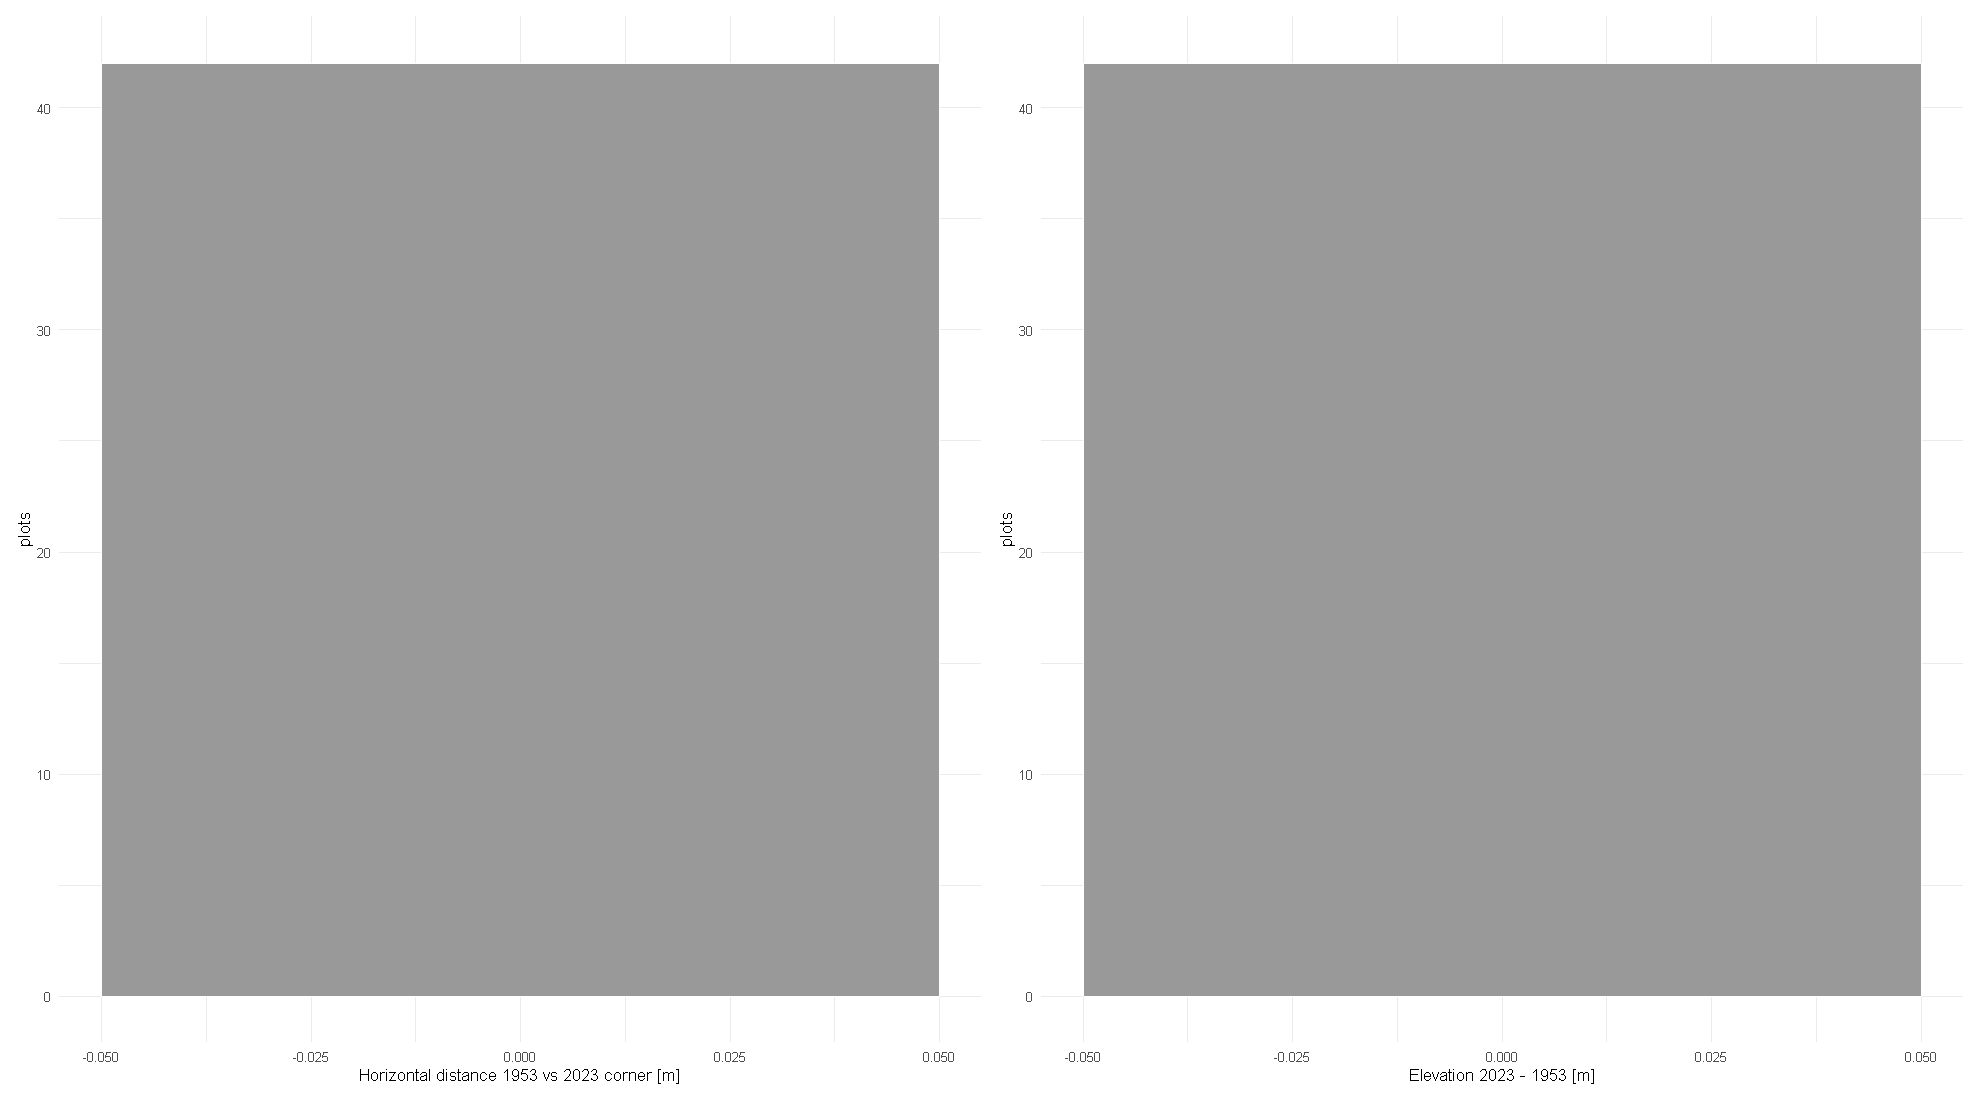

In [59]:
haversine <- function(lat1, lon1, lat2, lon2) {
  r <- 6371000; p <- pi / 180
  a <- sin((lat2 - lat1) * p / 2)^2 +
       cos(lat1 * p) * cos(lat2 * p) * sin((lon2 - lon1) * p / 2)^2
  2 * r * asin(sqrt(a))
}

reloc <- env %>%
  filter(base_id %in% paired_ids) %>%
  select(base_id, period, lat, lon, elevation) %>%
  pivot_wider(names_from = period, values_from = c(lat, lon, elevation)) %>%
  mutate(dist_m = haversine(lat_1953, lon_1953, lat_2023, lon_2023),
         elev_diff = elevation_2023 - elevation_1953)

summary(reloc$dist_m)
summary(reloc$elev_diff)

p1 <- ggplot(reloc, aes(dist_m)) + geom_histogram(bins = 20, fill = "grey60", colour = "white") +
  labs(x = "Horizontal distance 1953 vs 2023 corner [m]", y = "plots")
p2 <- ggplot(reloc, aes(elev_diff)) + geom_histogram(bins = 20, fill = "grey60", colour = "white") +
  labs(x = "Elevation 2023 - 1953 [m]", y = "plots")
p1 + p2

reloc %>% arrange(desc(dist_m)) %>% select(base_id, dist_m, elev_diff) %>% head(8) %>% kable(digits = 1,
  caption = "Plots with largest displacement (check these first)")

## 1.3 Internal consistency of the environmental table

name,value
sum_growth_min,1.000
sum_growth_max,1.000
sum_strategy_min,0.991
sum_strategy_max,1.000


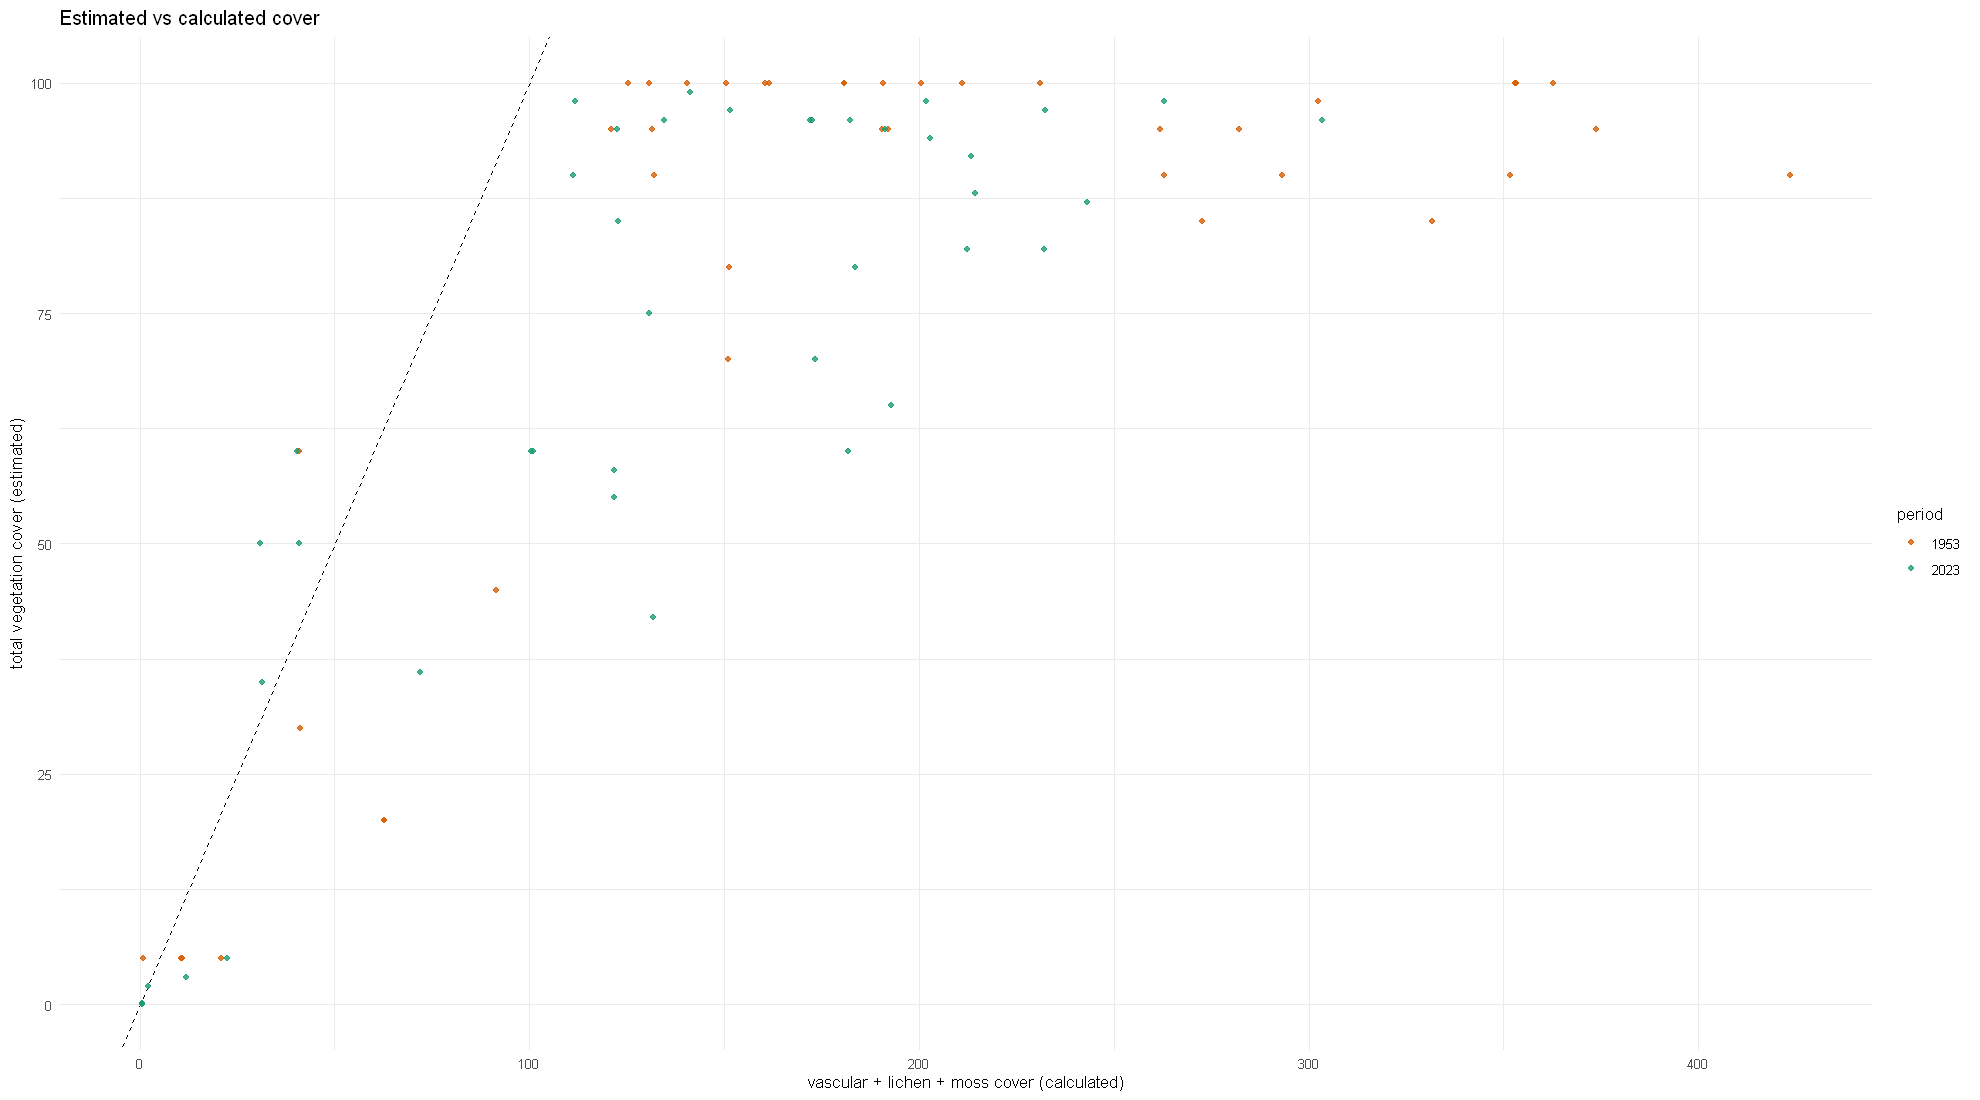

In [60]:
env %>%
  mutate(sum_growth   = rowSums(across(all_of(growth))),
         sum_strategy = rowSums(across(all_of(strategy)))) %>%
  summarise(across(c(sum_growth, sum_strategy), list(min = ~ min(.x, na.rm = TRUE), max = ~ max(.x, na.rm = TRUE)))) %>%
  pivot_longer(everything()) %>% kable(digits = 3,
  caption = "Relative cover of growth forms and CSR proportions should sum to ~1 (note: they are proportions, not %)")

env %>%
  mutate(cover_sum_calc = cover_vascular + cover_lichens + cover_mosses) %>%
  ggplot(aes(cover_sum_calc, cover_total, colour = period)) +
  geom_abline(slope = 1, linetype = 2) + geom_point(alpha = .8, na.rm = TRUE) +
  scale_colour_manual(values = period_cols) +
  labs(x = "vascular + lichen + moss cover (calculated)", y = "total vegetation cover (estimated)",
       title = "Estimated vs calculated cover")

# 2. Missing data and zeros

In [61]:
na_env <- env %>%
  summarise(across(everything(), ~ sum(is.na(.x)))) %>%
  pivot_longer(everything(), names_to = "variable", values_to = "n_na") %>%
  mutate(pct_na = round(100 * n_na / nrow(env), 2)) %>%
  arrange(desc(n_na))

na_env %>% filter(n_na > 0) %>% kable(caption = "Environmental table: variables with missing values")
cat("Total NA cells in species table:", sum(is.na(comm)), "\n")

# which rows are affected
env %>% filter(if_any(everything(), is.na)) %>%
  select(plot_id, year, where(~ anyNA(.x))) %>% kable(caption = "Rows with missing values")

variable,n_na,pct_na
cover_total,1,1.19


Total NA cells in species table: 0 


plot_id,year,cover_total
138,1953,NA


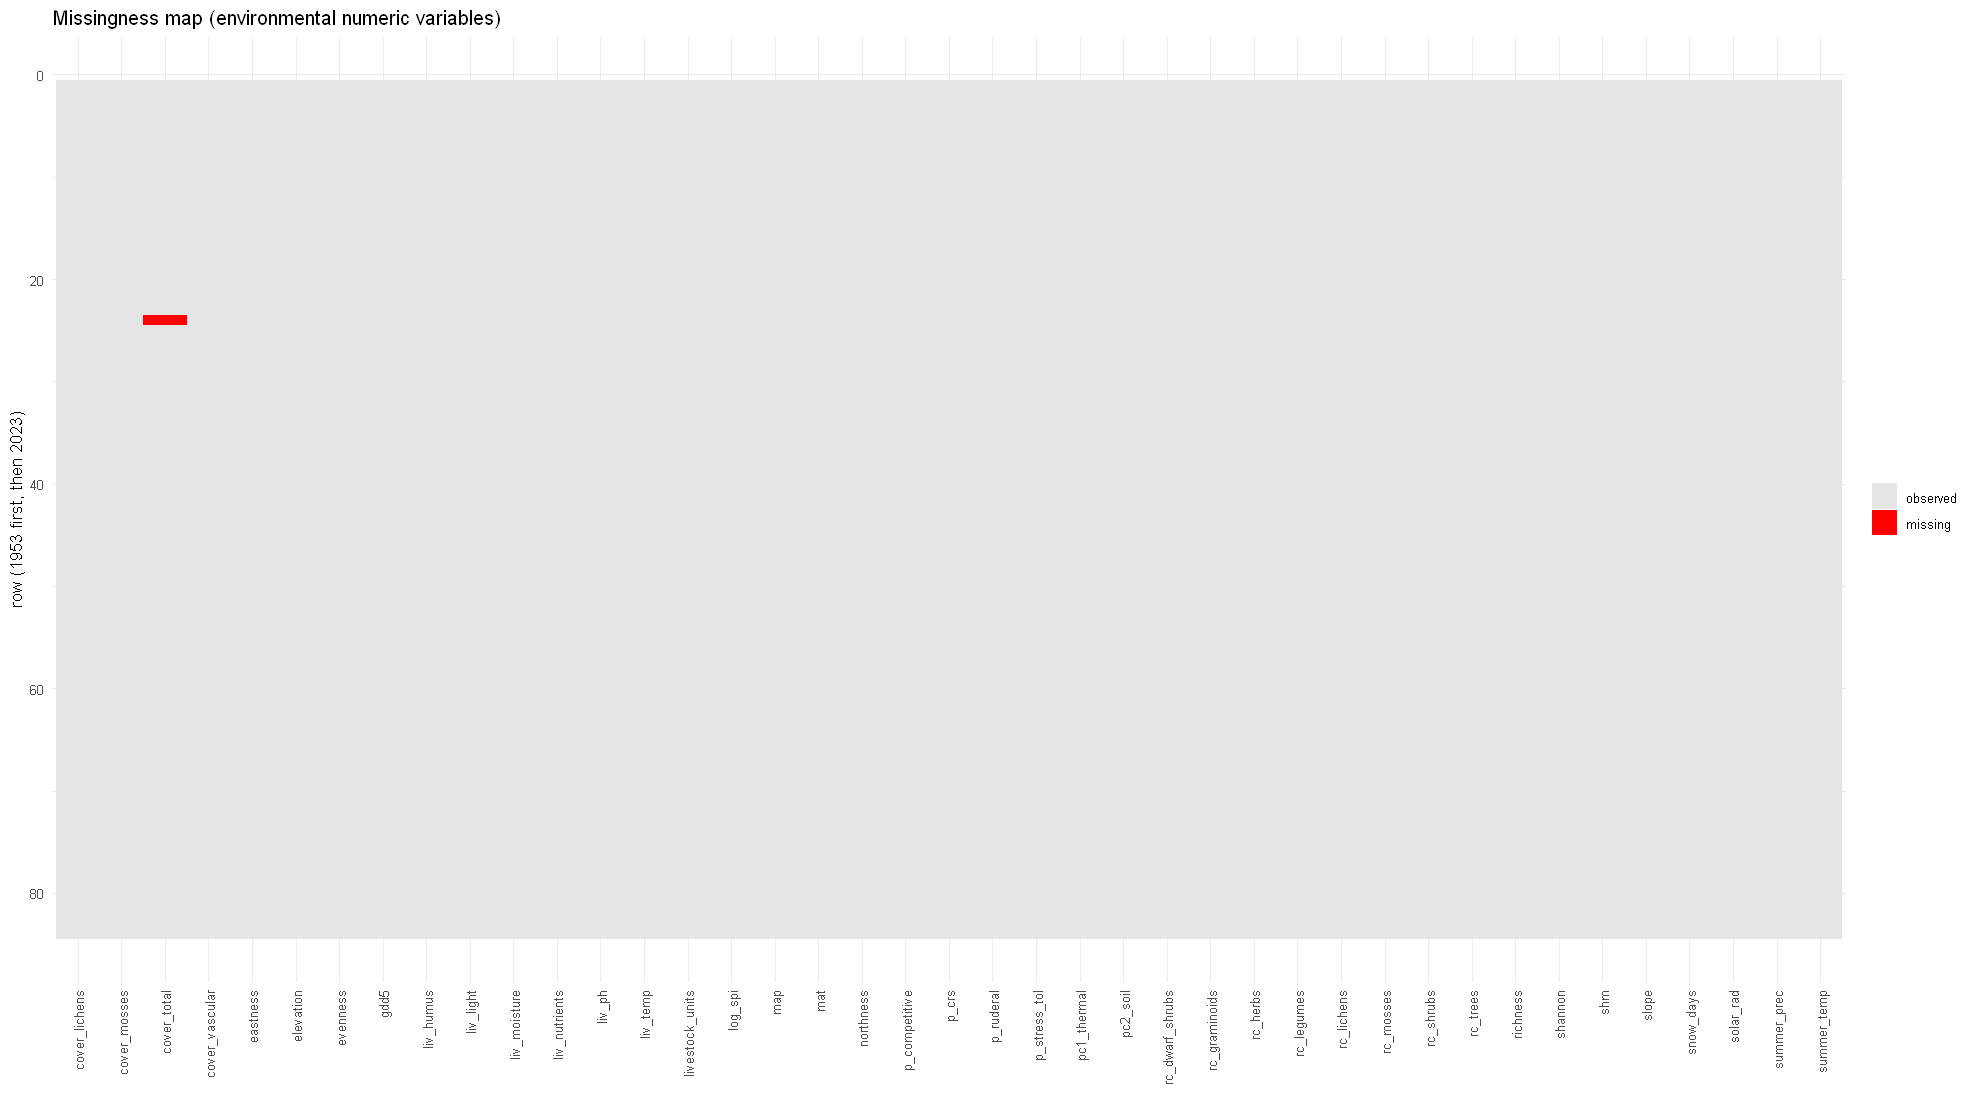

In [62]:
env %>%
  mutate(row = row_number()) %>%
  select(row, all_of(num_vars)) %>%
  pivot_longer(
    -row,
    names_to = "name",
    values_to = "value",
    values_transform = list(value = as.character)
  ) %>%
  ggplot(aes(name, row, fill = is.na(value))) +
  geom_tile() +
  scale_fill_manual(
    values = c("grey90", "red"),
    labels = c("observed", "missing"),
    name = NULL
  ) +
  scale_y_reverse() +
  labs(
    x = NULL,
    y = "row (1953 first, then 2023)",
    title = "Missingness map (environmental numeric variables)"
  ) +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = .5))

In [63]:
env %>%
  summarise(across(all_of(num_vars), ~ mean(.x == 0, na.rm = TRUE) * 100)) %>%
  pivot_longer(everything(), names_to = "variable", values_to = "pct_zero") %>%
  filter(pct_zero > 0) %>% arrange(desc(pct_zero)) %>%
  kable(digits = 1, caption = "% of plots where the variable is exactly 0")

env %>%
  group_by(period) %>%
  summarise(across(all_of(num_vars), n_distinct)) %>%
  pivot_longer(-period, names_to = "variable", values_to = "n_unique") %>%
  filter(n_unique <= 2) %>%
  kable(caption = "Variables with <= 2 distinct values within a period (near-constant: check before modelling)")

variable,pct_zero
rc_trees,94.0
rc_shrubs,85.7
p_ruderal,59.5
rc_legumes,58.3
cover_lichens,51.2
rc_lichens,51.2
cover_mosses,38.1
rc_dwarf_shrubs,38.1
rc_mosses,36.9
livestock_units,28.6


period,variable,n_unique
1953,livestock_units,1
1953,rc_trees,2
2023,livestock_units,2


# 3. Environmental variables

## 3.1 Summary table by period

In [64]:
env %>%
  select(all_of(num_vars)) %>%
  summarise(across(everything(), ~ class(.x))) %>%
  pivot_longer(everything(), names_to = "variable", values_to = "class") %>%
  filter(class != "numeric")

variable,class
<chr>,<chr>


In [65]:
env <- env %>%
  mutate(cover_total = as.numeric(cover_total))

In [66]:
env_summary <- env %>%
  select(period, all_of(num_vars)) %>%
  pivot_longer(-period, names_to = "variable") %>%
  group_by(variable, period) %>%
  summarise(n = sum(!is.na(value)), mean = mean(value, na.rm = TRUE), sd = sd(value, na.rm = TRUE),
            median = median(value, na.rm = TRUE), min = min(value, na.rm = TRUE),
            max = max(value, na.rm = TRUE), .groups = "drop") %>%
  mutate(variable = factor(variable, levels = num_vars)) %>% arrange(variable, period)

env_summary %>% mutate(across(where(is.numeric), ~ round(.x, 3)))
write_csv(env_summary, "outputs/env_summary_by_period.csv")

variable,period,n,mean,sd,median,min,max
<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
elevation,1953,42,2534.288,193.074,2608.850,2005.200,2744.200
elevation,2023,42,2534.288,193.074,2608.850,2005.200,2744.200
slope,1953,42,19.345,12.526,20.205,0.000,59.830
slope,2023,42,19.345,12.526,20.205,0.000,59.830
eastness,1953,42,-0.149,0.665,-0.340,-0.980,1.000
eastness,2023,42,-0.149,0.665,-0.340,-0.980,1.000
northness,1953,42,-0.099,0.743,-0.260,-1.000,1.000
northness,2023,42,-0.099,0.743,-0.260,-1.000,1.000
log_spi,1953,42,4.003,1.663,4.230,0.010,7.750


## 3.2 Distributions by period

In [67]:
plot_dist <- function(vars, ncol = 4) {
  env %>% select(period, all_of(vars)) %>% pivot_longer(-period) %>%
    ggplot(aes(value, fill = period, colour = period)) +
    geom_density(alpha = .35, na.rm = TRUE) +
    facet_wrap(~ name, scales = "free", ncol = ncol) +
    scale_fill_manual(values = period_cols) + scale_colour_manual(values = period_cols) +
    labs(x = NULL, y = "density")
}
plot_box <- function(vars, ncol = 4) {
  env %>% select(period, all_of(vars)) %>% pivot_longer(-period) %>%
    ggplot(aes(period, value, fill = period)) +
    geom_boxplot(outlier.shape = NA, alpha = .5, na.rm = TRUE) +
    geom_jitter(width = .12, size = 1, alpha = .6, na.rm = TRUE) +
    facet_wrap(~ name, scales = "free_y", ncol = ncol) +
    scale_fill_manual(values = period_cols) + guides(fill = "none") + labs(x = NULL, y = NULL)
}

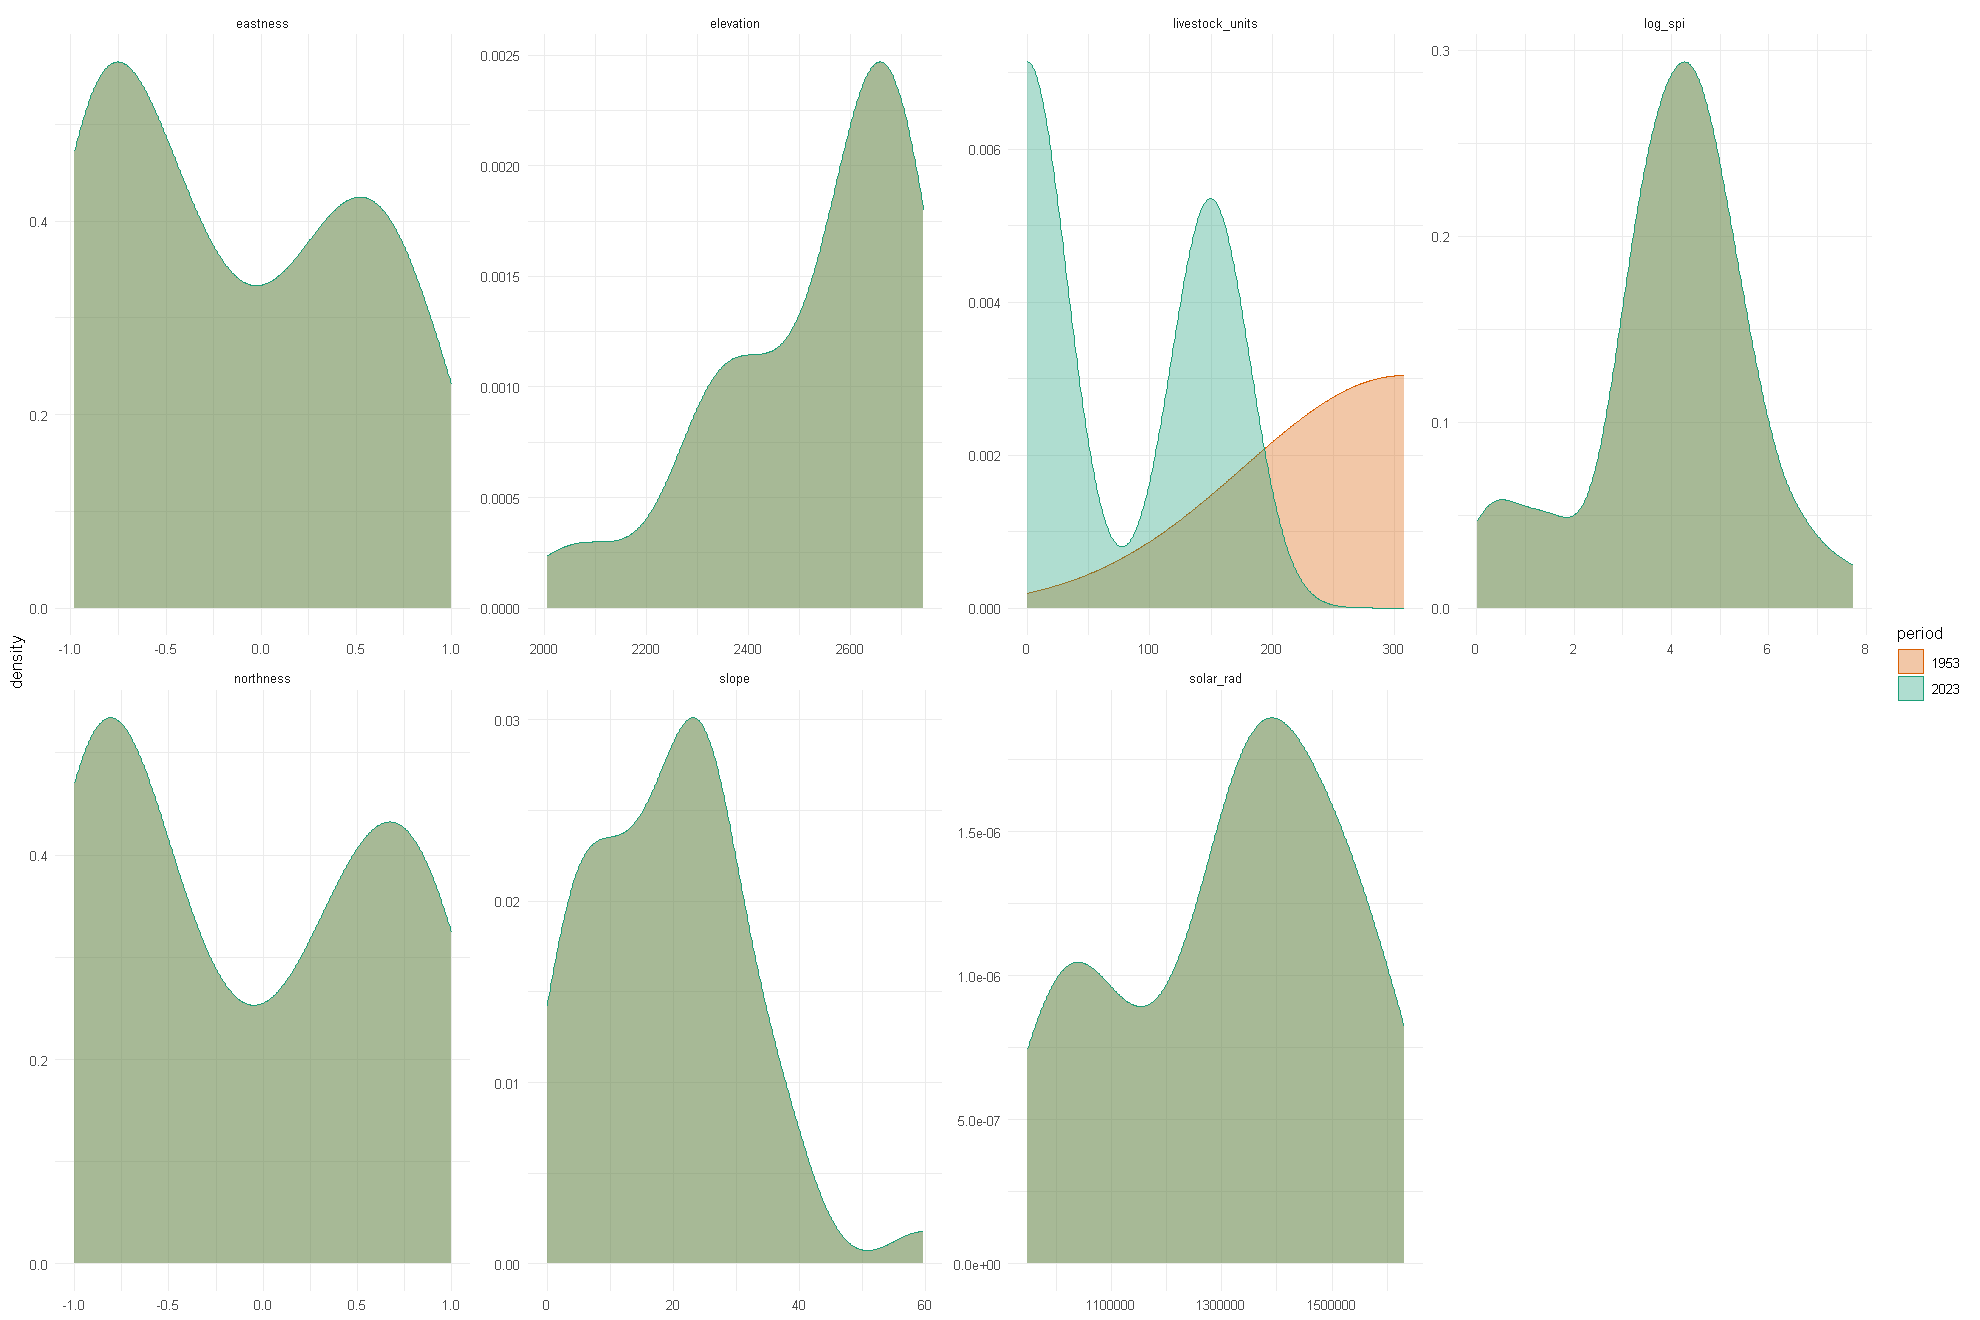

In [68]:
options(repr.plot.width = 18, repr.plot.height = 12)
plot_dist(topo)

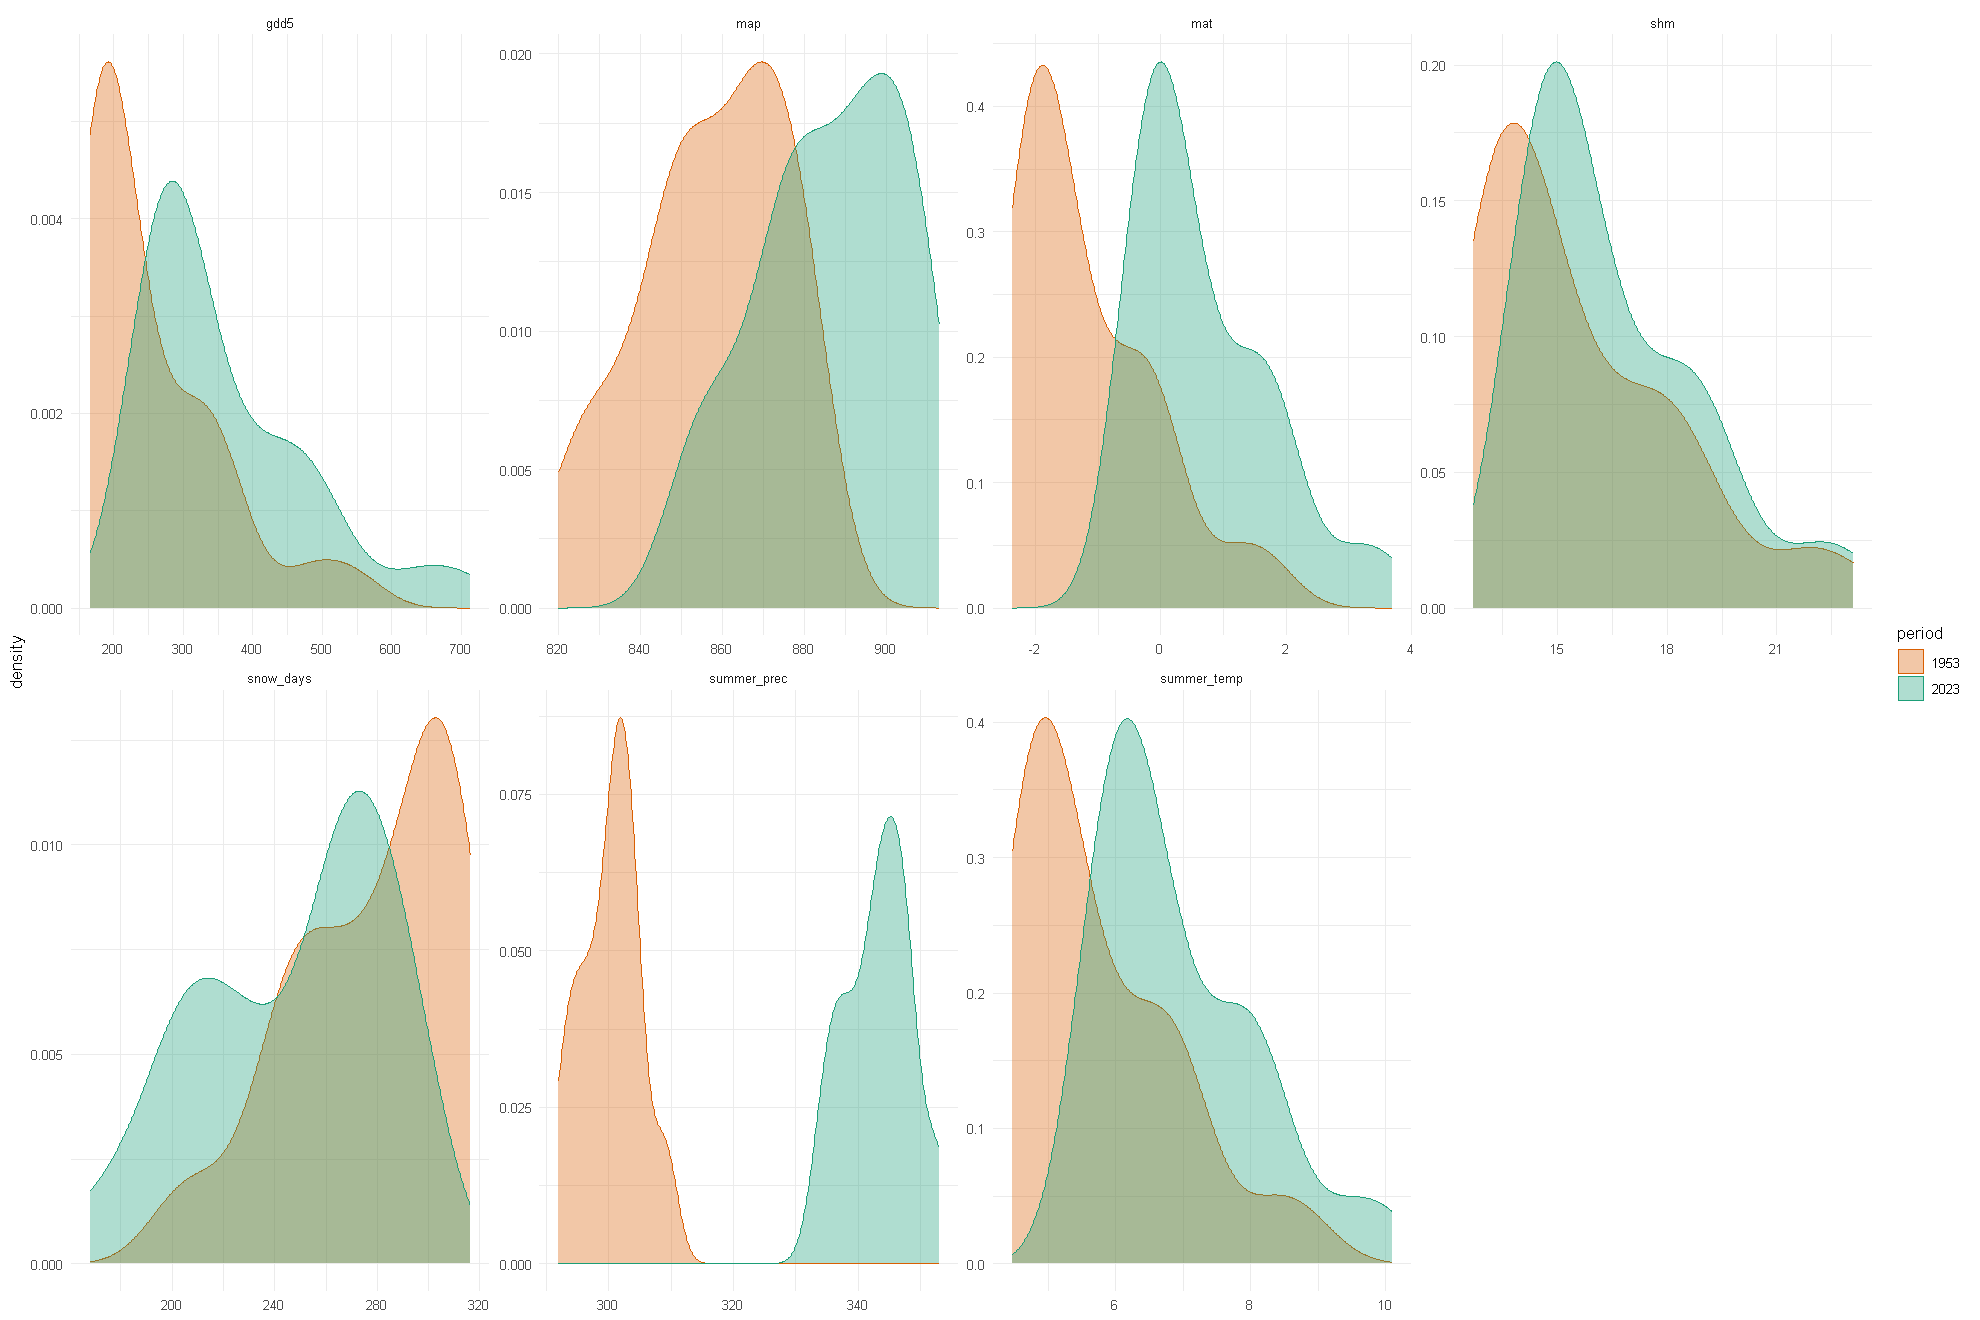

In [69]:
plot_dist(climate)

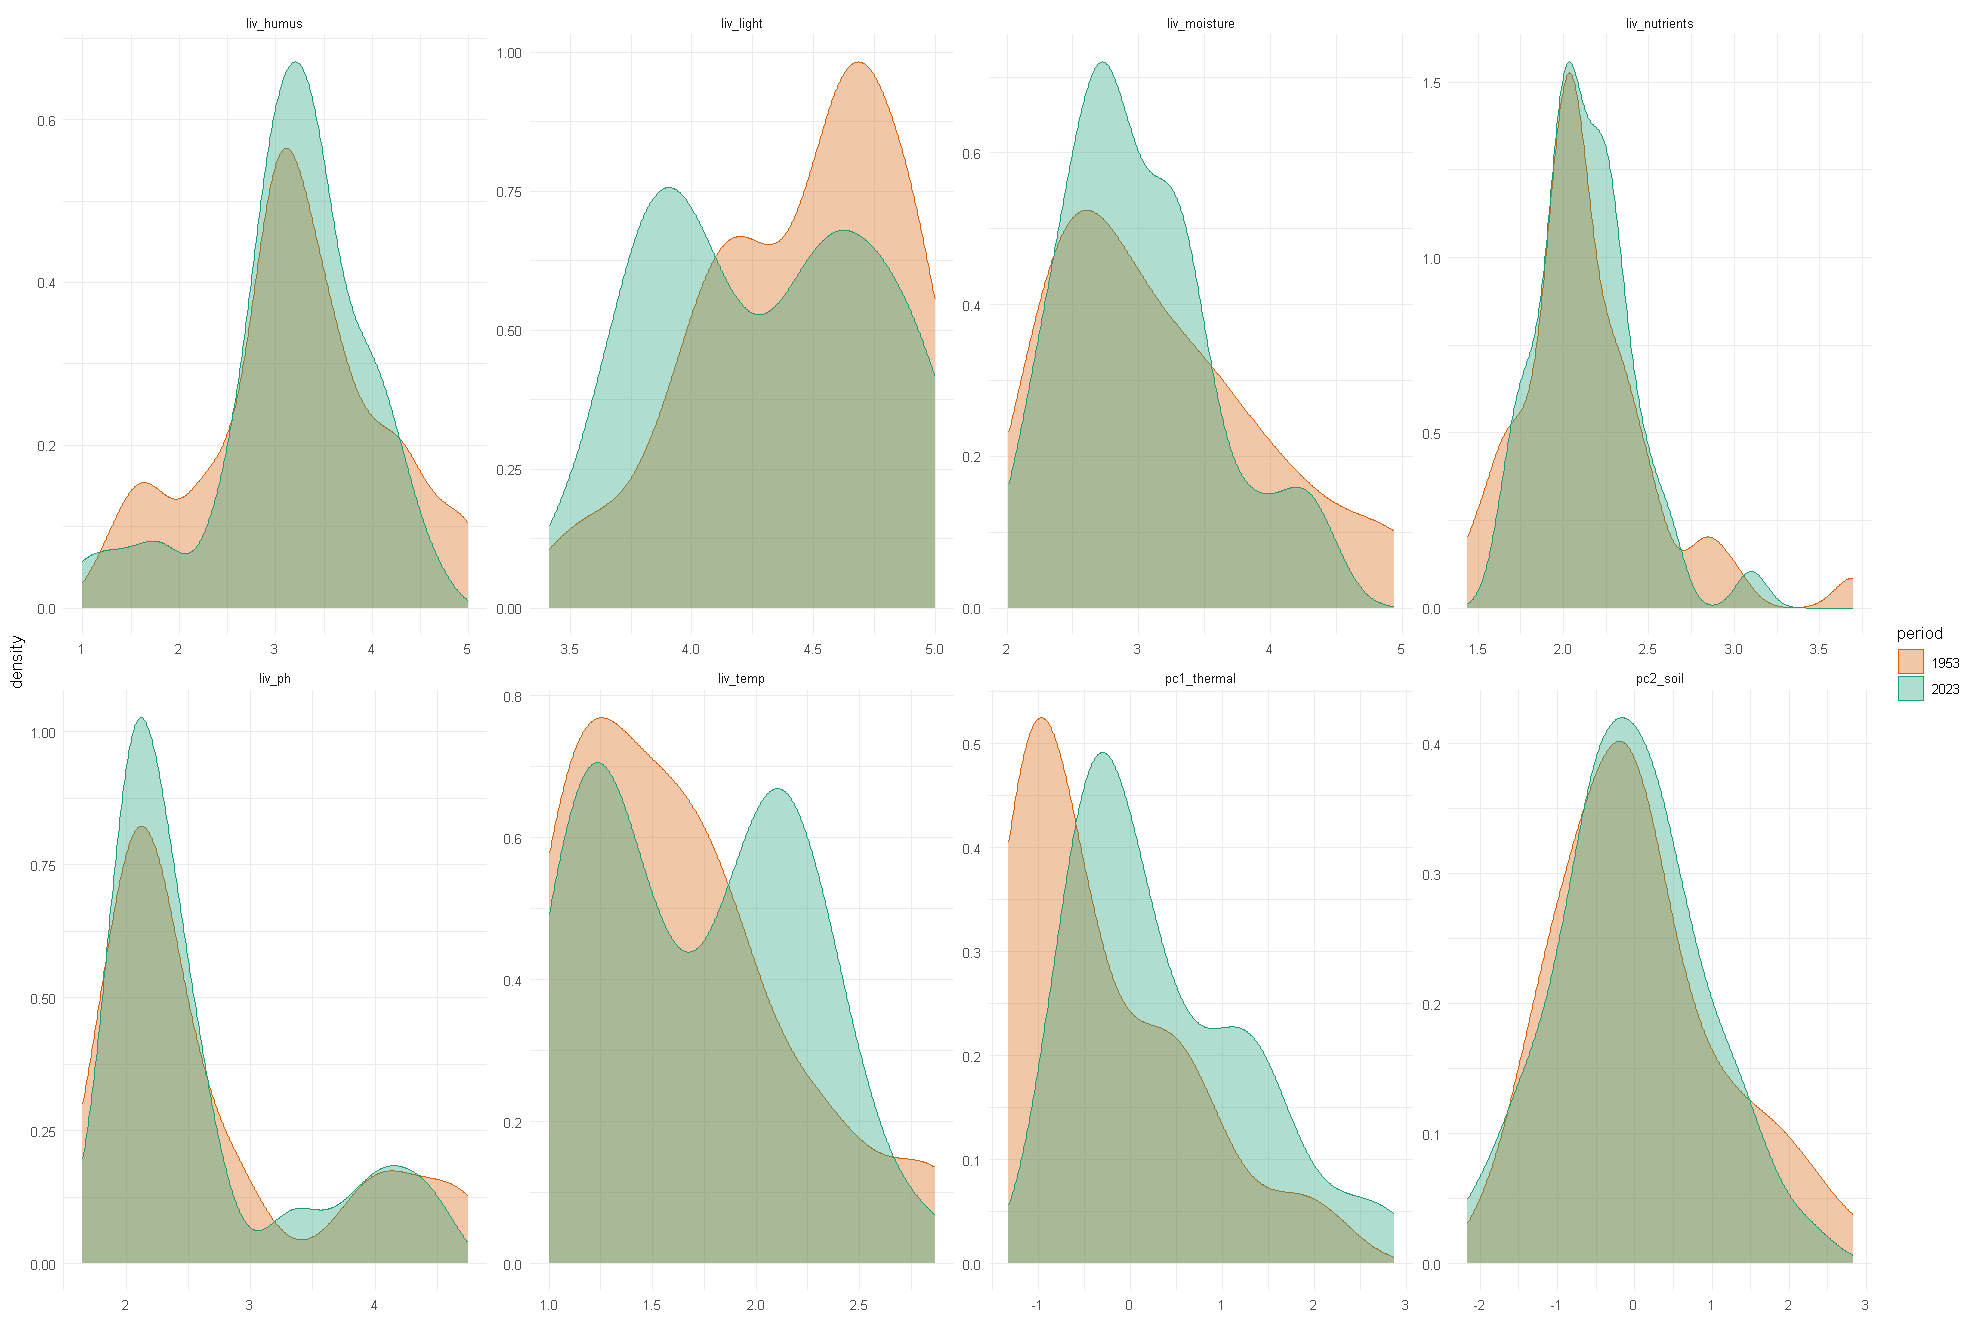

In [70]:
plot_dist(liv)

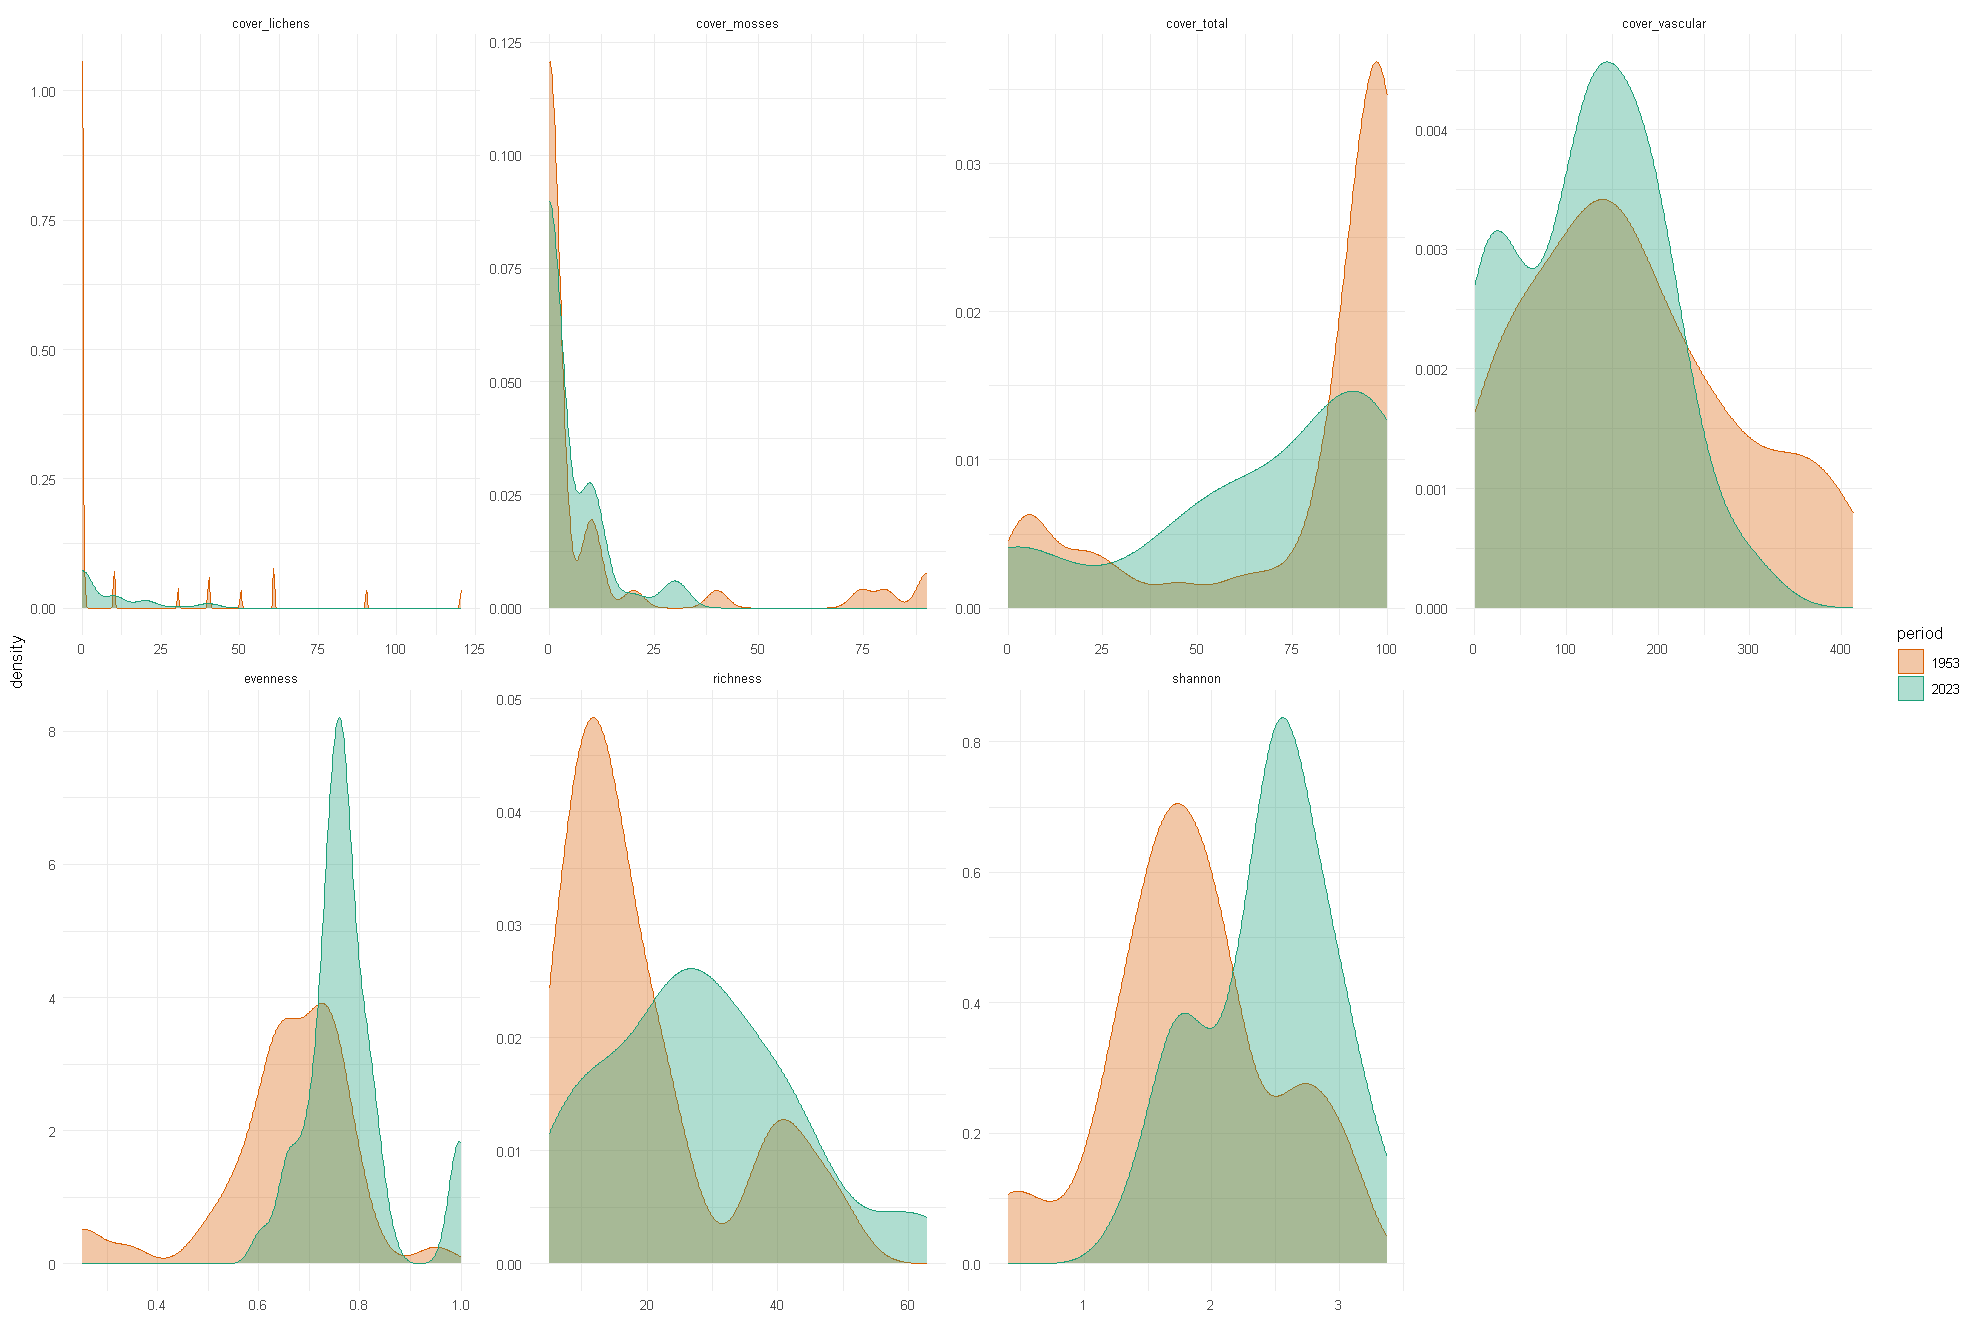

In [71]:
plot_dist(diversity)

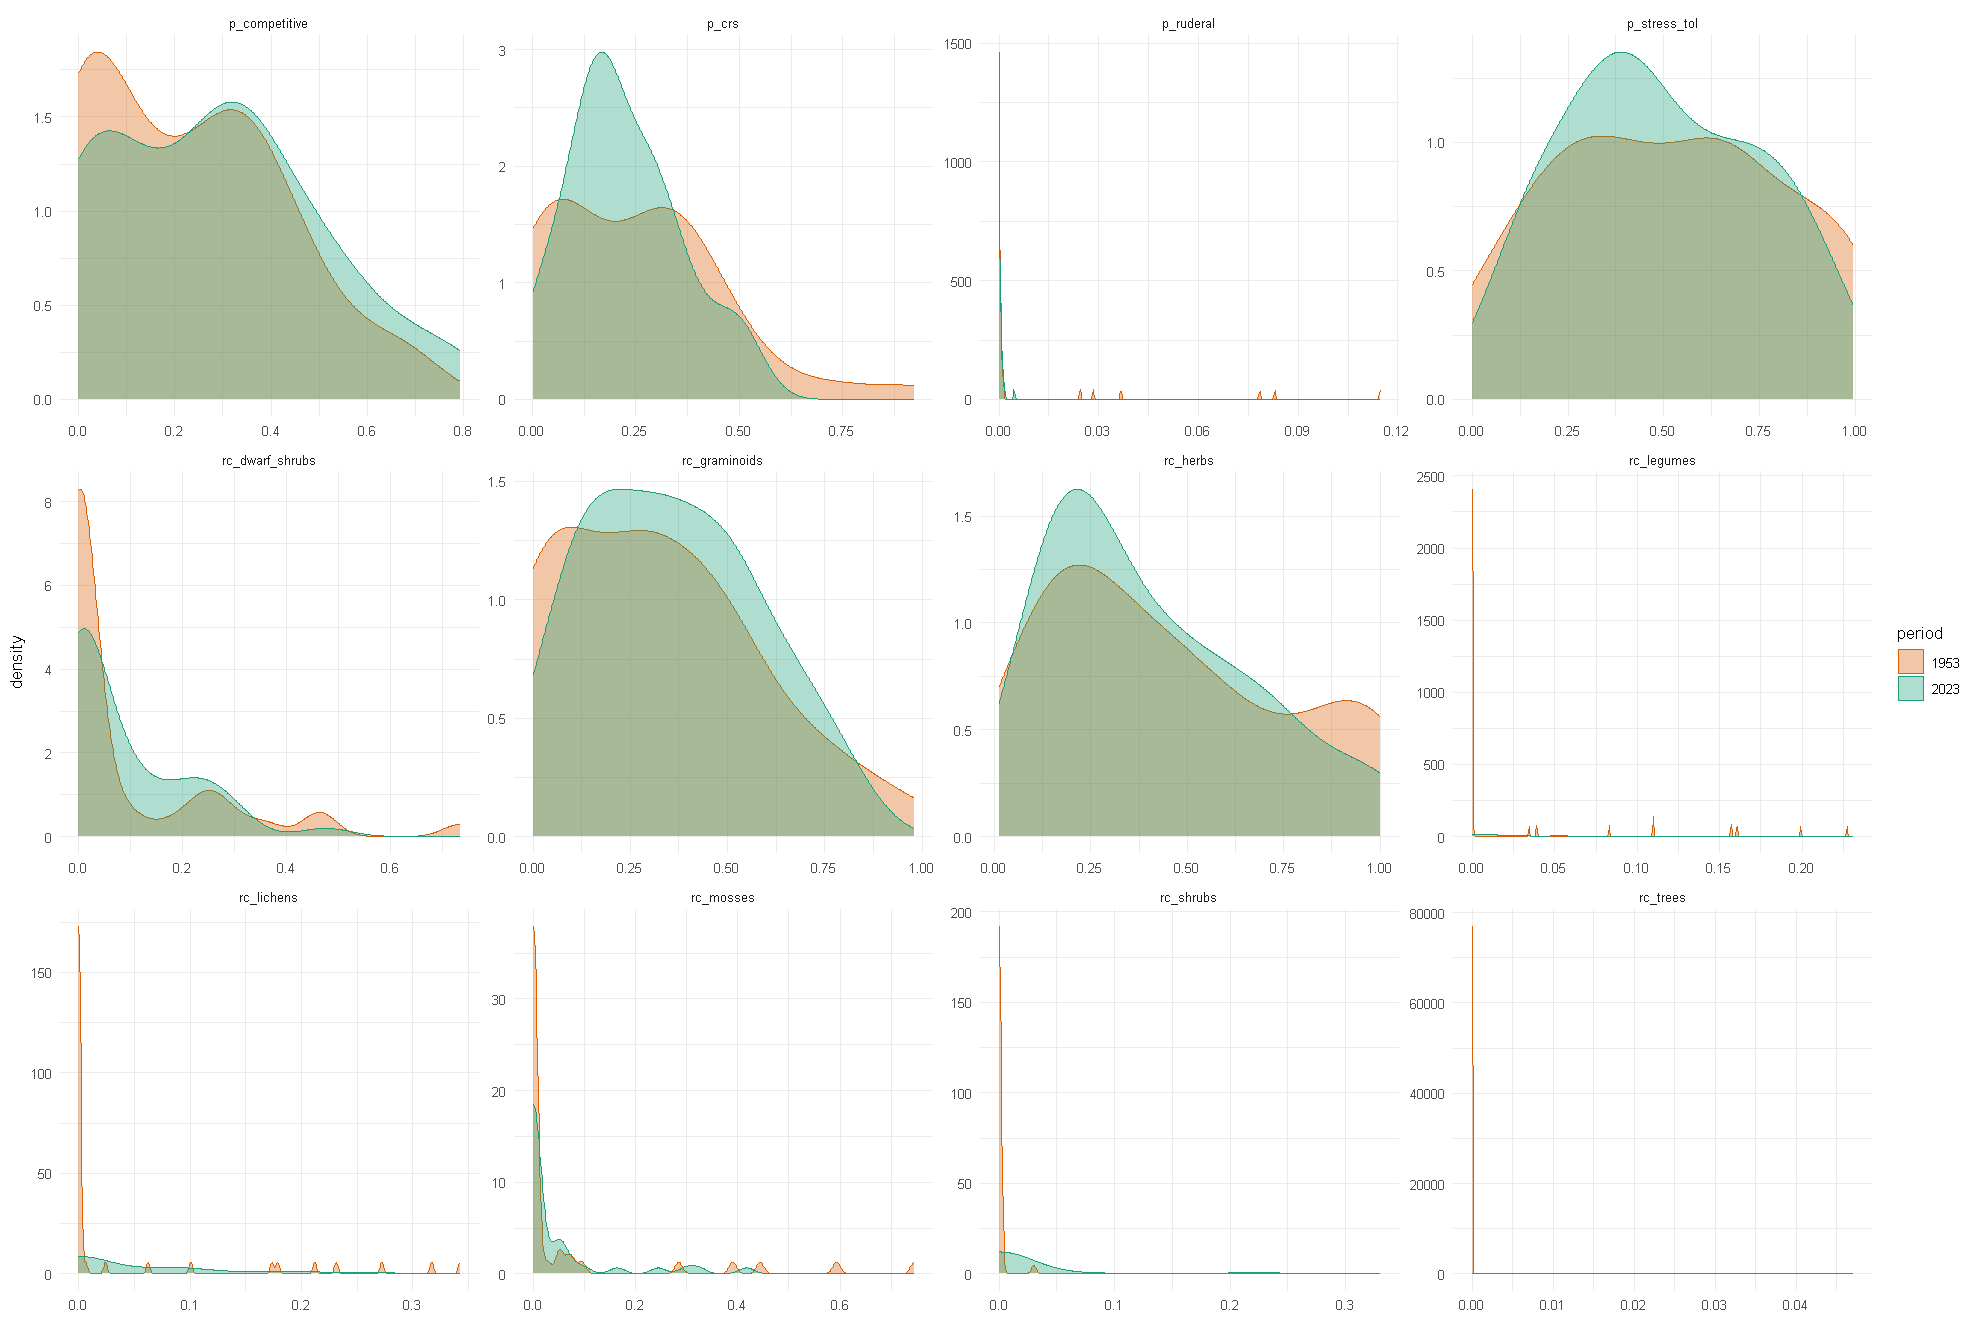

In [72]:
plot_dist(c(growth, strategy), ncol = 4)

## 3.3 Boxplots by period

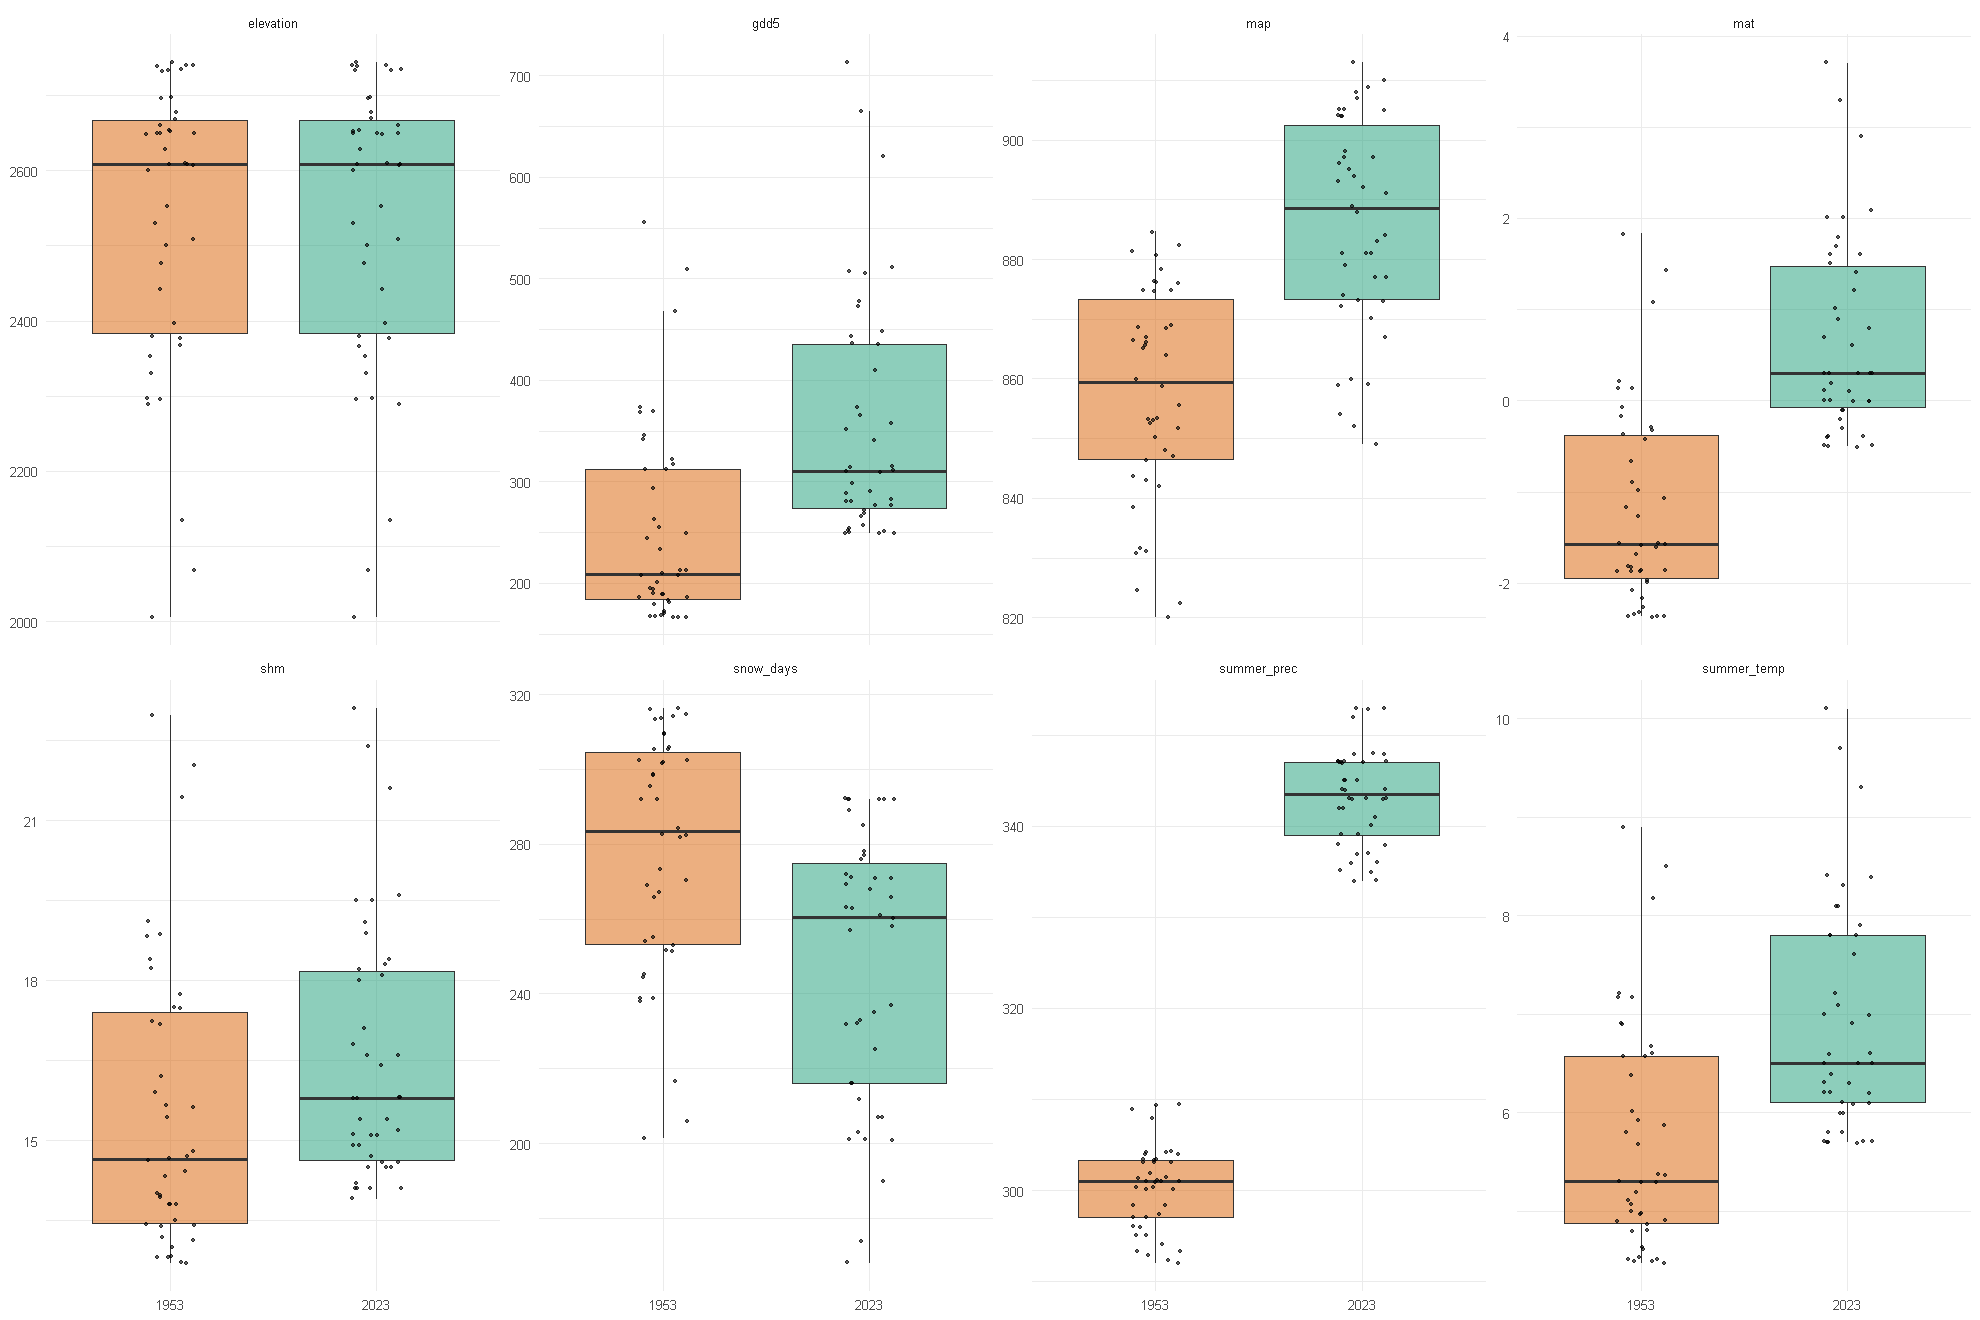

In [73]:
plot_box(c(climate, "elevation"))

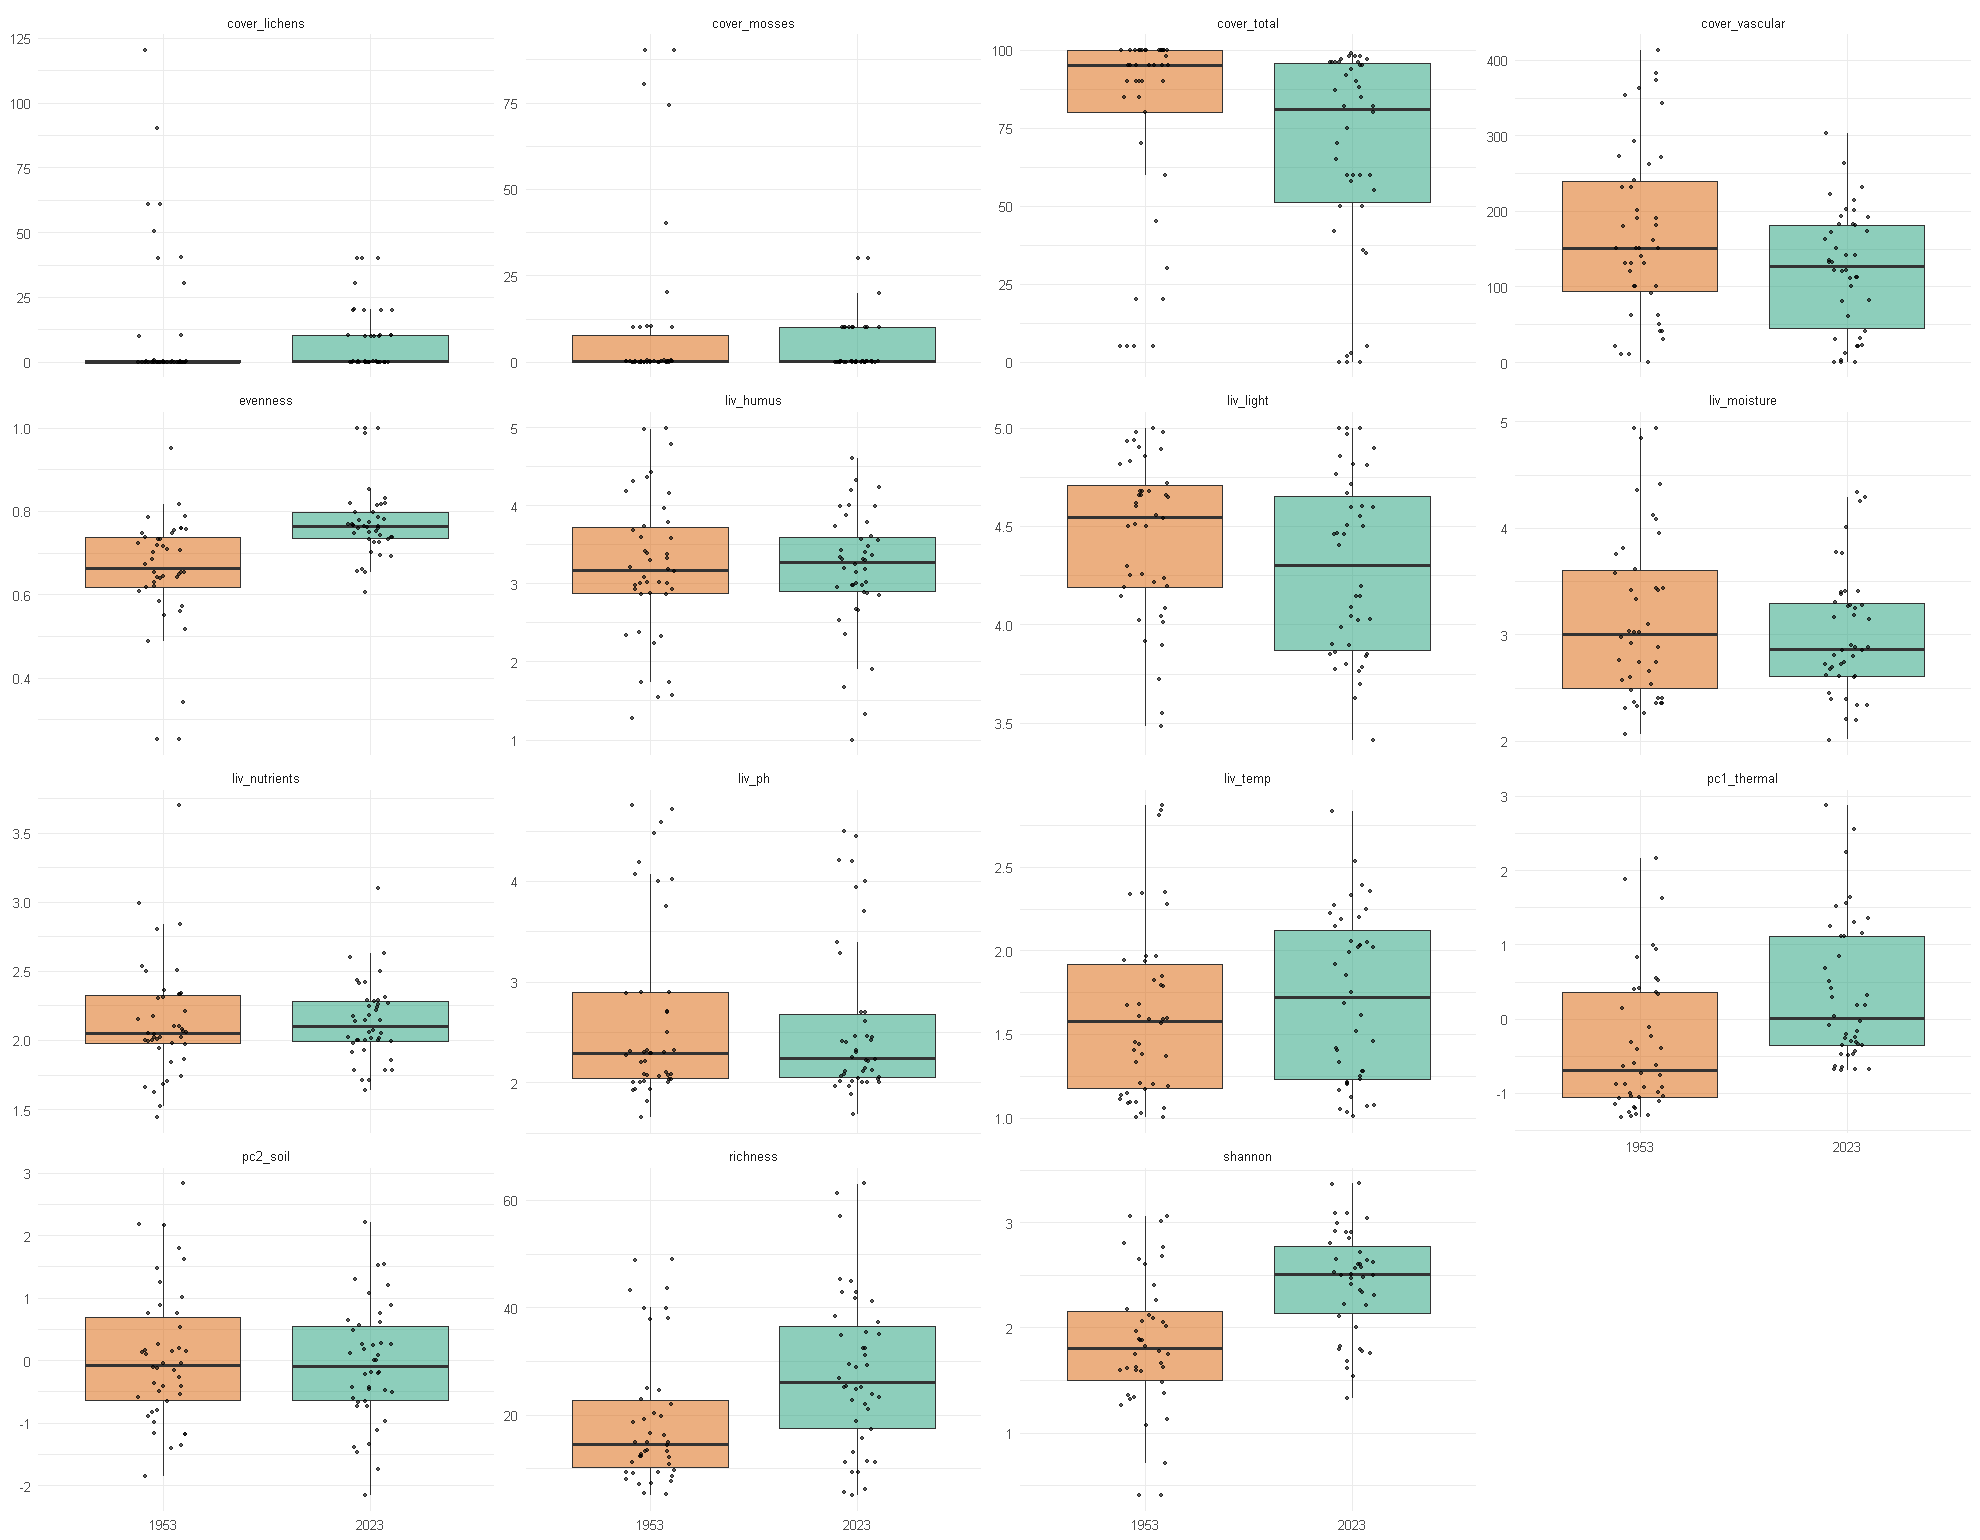

In [74]:
options(repr.plot.width = 18, repr.plot.height = 14)
plot_box(c(liv, diversity))

## 3.4 Categorical variables

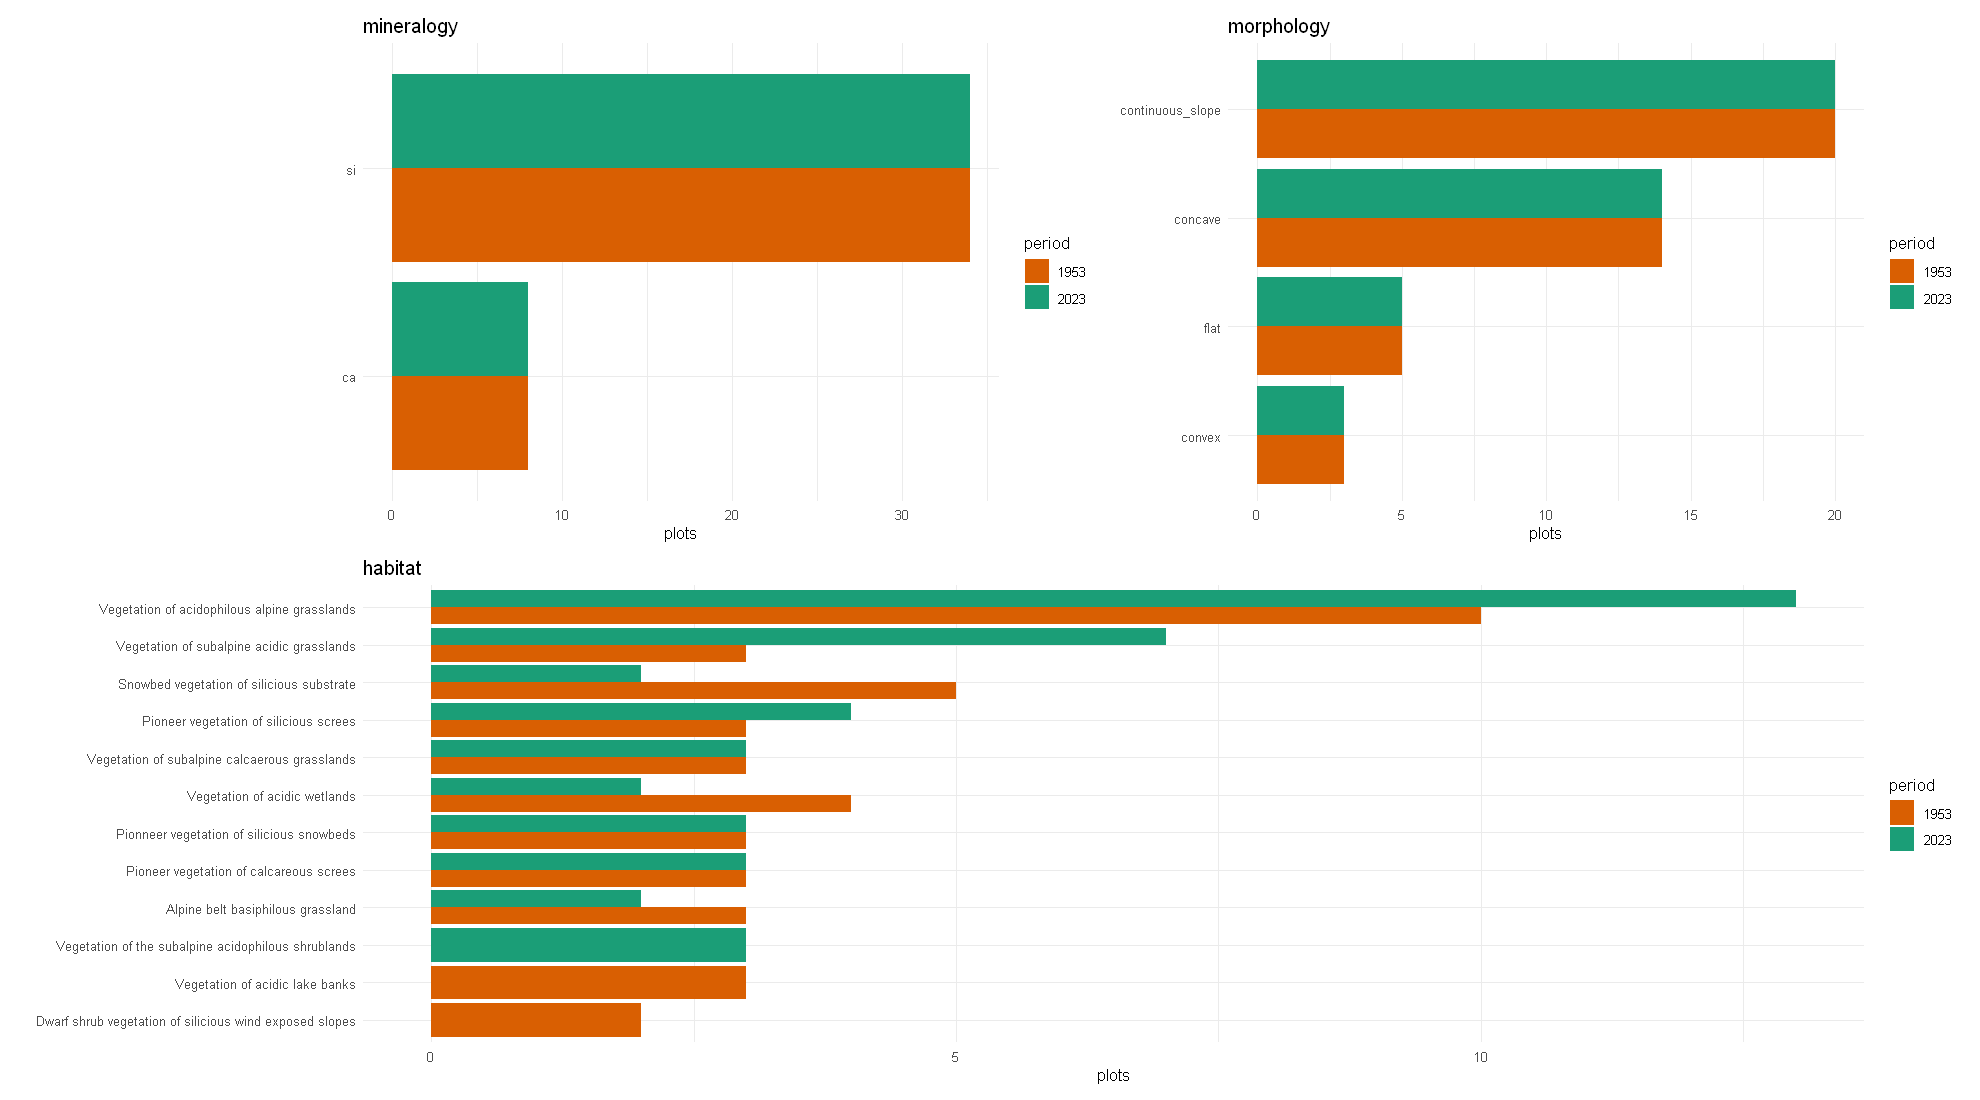

In [75]:
options(repr.plot.width = 18, repr.plot.height = 10)
cat_plot <- function(var) {
  env %>% count(period, .data[[var]]) %>%
    ggplot(aes(n, reorder(.data[[var]], n, sum), fill = period)) +
    geom_col(position = "dodge") + scale_fill_manual(values = period_cols) +
    labs(x = "plots", y = NULL, title = var)
}
(cat_plot("mineralogy") + cat_plot("morphology")) / cat_plot("habitat")

Check how abbreviations map to full association names (inconsistent labels show up as
an abbreviation with several names, or a name with several abbreviations):

In [76]:
env %>% count(assoc_abbr, association) %>% arrange(assoc_abbr) %>% kable()

assoc_abbr,association,n
CC,Caricetum curvulae,6
CF,Caricetum goodenowii,3
CF_D,Caricetum goodenowii degraded,3
CFi,Caricetum firmae,5
DP,Deschampsio cespitosae-Poetum alpinae,5
ES,Eriophoretum scheuchzeri,3
FH,Festucetum halleri,8
FV,Pulsatillo albae-Festucion variae,1
LC,Loiseleurieto-Cetrarietum,2
LC/CC,Loiseleurio-Caricetum curvulae,8


Did the plot's association change between 1953 and 2023?

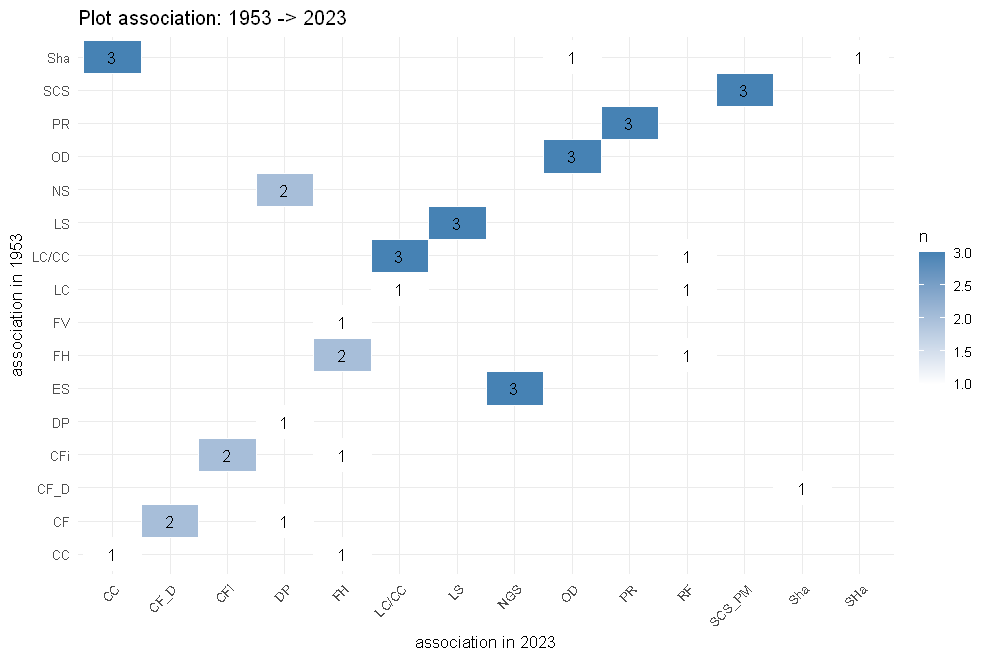

In [77]:
options(repr.plot.width = 9, repr.plot.height = 6)
assoc_shift <- env %>%
  filter(base_id %in% paired_ids) %>%
  mutate(assoc_abbr = as.character(assoc_abbr)) %>%
  select(base_id, period, assoc_abbr) %>%
  pivot_wider(names_from = period, values_from = assoc_abbr, names_prefix = "y") %>%
  count(y1953, y2023)

ggplot(assoc_shift, aes(y2023, y1953, fill = n)) +
  geom_tile(colour = "white") + geom_text(aes(label = n)) +
  scale_fill_gradient(low = "white", high = "steelblue") +
  labs(x = "association in 2023", y = "association in 1953",
       title = "Plot association: 1953 -> 2023") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

## 3.5 Spatial layout

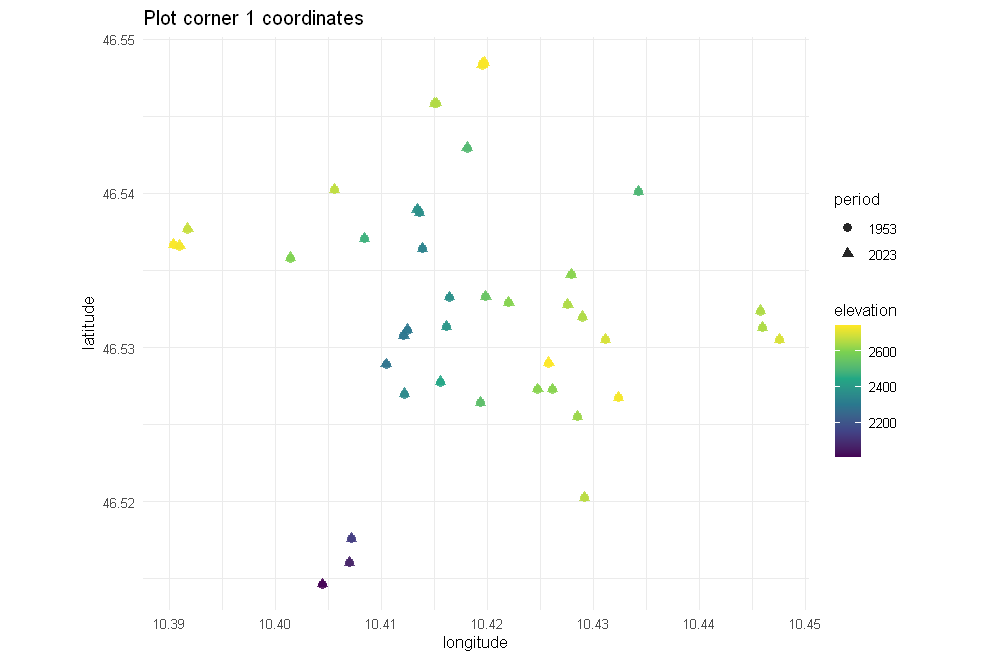

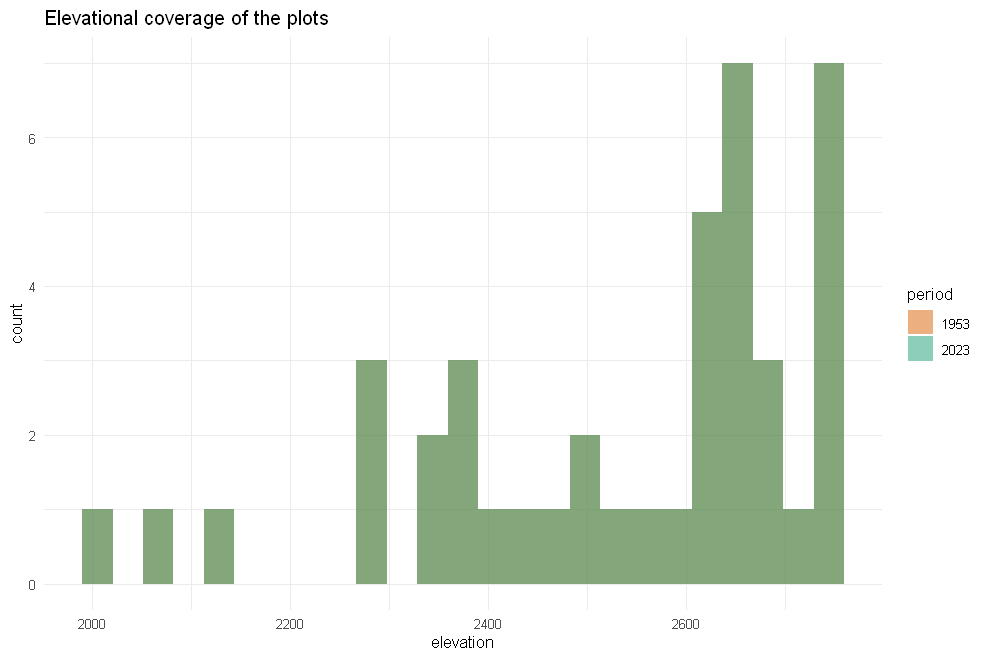

In [78]:
ggplot(env, aes(lon, lat, colour = elevation, shape = period)) +
  geom_point(size = 2.5, alpha = .85) + coord_quickmap() +
  scale_colour_viridis_c() +
  labs(title = "Plot corner 1 coordinates", x = "longitude", y = "latitude")

ggplot(env, aes(elevation, fill = period)) +
  geom_histogram(bins = 25, position = "identity", alpha = .5) +
  scale_fill_manual(values = period_cols) + labs(title = "Elevational coverage of the plots")

## 3.6 Correlations among variables

v1,v2,r
summer_temp,gdd5,1.00
cover_lichens,rc_lichens,0.99
summer_temp,pc1_thermal,0.99
summer_temp,snow_days,-0.98
snow_days,pc1_thermal,-0.98
gdd5,pc1_thermal,0.98
gdd5,snow_days,-0.98
shm,snow_days,-0.98
shm,pc1_thermal,0.97
mat,gdd5,0.96


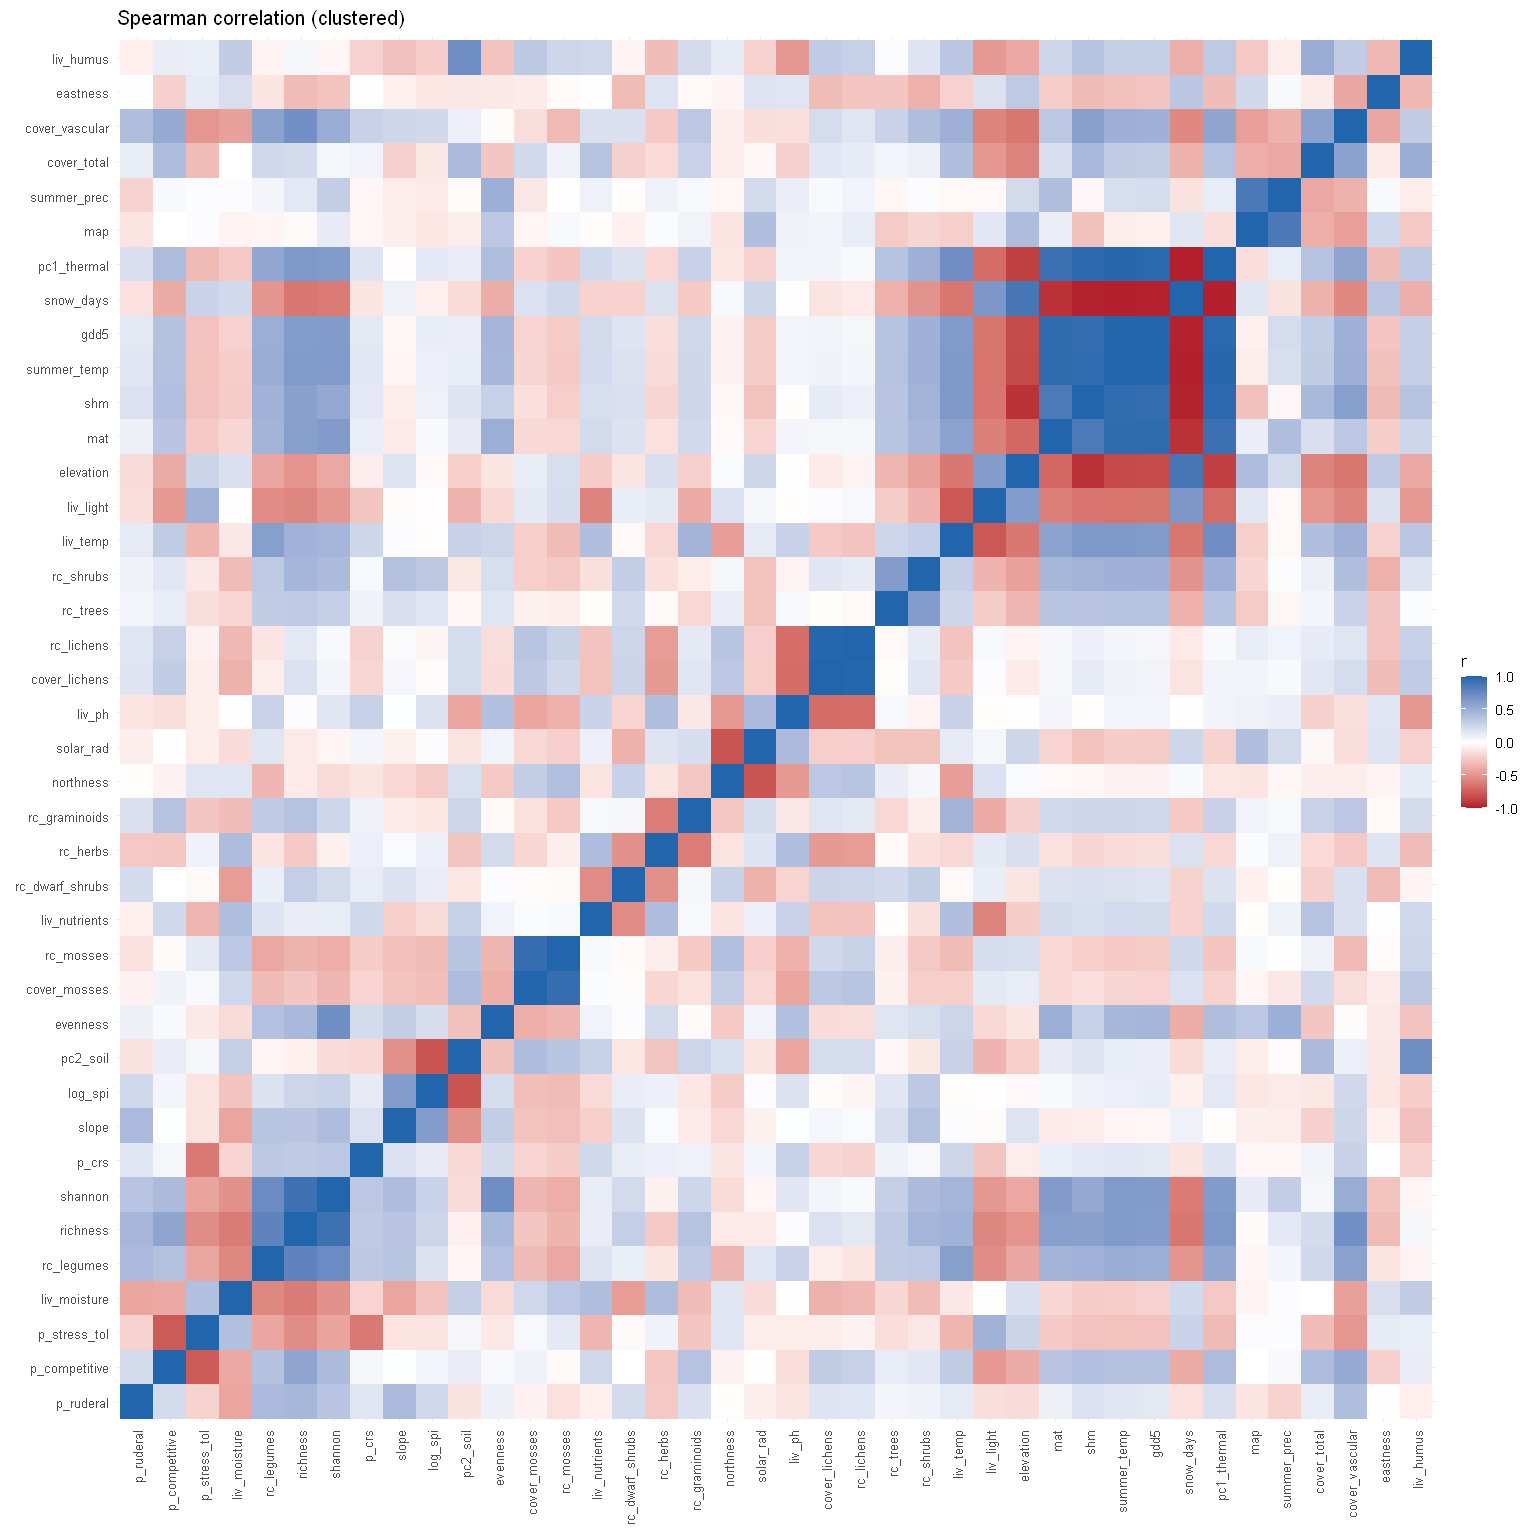

In [79]:
options(repr.plot.width = 14, repr.plot.height = 14)
corr_vars <- setdiff(num_vars, "livestock_units")
cm <- env %>% select(all_of(corr_vars)) %>% cor(use = "pairwise.complete.obs", method = "spearman")
cm[is.na(cm)] <- 0
ord <- hclust(as.dist(1 - abs(cm)))$order
cm_long <- as.data.frame(as.table(cm[ord, ord])) %>% rename(v1 = Var1, v2 = Var2, r = Freq)

ggplot(cm_long, aes(v1, v2, fill = r)) + geom_tile() +
  scale_fill_gradient2(low = "#B2182B", mid = "white", high = "#2166AC", limits = c(-1, 1)) +
  labs(x = NULL, y = NULL, title = "Spearman correlation (clustered)") +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = .5))

cm_long %>% filter(as.integer(v1) < as.integer(v2), abs(r) >= 0.85) %>%
  arrange(desc(abs(r))) %>% mutate(r = round(r, 2)) %>%
  kable(caption = "Highly collinear pairs (|rho| >= 0.85)")

## 3.7 PCA of the environment

,PC1,PC2,PC3,PC4,PC5
Standard deviation,2.678,1.695,1.521,1.438,1.095
Proportion of Variance,0.377,0.151,0.122,0.109,0.063
Cumulative Proportion,0.377,0.529,0.650,0.759,0.822


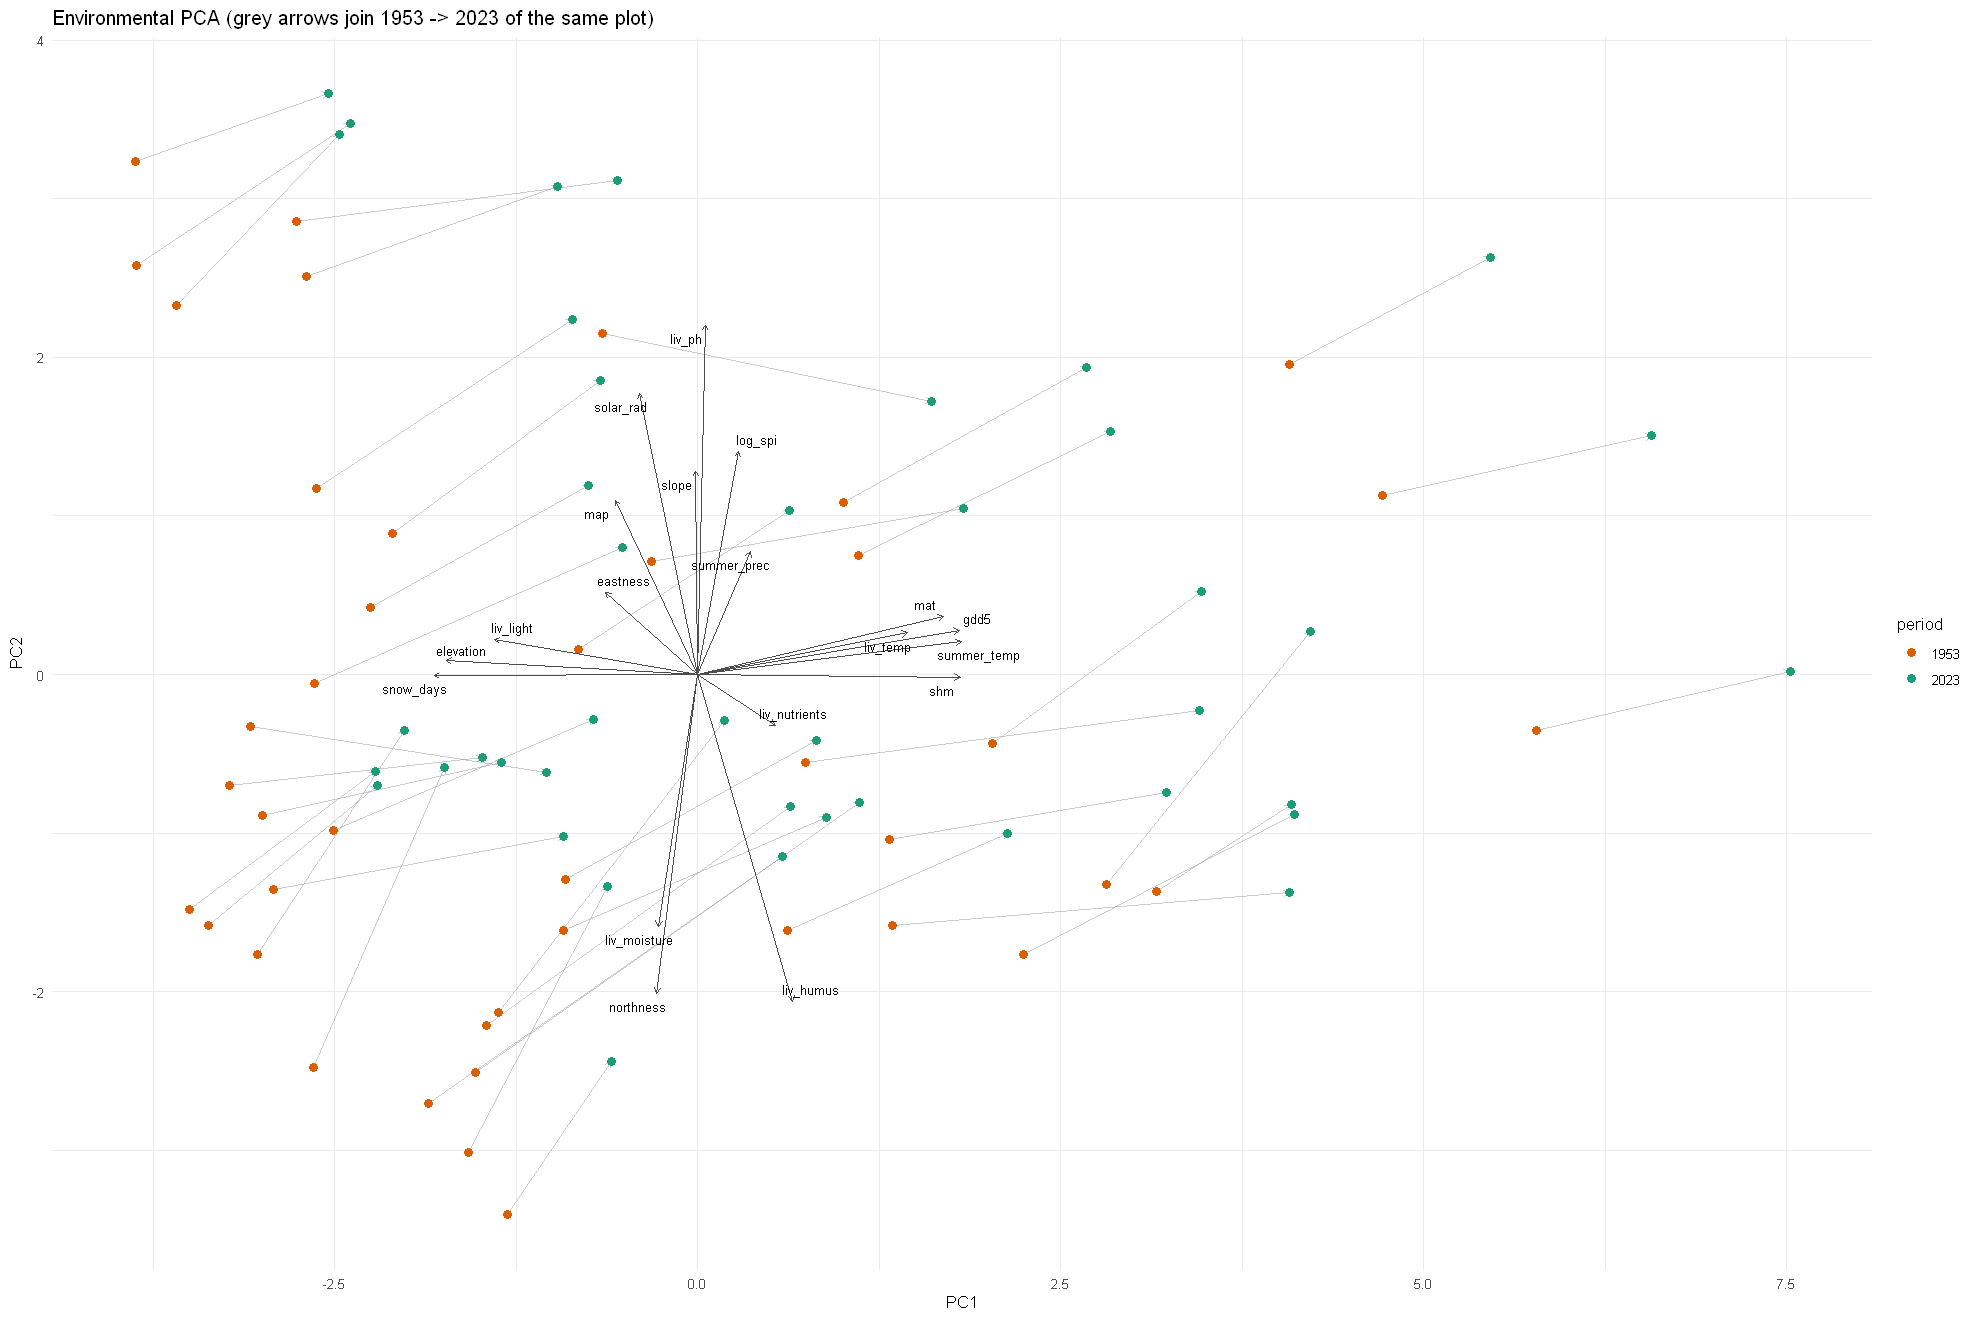

In [80]:
options(repr.plot.width = 18, repr.plot.height = 12)
pca_vars <- c(setdiff(topo, "livestock_units"), climate, liv[1:6])
pca_df <- env %>% select(base_id, plot_id, period, all_of(pca_vars)) %>% drop_na()
pca <- prcomp(pca_df %>% select(all_of(pca_vars)), scale. = TRUE)

round(summary(pca)$importance[, 1:5], 3) %>% kable(caption = "Variance explained")

sc <- bind_cols(pca_df %>% select(base_id, period), as_tibble(pca$x[, 1:2]))
ld <- as_tibble(pca$rotation[, 1:2], rownames = "variable")

ggplot(sc, aes(PC1, PC2)) +
  geom_path(aes(group = base_id), colour = "grey60", alpha = .5,
            arrow = arrow(length = unit(1.5, "mm"))) +
  geom_point(aes(colour = period), size = 2.5) +
  geom_segment(data = ld, aes(x = 0, y = 0, xend = PC1 * 5, yend = PC2 * 5),
               colour = "grey30", arrow = arrow(length = unit(1.5, "mm"))) +
  geom_text_repel(data = ld, aes(PC1 * 5, PC2 * 5, label = variable), size = 3) +
  scale_colour_manual(values = period_cols) +
  labs(title = "Environmental PCA (grey arrows join 1953 -> 2023 of the same plot)")

## 3.8 Paired change 1953 -> 2023 (same plot)

In [81]:
options(repr.plot.width = 9, repr.plot.height = 5)
paired <- env %>%
  filter(base_id %in% paired_ids) %>%
  select(base_id, period, all_of(num_vars)) %>%
  pivot_longer(-c(base_id, period), names_to = "name") %>%
  pivot_wider(names_from = period, values_from = value, names_prefix = "y")

paired_tests <- paired %>%
  group_by(name) %>%
  group_modify(~ {
    d <- .x %>% filter(!is.na(y1953), !is.na(y2023))
    out <- tibble(n = nrow(d), mean_1953 = NA_real_, mean_2023 = NA_real_,
                  mean_diff = NA_real_, median_diff = NA_real_, p = NA_real_)
    if (nrow(d) >= 5) {
      out$mean_1953   <- mean(d$y1953)
      out$mean_2023   <- mean(d$y2023)
      out$mean_diff   <- mean(d$y2023 - d$y1953)
      out$median_diff <- median(d$y2023 - d$y1953)
      if (any(d$y2023 != d$y1953)) {
        out$p <- suppressWarnings(wilcox.test(d$y2023, d$y1953, paired = TRUE)$p.value)
      }
    }
    out
  }) %>%
  ungroup() %>%
  mutate(p_adj = p.adjust(p, "BH")) %>%
  arrange(p_adj)

paired_tests %>% mutate(across(where(is.numeric), ~ signif(.x, 3)))
write_csv(paired_tests, "outputs/env_paired_tests.csv")

name,n,mean_1953,mean_2023,mean_diff,median_diff,p,p_adj
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
pc1_thermal,42,-3.47e-01,3.47e-01,6.94e-01,7.02e-01,4.55e-13,1.59e-11
shannon,42,1.85e+00,2.44e+00,5.89e-01,5.96e-01,1.46e-09,2.56e-08
evenness,42,6.54e-01,7.75e-01,1.21e-01,1.07e-01,6.73e-09,5.43e-08
gdd5,42,2.52e+02,3.59e+02,1.07e+02,1.02e+02,1.71e-08,5.43e-08
livestock_units,42,3.08e+02,6.41e+01,-2.44e+02,-3.08e+02,5.60e-09,5.43e-08
map,42,8.58e+02,8.86e+02,2.84e+01,2.87e+01,1.59e-08,5.43e-08
mat,42,-1.19e+00,6.86e-01,1.88e+00,1.87e+00,8.47e-09,5.43e-08
shm,42,1.56e+01,1.65e+01,9.72e-01,1.08e+00,1.70e-08,5.43e-08
snow_days,42,2.78e+02,2.48e+02,-3.05e+01,-2.98e+01,1.70e-08,5.43e-08


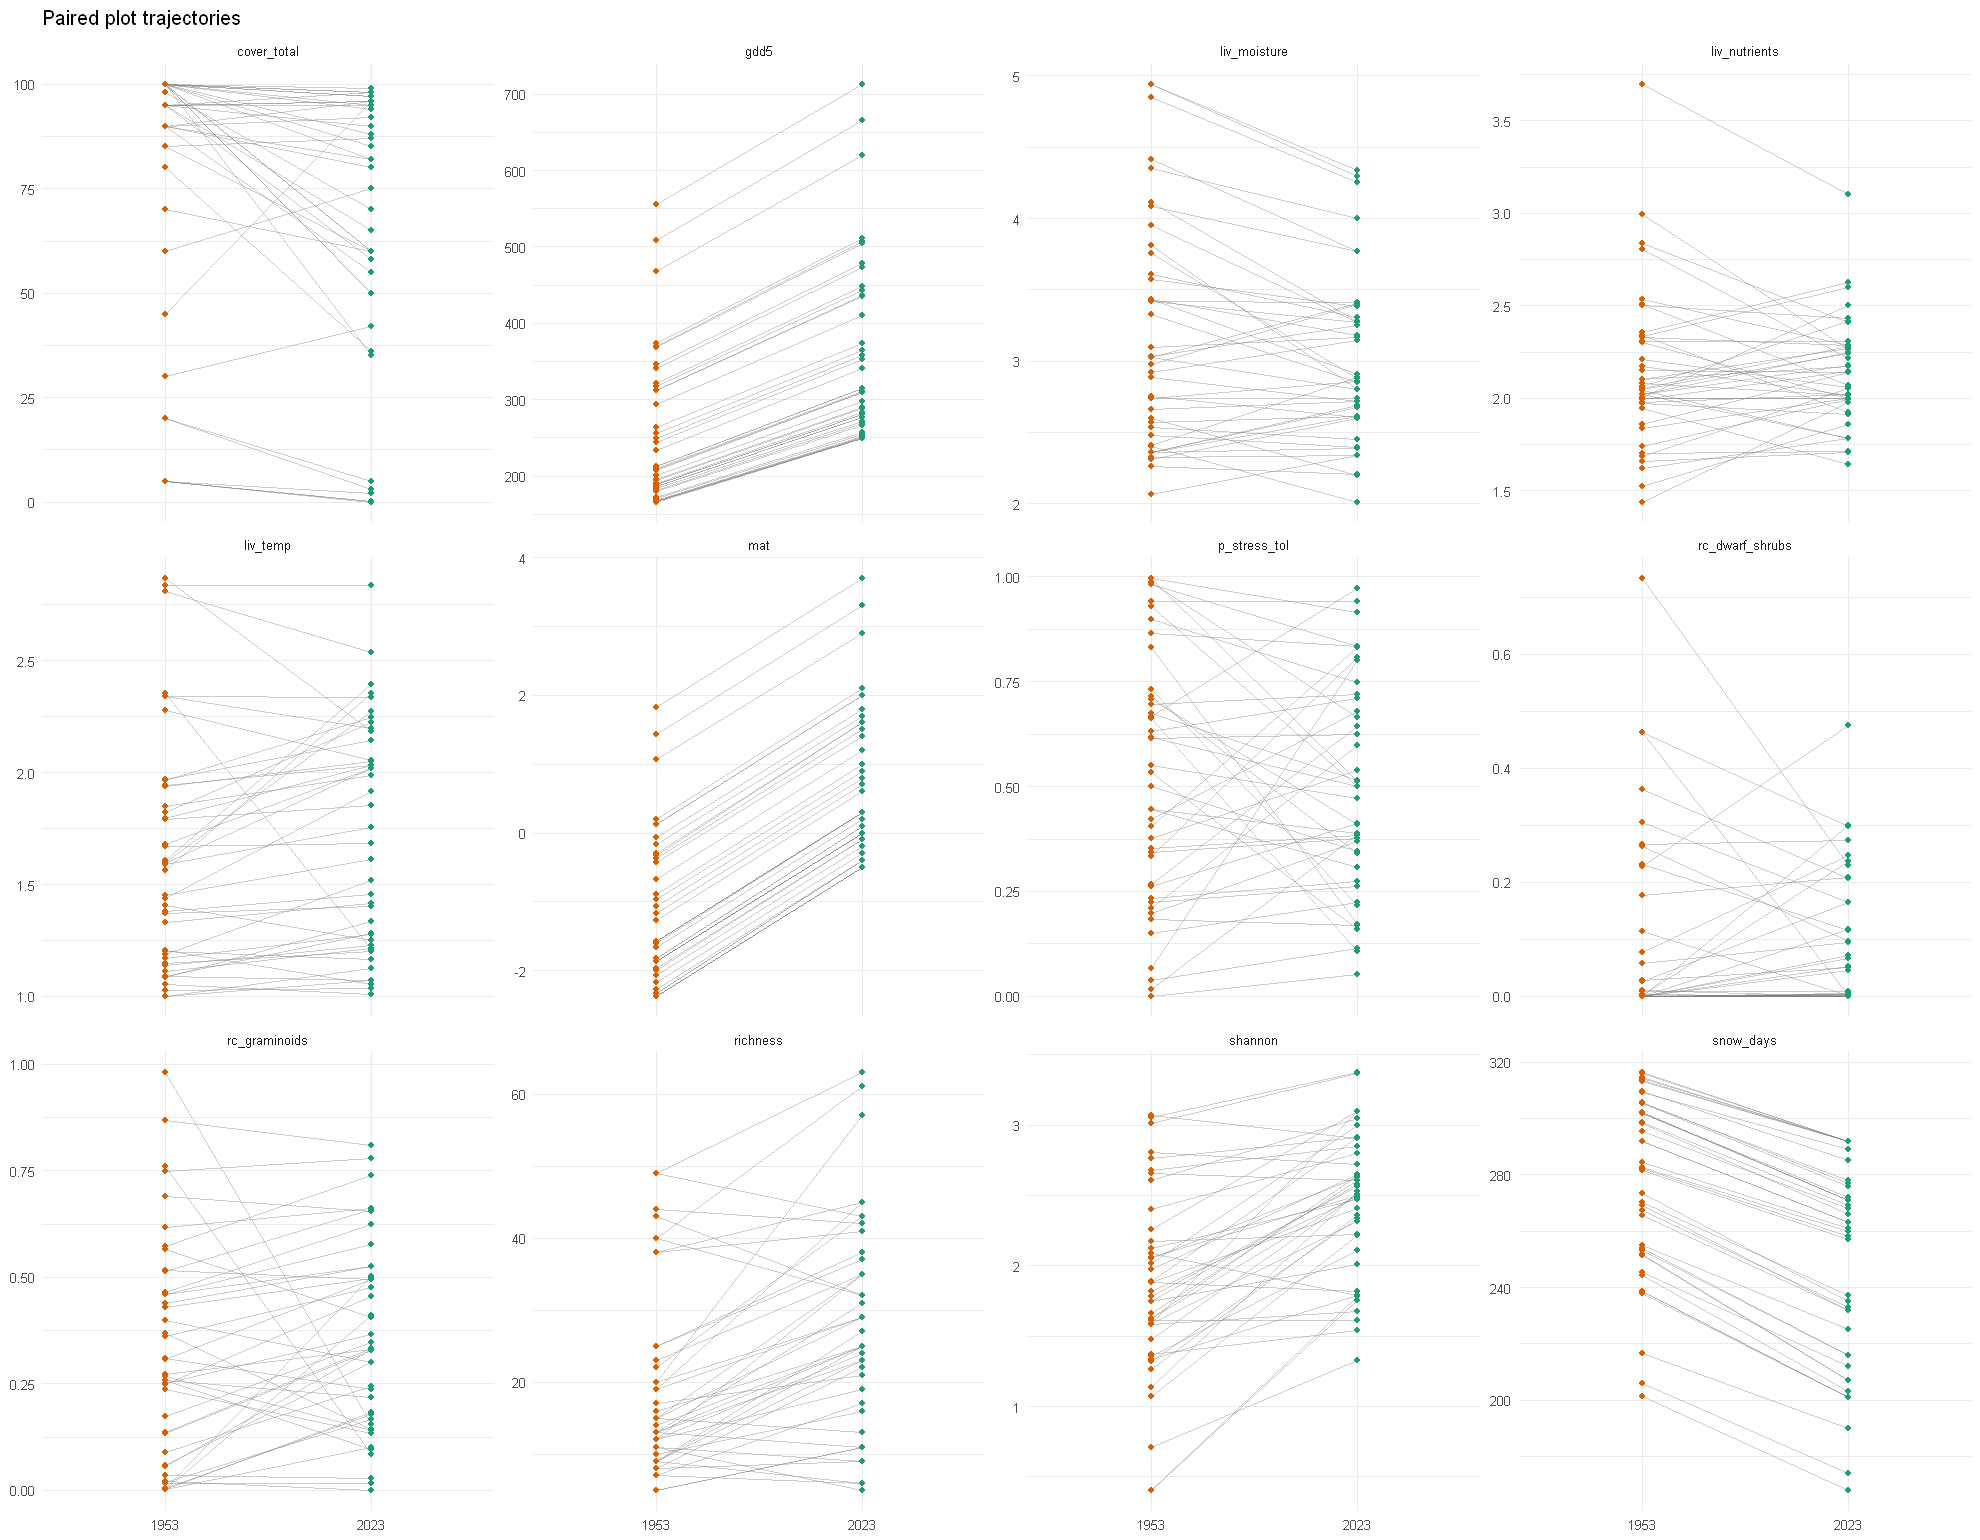

In [82]:
options(repr.plot.width = 18, repr.plot.height = 14)
key_vars <- c("richness", "cover_total", "shannon", "mat", "snow_days", "gdd5",
              "liv_temp", "liv_nutrients", "liv_moisture", "p_stress_tol", "rc_graminoids", "rc_dwarf_shrubs")
paired %>% filter(name %in% key_vars) %>%
  pivot_longer(c(y1953, y2023), names_to = "period", values_to = "value") %>%
  mutate(period = str_remove(period, "y")) %>%
  ggplot(aes(period, value, group = base_id)) +
  geom_line(alpha = .4, colour = "grey50", na.rm = TRUE) +
  geom_point(aes(colour = period), na.rm = TRUE) +
  facet_wrap(~ name, scales = "free_y", ncol = 4) +
  scale_colour_manual(values = period_cols) + guides(colour = "none") +
  labs(x = NULL, y = NULL, title = "Paired plot trajectories")

# 4. Species data

## 4.1 Cover values: what is actually in the table?

The README says cover classes were converted to mean values (r = 0.02, + = 0.1, 1 = 10, 2 = 30,
3 = 50, 4 = 70, 5 = 90). Anything outside that set deserves a look.

In [83]:
options(repr.plot.width = 9, repr.plot.height = 5)
sp_long_raw <- sp %>%
  pivot_longer(
    cols = -plot_id,
    names_to = "taxon",
    values_to = "cover"
  ) %>%
  filter(cover > 0)

sp_long_raw %>% count(cover) %>% mutate(standard = cover %in% c(0.02, 0.1, 10, 30, 50, 70, 90)) %>%
  kable(caption = "Frequency of each non-zero cover value")

sp_long_raw %>% filter(!cover %in% c(0.02, 0.1, 10, 30, 50, 70, 90)) %>%
  arrange(cover) %>% kable(caption = "Non-standard cover values (plot x taxon)")

cover,n,standard
0.02,149,TRUE
0.10,1221,TRUE
0.12,1,FALSE
0.20,116,FALSE
2.00,1,FALSE
10.00,489,TRUE
10.10,3,FALSE
30.00,147,TRUE
30.10,1,FALSE
40.00,1,FALSE


plot_id,taxon,cover
202,Phyteuma betonicifolium,0.12
12,Moehringia ciliata,0.20
17,Poa alpina,0.20
33,Sanionia uncinata,0.20
35,Euphrasia minima agg.,0.20
36,Homogyne alpina,0.20
36,Luzula alpinopilosa,0.20
43,Alchemilla pentaphyllea,0.20
43,Anthelia juratzkana,0.20
43,Sibbaldia procumbens,0.20


In [84]:
cat("Matrix:", nrow(comm), "plots x", ncol(comm), "taxa\n")
cat("Share of zeros:", round(100 * mean(comm == 0), 1), "%\n")
cat("Taxa present in exactly 1 plot:", sum(colSums(comm > 0) == 1), "\n")
cat("Taxa present in <= 3 plots:", sum(colSums(comm > 0) <= 3), "\n")
cat("Taxa never recorded (all zero):", sum(colSums(comm > 0) == 0), "\n")

Matrix: 83 plots x 373 taxa
Share of zeros: 92.9 %
Taxa present in exactly 1 plot: 108 
Taxa present in <= 3 plots: 196 
Taxa never recorded (all zero): 0 


## 4.2 Taxa list: resolution and vascular / non-vascular

There is no growth-group column in the species table, so I flag mosses and lichens by genus.
**Please review the genus list** (the richness check below will reveal mismatches).

In [85]:
nonvasc_genera <- c("Alectoria", "Anthelia", "Arctoa", "Barbilophozia", "Bartramia", "Brachythecium",
  "Bryoerythrophyllum", "Bryum", "Cetraria", "Cladonia", "Climacium", "Cynodontium", "Dicranum",
  "Drepanocladus", "Flavocetraria", "Hylocomium", "Hypnum", "Lescuraea", "Lobaria", "Nephromopsis",
  "Ochrolechia", "Oncophorus", "Paraleucobryum", "Peltigera", "Philonotis", "Plagiothecium",
  "Pleuroclada", "Polytrichastrum", "Polytrichum", "Ptychostomum", "Racomitrium", "Sanionia",
  "Sarmentypnum", "Scapania", "Solorina", "Stereocaulon", "Syntrichia", "Thamnolia", "Tortella",
  "Tortula", "Webera", "Weissia")
nonvasc_rx <- paste0("^(", paste(nonvasc_genera, collapse = "|"), ")\\b")

taxa_tbl <- tibble(taxon = colnames(comm)) %>%
  mutate(
    group = if_else(str_detect(taxon, nonvasc_rx), "non-vascular (moss/lichen)", "vascular"),
    resolution = case_when(
      !str_detect(taxon, " ")        ~ "family",
      str_detect(taxon, "\\bcf\\.")  ~ "cf.",
      str_detect(taxon, "\\bsp\\.")  ~ "genus only (sp.)",
      str_detect(taxon, "\\bagg\\.") ~ "aggregate",
      str_detect(taxon, "\\bssp\\.") ~ "subspecies",
      str_detect(taxon, "\\bsect\\.")~ "section",
      TRUE                           ~ "species"
    ),
    n_plots = colSums(comm > 0)[taxon]
  )

taxa_tbl %>% count(group, resolution) %>% kable(caption = "Taxa by group and taxonomic resolution")
vasc_taxa <- taxa_tbl$taxon[taxa_tbl$group == "vascular"]

group,resolution,n
non-vascular (moss/lichen),genus only (sp.),9
non-vascular (moss/lichen),species,51
vascular,aggregate,9
vascular,cf.,3
vascular,family,1
vascular,genus only (sp.),2
vascular,section,1
vascular,species,286
vascular,subspecies,11


In [86]:
rich <- tibble(plot_id = rownames(comm),
               rich_all  = rowSums(comm > 0),
               rich_vasc = rowSums(comm[, vasc_taxa] > 0),
               cover_sum = rowSums(comm)) %>%
  left_join(env %>% select(plot_id, base_id, period, richness, shannon, evenness, elevation), by = "plot_id") %>%
  mutate(diff_vs_env = rich_vasc - richness)

cat("Plots where my vascular richness equals the env-table richness:",
    sum(rich$diff_vs_env == 0, na.rm = TRUE), "of", nrow(rich), "\n")
rich %>% filter(diff_vs_env != 0) %>% select(plot_id, rich_all, rich_vasc, richness, diff_vs_env) %>%
  kable(caption = "Mismatches between species table and 'vascular species richness [n]'")

Plots where my vascular richness equals the env-table richness: 82 of 83 


plot_id,rich_all,rich_vasc,richness,diff_vs_env
99,19,15,14,1


## 4.3 Plot-level summaries

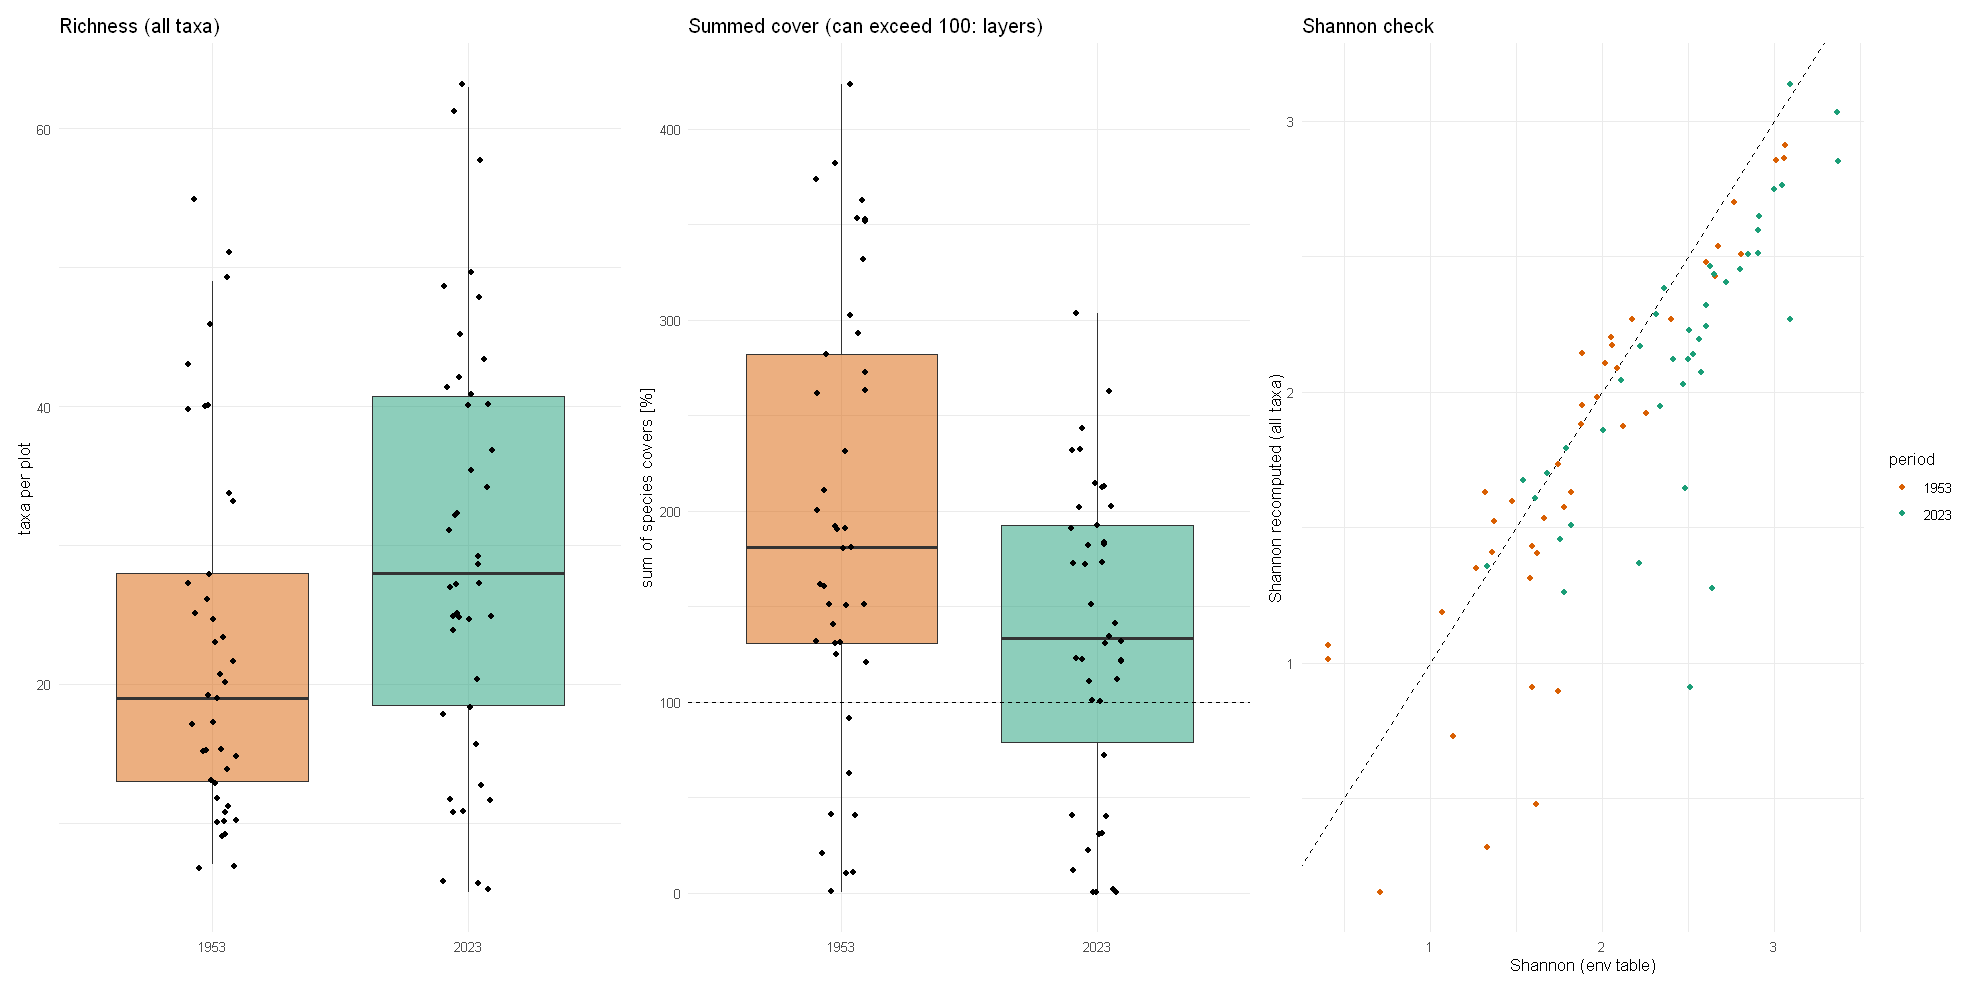

In [87]:
options(repr.plot.width = 18, repr.plot.height = 9)
rich <- rich %>%
  mutate(shannon_calc = diversity(comm[plot_id, ], "shannon"),
         shannon_vasc = diversity(comm[plot_id, vasc_taxa], "shannon"))

p1 <- ggplot(rich, aes(period, rich_all, fill = period)) + geom_boxplot(alpha = .5, outlier.shape = NA) +
  geom_jitter(width = .1) + scale_fill_manual(values = period_cols) + guides(fill = "none") +
  labs(y = "taxa per plot", x = NULL, title = "Richness (all taxa)")
p2 <- ggplot(rich, aes(period, cover_sum, fill = period)) + geom_boxplot(alpha = .5, outlier.shape = NA) +
  geom_jitter(width = .1) + scale_fill_manual(values = period_cols) + guides(fill = "none") +
  geom_hline(yintercept = 100, linetype = 2) +
  labs(y = "sum of species covers [%]", x = NULL, title = "Summed cover (can exceed 100: layers)")
p3 <- ggplot(rich, aes(shannon, shannon_calc, colour = period)) + geom_abline(linetype = 2) +
  geom_point(na.rm = TRUE) + scale_colour_manual(values = period_cols) +
  labs(x = "Shannon (env table)", y = "Shannon recomputed (all taxa)", title = "Shannon check")
p1 + p2 + p3

`geom_smooth()` using formula = 'y ~ x'


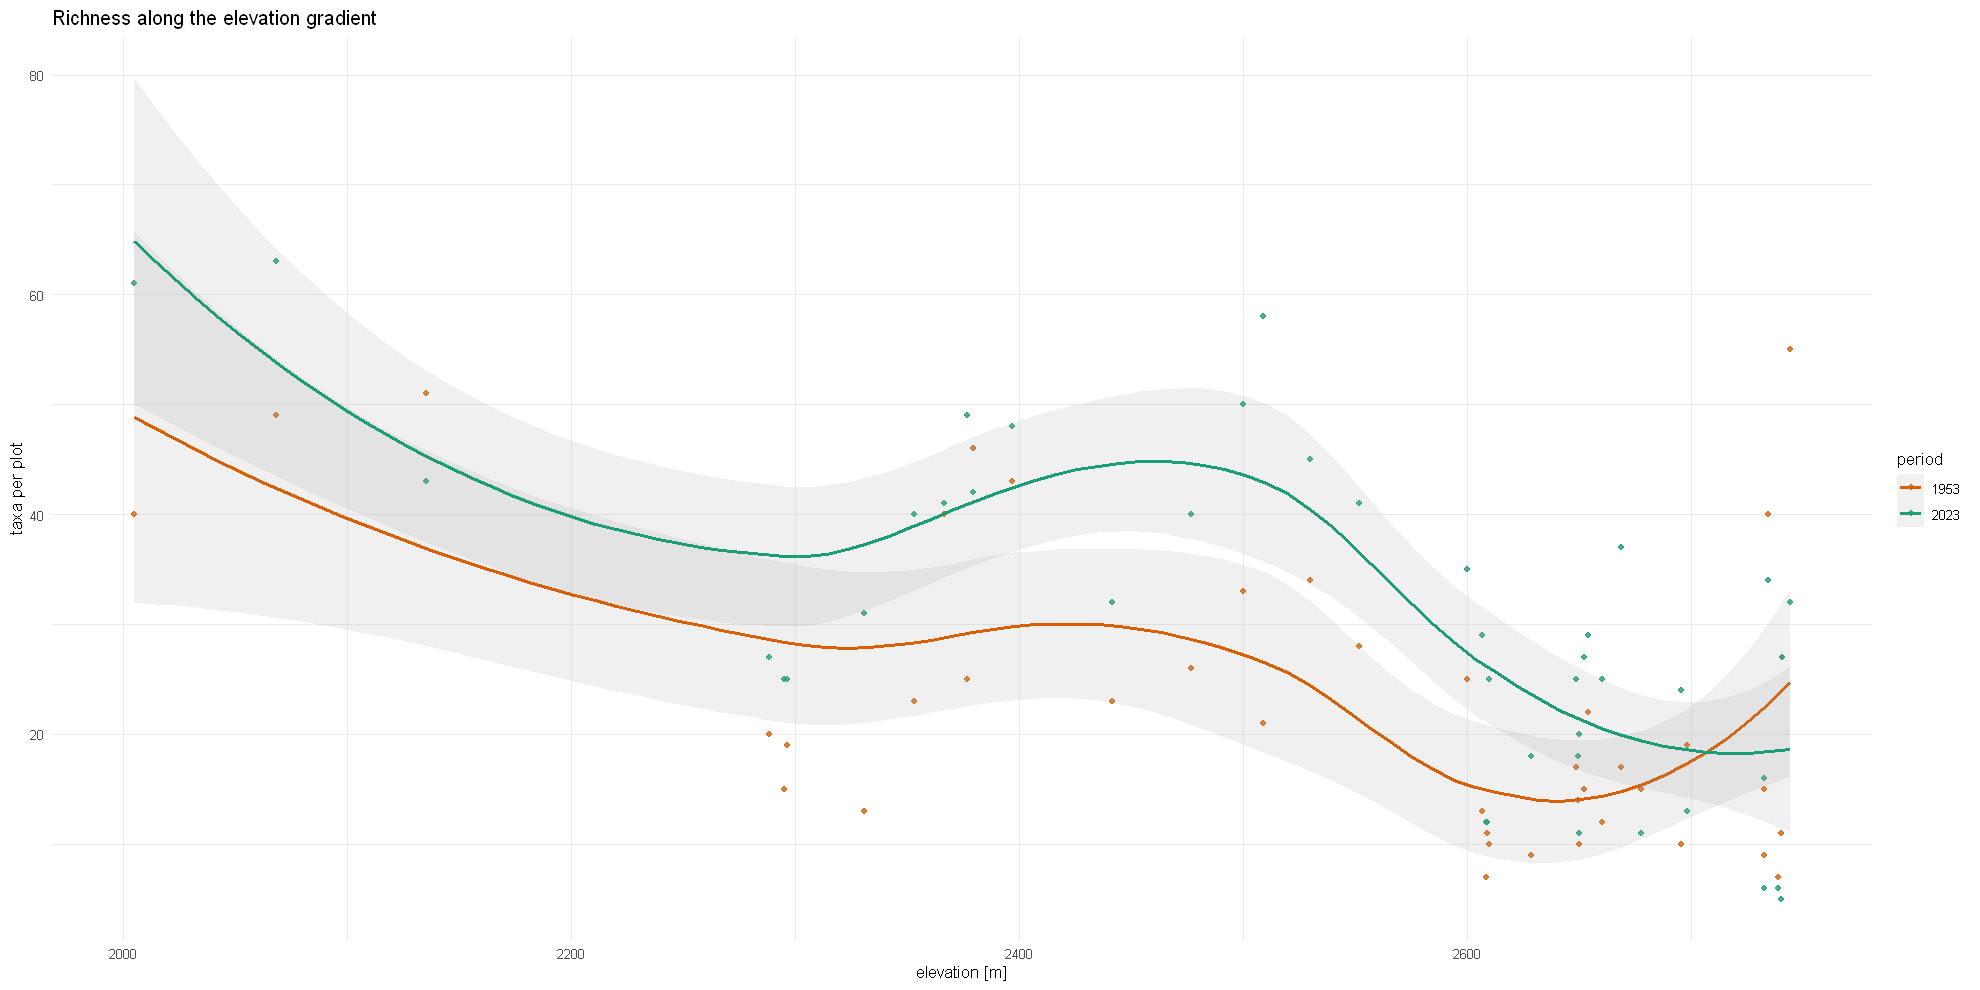

In [88]:
ggplot(rich, aes(elevation, rich_all, colour = period)) +
  geom_point(alpha = .8) + geom_smooth(method = "loess", se = TRUE, alpha = .15) +
  scale_colour_manual(values = period_cols) +
  labs(x = "elevation [m]", y = "taxa per plot", title = "Richness along the elevation gradient")

## 4.4 Species frequency, abundance and turnover

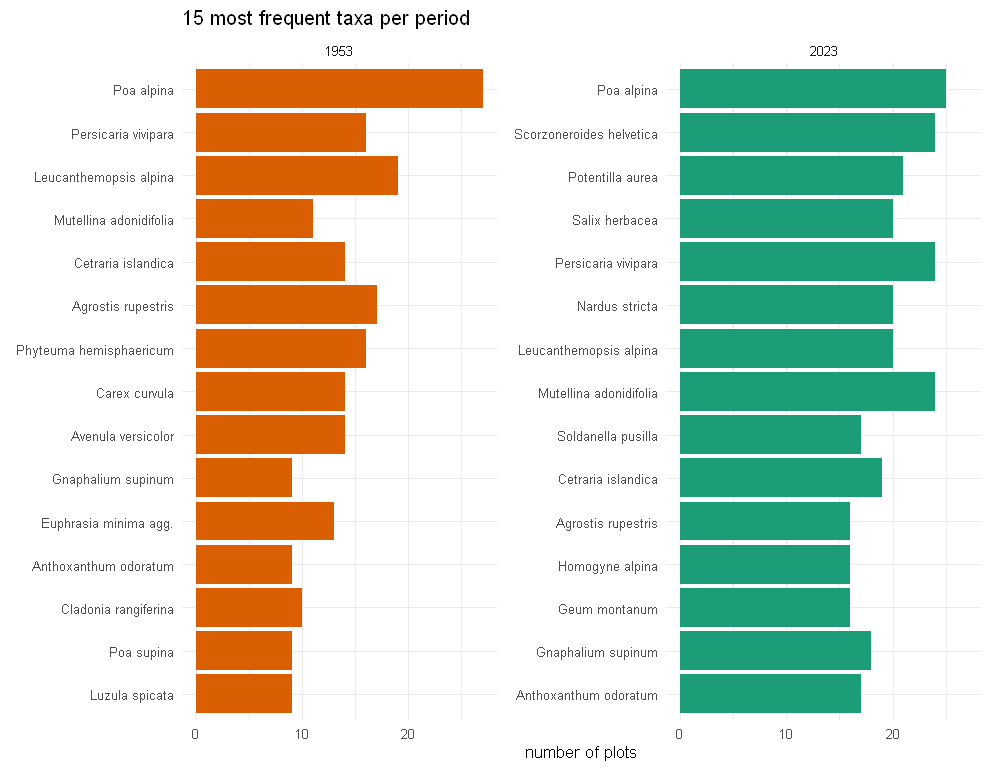

In [89]:
options(repr.plot.width = 9, repr.plot.height = 7)
long <- sp %>%
  pivot_longer(-plot_id, names_to = "taxon", values_to = "cover") %>%
  left_join(env %>% select(plot_id, base_id, period, elevation, assoc_abbr), by = "plot_id")

freq <- long %>% group_by(taxon, period) %>%
  summarise(n_occ = sum(cover > 0), mean_cover = mean(cover), .groups = "drop")

top_freq <- freq %>% group_by(period) %>% slice_max(n_occ, n = 15, with_ties = FALSE) %>% ungroup()
ggplot(top_freq, aes(n_occ, reorder(taxon, n_occ), fill = period)) +
  geom_col() + facet_wrap(~ period, scales = "free_y") +
  scale_fill_manual(values = period_cols) + guides(fill = "none") +
  labs(x = "number of plots", y = NULL, title = "15 most frequent taxa per period")

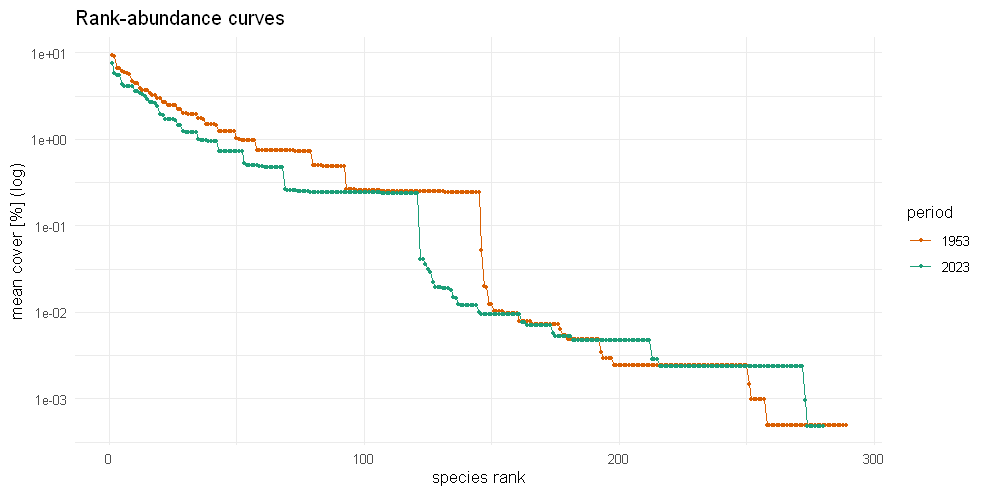

In [90]:
options(repr.plot.width = 9, repr.plot.height = 4.5)
freq %>% filter(mean_cover > 0) %>% group_by(period) %>%
  arrange(desc(mean_cover), .by_group = TRUE) %>% mutate(rank = row_number()) %>%
  ggplot(aes(rank, mean_cover, colour = period)) + geom_line() + geom_point(size = 1) +
  scale_y_log10() + scale_colour_manual(values = period_cols) +
  labs(x = "species rank", y = "mean cover [%] (log)", title = "Rank-abundance curves")

In [91]:
options(repr.plot.width = 9, repr.plot.height = 5)
tax_status <- long %>% filter(cover > 0) %>% distinct(taxon, period) %>%
  mutate(v = 1) %>% pivot_wider(names_from = period, values_from = v, values_fill = 0) %>%
  rename(y1953 = `1953`, y2023 = `2023`) %>%
  mutate(status = case_when(y1953 == 1 & y2023 == 1 ~ "both",
                            y1953 == 1 ~ "only 1953", TRUE ~ "only 2023"))
tax_status %>% count(status) %>% kable(caption = "Taxa pool by period")

status,n
both,196
only 1953,93
only 2023,84


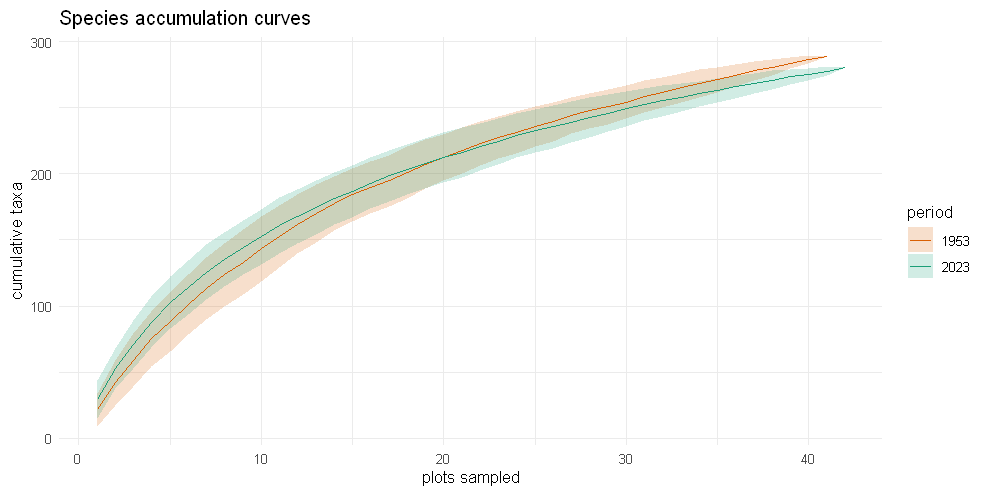

In [92]:
options(repr.plot.width = 9, repr.plot.height = 4.5)
acc <- map_dfr(c("1953", "2023"), function(p) {
  ids <- env_sp$plot_id[env_sp$period == p]
  a <- specaccum(comm[ids, ], method = "random", permutations = 200)
  tibble(period = p, sites = a$sites, richness = a$richness, sd = a$sd)
})
ggplot(acc, aes(sites, richness, colour = period, fill = period)) +
  geom_ribbon(aes(ymin = richness - sd, ymax = richness + sd), alpha = .2, colour = NA) +
  geom_line() + scale_colour_manual(values = period_cols) + scale_fill_manual(values = period_cols) +
  labs(x = "plots sampled", y = "cumulative taxa", title = "Species accumulation curves")

# 5. Community change within plots (paired)

## 5.1 Gains, losses and turnover per plot

name,value
lost_mean,10.59
lost_median,9.00
gained_mean,17.88
gained_median,17.00
retained_mean,12.32
retained_median,10.00
bray_mean,0.73
bray_median,0.75
sorensen_mean,0.55
sorensen_median,0.54


`geom_smooth()` using formula = 'y ~ x'


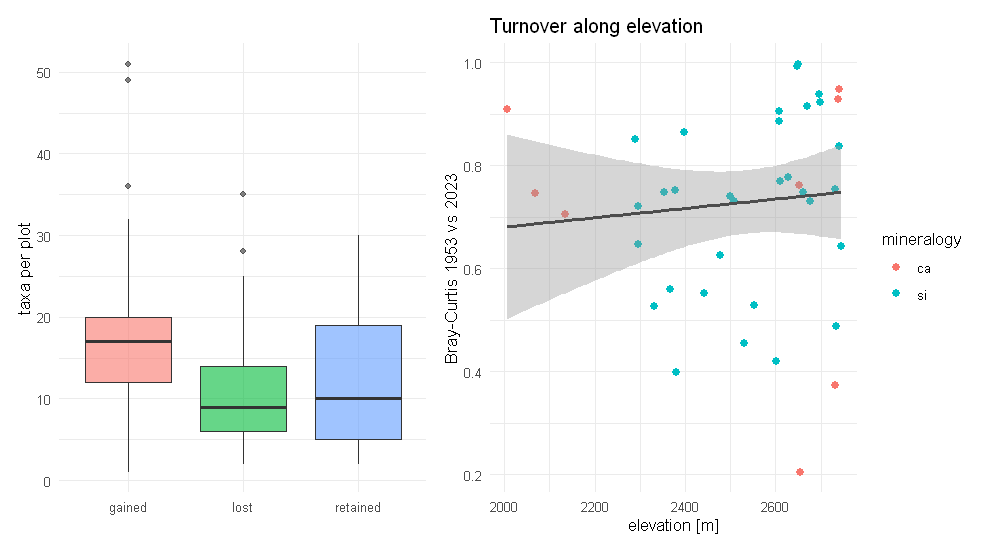

In [93]:
options(repr.plot.width = 9, repr.plot.height = 5)
A <- comm[pair_ids_sp, , drop = FALSE]                  # 1953
B <- comm[paste0(pair_ids_sp, "_23"), , drop = FALSE]   # 2023

bc  <- as.matrix(vegdist(comm, "bray"))
sor <- as.matrix(vegdist(comm, "bray", binary = TRUE))  # Sorensen

pair_turn <- tibble(
  base_id = pair_ids_sp,
  lost     = rowSums(A > 0 & !(B > 0)),
  gained   = rowSums(!(A > 0) & B > 0),
  retained = rowSums(A > 0 & B > 0),
  bray     = bc[cbind(pair_ids_sp, paste0(pair_ids_sp, "_23"))],
  sorensen = sor[cbind(pair_ids_sp, paste0(pair_ids_sp, "_23"))]
) %>%
  left_join(env %>% filter(period == "1953") %>% select(base_id, elevation, assoc_abbr, mineralogy), by = "base_id")

pair_turn %>% summarise(across(c(lost, gained, retained, bray, sorensen), list(mean = mean, median = median))) %>%
  pivot_longer(everything()) %>% kable(digits = 2)

p1 <- pair_turn %>% pivot_longer(c(lost, gained, retained)) %>%
  ggplot(aes(name, value, fill = name)) + geom_boxplot(alpha = .6) + guides(fill = "none") +
  labs(x = NULL, y = "taxa per plot")
p2 <- ggplot(pair_turn, aes(elevation, bray, colour = mineralogy)) + geom_point(size = 2) +
  geom_smooth(aes(group = 1), method = "lm", se = TRUE, colour = "grey30") +
  labs(x = "elevation [m]", y = "Bray-Curtis 1953 vs 2023", title = "Turnover along elevation")
p1 + p2

rho_bray_dMAT,rho_bray_dSnow,rho_bray_dLIVT
-0.13,0.23,-0.06


`geom_smooth()` using formula = 'y ~ x'


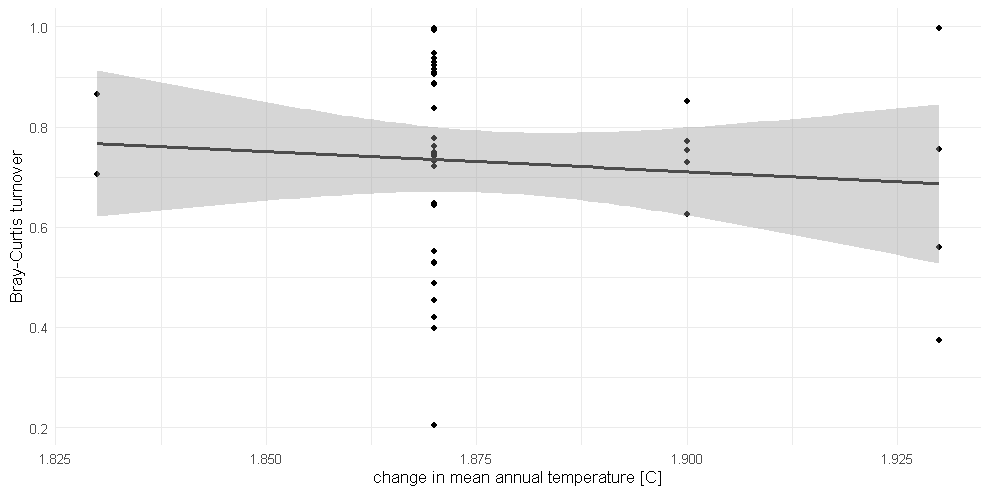

In [94]:
options(repr.plot.width = 9, repr.plot.height = 4.5)
delta <- paired %>% mutate(delta = y2023 - y1953) %>%
  select(base_id, name, delta) %>% pivot_wider(names_from = name, values_from = delta, names_prefix = "d_")

pt <- pair_turn %>% left_join(delta, by = "base_id")

pt %>% summarise(
  rho_bray_dMAT  = cor(bray, d_mat, method = "spearman", use = "complete.obs"),
  rho_bray_dSnow = cor(bray, d_snow_days, method = "spearman", use = "complete.obs"),
  rho_bray_dLIVT = cor(bray, d_liv_temp, method = "spearman", use = "complete.obs")) %>% kable(digits = 2)

ggplot(pt, aes(d_mat, bray)) + geom_point() + geom_smooth(method = "lm", colour = "grey30") +
  labs(x = "change in mean annual temperature [C]", y = "Bray-Curtis turnover")

## 5.2 Ordination (NMDS) and PERMANOVA

NMDS stress: 0.145 


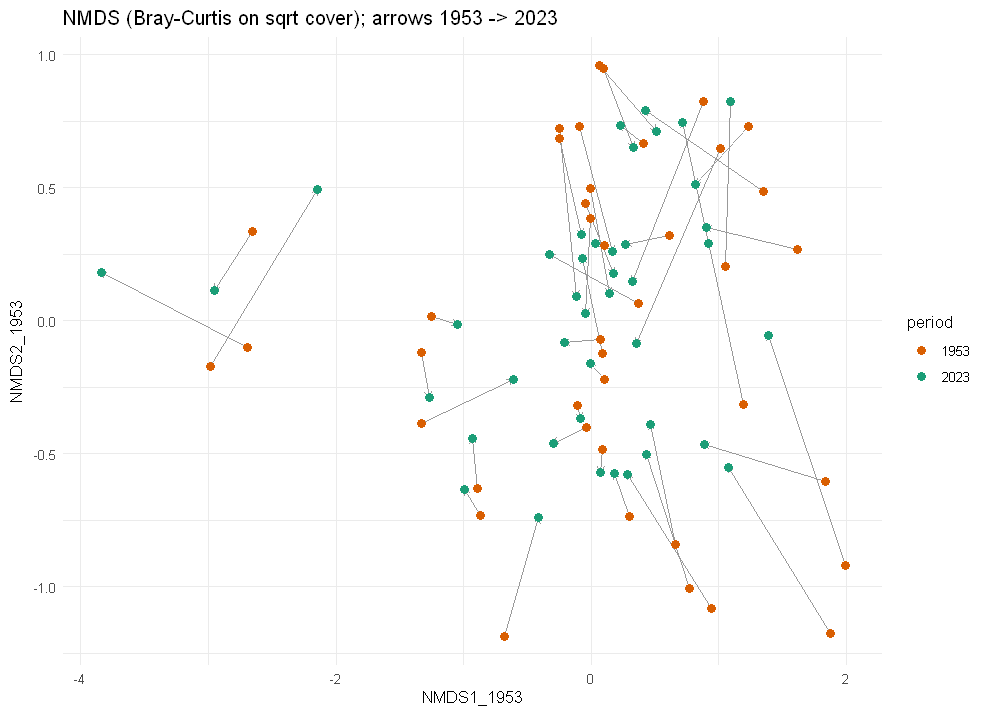

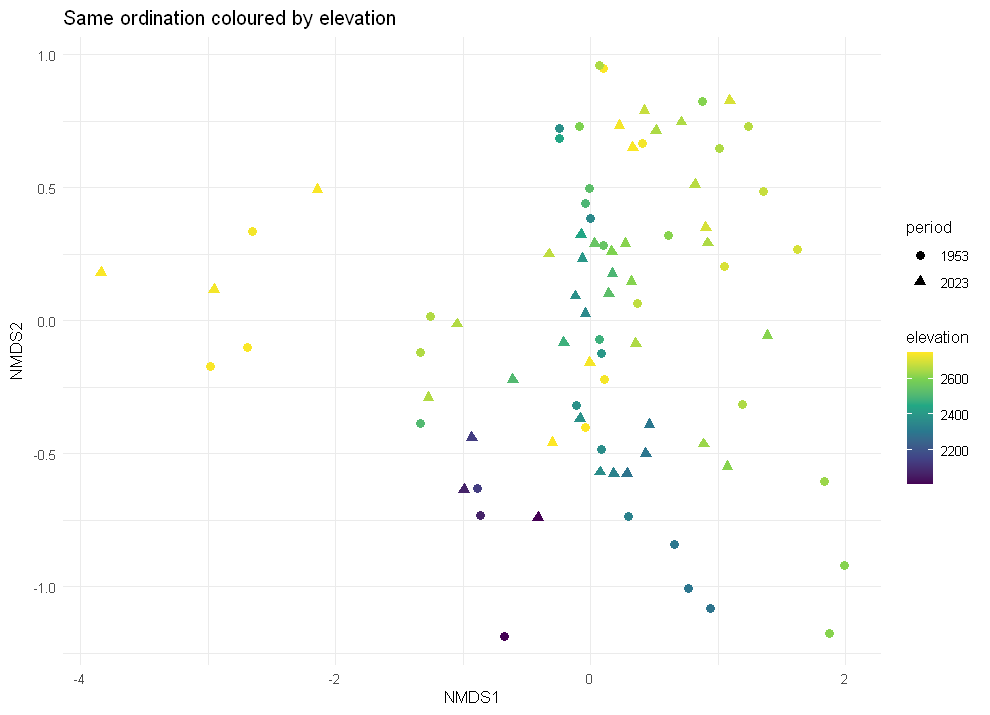

In [95]:
options(repr.plot.width = 9, repr.plot.height = 6.5)
nmds <- metaMDS(sqrt(comm), distance = "bray", autotransform = FALSE, k = 2, trymax = 50, trace = FALSE)
cat("NMDS stress:", round(nmds$stress, 3), "\n")

nm <- as.data.frame(scores(nmds, display = "sites")) %>%
  rownames_to_column("plot_id") %>%
  left_join(env %>% select(plot_id, base_id, period, assoc_abbr, elevation), by = "plot_id")

nm_w <- nm %>% filter(base_id %in% pair_ids_sp) %>%
  select(base_id, period, NMDS1, NMDS2) %>%
  pivot_wider(names_from = period, values_from = c(NMDS1, NMDS2))

print(ggplot() +
  geom_segment(data = nm_w, aes(x = NMDS1_1953, y = NMDS2_1953, xend = NMDS1_2023, yend = NMDS2_2023),
               colour = "grey60", arrow = arrow(length = unit(1.5, "mm"))) +
  geom_point(data = nm, aes(NMDS1, NMDS2, colour = period), size = 2.5) +
  scale_colour_manual(values = period_cols) +
  labs(title = "NMDS (Bray-Curtis on sqrt cover); arrows 1953 -> 2023"))

ggplot(nm, aes(NMDS1, NMDS2, colour = elevation, shape = period)) + geom_point(size = 2.5) +
  scale_colour_viridis_c() + labs(title = "Same ordination coloured by elevation")

In [96]:
options(repr.plot.width = 9, repr.plot.height = 5)
fit_vars <- c("elevation", "slope", "mat", "snow_days", "gdd5", "liv_temp", "liv_nutrients",
              "liv_moisture", "liv_ph", "liv_humus", "pc1_thermal", "pc2_soil", "cover_total")
ef <- envfit(nmds, as.data.frame(env_sp %>% select(all_of(fit_vars))), permutations = 999, na.rm = TRUE)
tibble(variable = names(ef$vectors$r), r2 = ef$vectors$r, p = ef$vectors$pvals) %>%
  arrange(desc(r2)) %>% mutate(across(where(is.numeric), ~ round(.x, 3))) %>%
  kable(caption = "Environmental vectors fitted to the NMDS")

variable,r2,p
liv_temp,0.646,0.001
liv_ph,0.639,0.001
liv_humus,0.506,0.001
pc2_soil,0.416,0.001
liv_moisture,0.343,0.001
liv_nutrients,0.283,0.001
elevation,0.270,0.001
pc1_thermal,0.264,0.001
cover_total,0.228,0.001
gdd5,0.200,0.001


In [97]:
d <- vegdist(sqrt(comm), "bray")
perm_paired <- how(nperm = 999, blocks = factor(env_sp$base_id))   # permute years within each plot
adonis2(d ~ period, data = env_sp, permutations = perm_paired)

bd <- betadisper(d, env_sp$period)
permutest(bd, permutations = 999)

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Model,1,0.7442088,0.02137303,1.769025,0.001
Residual,81,34.0757889,0.97862697,NA,NA
Total,82,34.8199977,1.00000000,NA,NA



Permutation test for homogeneity of multivariate dispersions
Permutation: free
Number of permutations: 999

Response: Distances
          Df  Sum Sq   Mean Sq      F N.Perm Pr(>F)   
Groups     1 0.03076 0.0307558 7.1506    999  0.007 **
Residuals 81 0.34840 0.0043012                        
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

# 6. Species-level change (paired plots)

## 6.1 Gains and losses per taxon

Exact McNemar test (binomial on discordant pairs) on presence/absence in the same plots.

In [98]:
sp_change <- tibble(
  taxon      = colnames(comm),
  occ_1953   = colSums(A > 0),
  occ_2023   = colSums(B > 0),
  lost       = colSums(A > 0 & !(B > 0)),
  gained     = colSums(!(A > 0) & B > 0),
  mean_cover_1953 = colMeans(A),
  mean_cover_2023 = colMeans(B)
) %>%
  mutate(d_occ = occ_2023 - occ_1953,
         d_cover = mean_cover_2023 - mean_cover_1953,
         p = map2_dbl(lost, gained, ~ if ((.x + .y) == 0) NA_real_ else binom.test(.x, .x + .y, 0.5)$p.value),
         p_adj = p.adjust(p, "BH")) %>%
  left_join(taxa_tbl %>% select(taxon, group, resolution), by = "taxon")

write_csv(sp_change, "outputs/species_change_paired.csv")

sp_change %>% filter(occ_1953 + occ_2023 >= 5) %>% arrange(p) %>% head(20) %>%
  mutate(across(where(is.numeric), ~ round(.x, 3)))

taxon,occ_1953,occ_2023,lost,gained,mean_cover_1953,mean_cover_2023,d_occ,d_cover,p,p_adj,group,resolution
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
Scorzoneroides helvetica,9,23,0,14,2.934,1.749,14,-1.185,0.000,0.044,vascular,species
Potentilla aurea,8,21,0,13,3.663,3.198,13,-0.465,0.000,0.044,vascular,species
Coeloglossum viride,0,11,0,11,0.000,0.262,11,0.262,0.001,0.093,vascular,species
Nardus stricta,8,20,1,13,6.108,5.627,12,-0.481,0.002,0.093,vascular,species
Polytrichum sp.,1,13,1,13,0.000,1.966,12,1.966,0.002,0.093,non-vascular (moss/lichen),genus only (sp.)
Homogyne alpina,6,16,0,10,0.744,1.246,10,0.502,0.002,0.093,vascular,species
Sempervivum montanum,3,13,0,10,0.010,0.030,10,0.020,0.002,0.093,vascular,species
Mutellina adonidifolia,11,24,2,15,3.913,3.447,13,-0.466,0.002,0.093,vascular,species
Salix herbacea,6,19,2,15,3.664,4.171,13,0.507,0.002,0.093,vascular,species


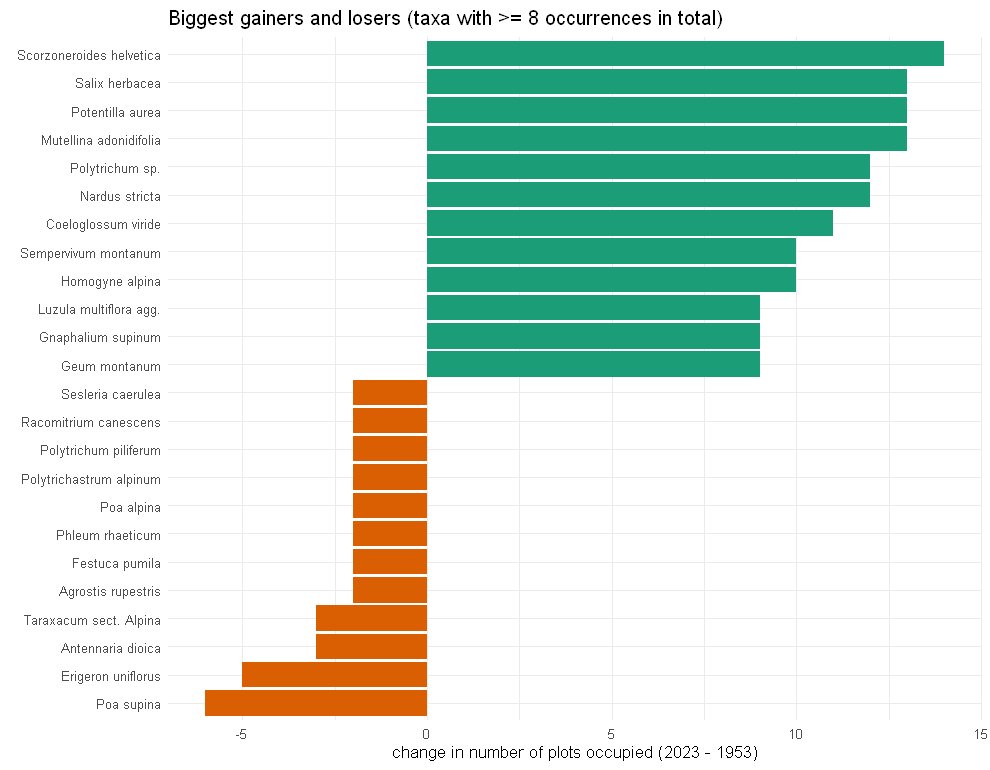

In [99]:
options(repr.plot.width = 9, repr.plot.height = 7)
wl <- sp_change %>% filter(occ_1953 + occ_2023 >= 8) %>%
  arrange(d_occ) %>% { bind_rows(head(., 12), tail(., 12)) }

ggplot(wl, aes(d_occ, reorder(taxon, d_occ), fill = d_occ > 0)) + geom_col() +
  scale_fill_manual(values = c("TRUE" = "#1B9E77", "FALSE" = "#D95F02"), guide = "none") +
  labs(x = "change in number of plots occupied (2023 - 1953)", y = NULL,
       title = "Biggest gainers and losers (taxa with >= 8 occurrences in total)")

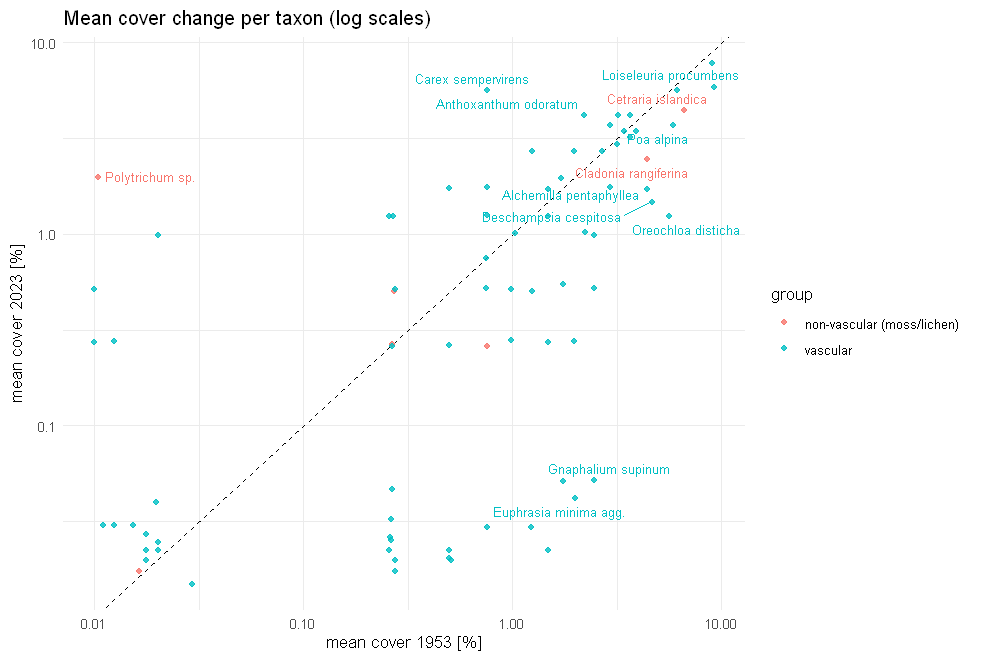

In [100]:
options(repr.plot.width = 9, repr.plot.height = 6)
sp_change %>% filter(occ_1953 + occ_2023 >= 8) %>%
  ggplot(aes(mean_cover_1953 + .01, mean_cover_2023 + .01, colour = group)) +
  geom_abline(linetype = 2) + geom_point(alpha = .8) +
  geom_text_repel(data = ~ slice_max(.x, abs(d_cover), n = 12, with_ties = FALSE),
                  aes(label = taxon), size = 3, show.legend = FALSE) +
  scale_x_log10() + scale_y_log10() +
  labs(x = "mean cover 1953 [%]", y = "mean cover 2023 [%]", title = "Mean cover change per taxon (log scales)")

## 6.2 Shift in elevational optimum

Cover-weighted mean elevation of the plots where each taxon occurs, per period
(an upward shift is the classic signature of warming).

Taxa with >= 5 plots in both periods: 48 
Median shift [m]: 28.3 

	Wilcoxon signed rank exact test

data:  optima$shift
V = 680, p-value = 0.3512
alternative hypothesis: true location is not equal to 0



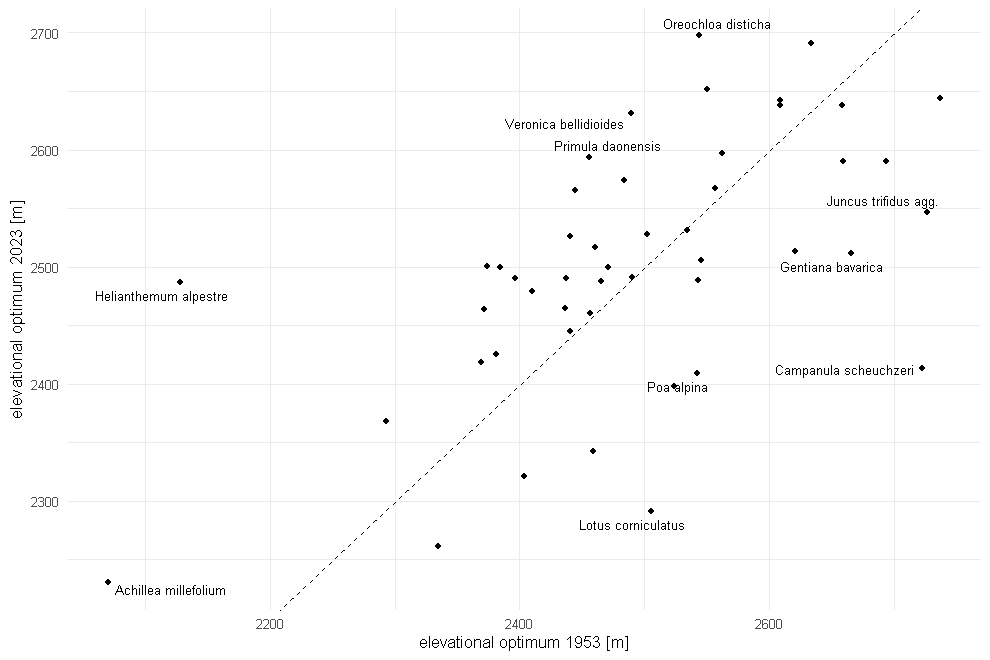

In [101]:
optima <- long %>% filter(cover > 0) %>%
  group_by(taxon, period) %>%
  summarise(n = n(), opt = weighted.mean(elevation, cover), .groups = "drop") %>%
  filter(n >= 5) %>%
  pivot_wider(names_from = period, values_from = c(n, opt)) %>%
  drop_na() %>% mutate(shift = opt_2023 - opt_1953)

cat("Taxa with >= 5 plots in both periods:", nrow(optima), "\n")
cat("Median shift [m]:", round(median(optima$shift), 1), "\n")
if (nrow(optima) > 5) print(wilcox.test(optima$shift, mu = 0))

ggplot(optima, aes(opt_1953, opt_2023)) + geom_abline(linetype = 2) + geom_point() +
  geom_text_repel(data = ~ slice_max(.x, abs(shift), n = 10, with_ties = FALSE), aes(label = taxon), size = 3) +
  labs(x = "elevational optimum 1953 [m]", y = "elevational optimum 2023 [m]")

# 7. First look at species-species associations

Spearman correlation of cover among the most frequent vascular taxa, within each period.
This is only descriptive: correlation of cover does not demonstrate interaction, and with
~41 plots per period it is noisy. It is meant to show where to dig deeper.

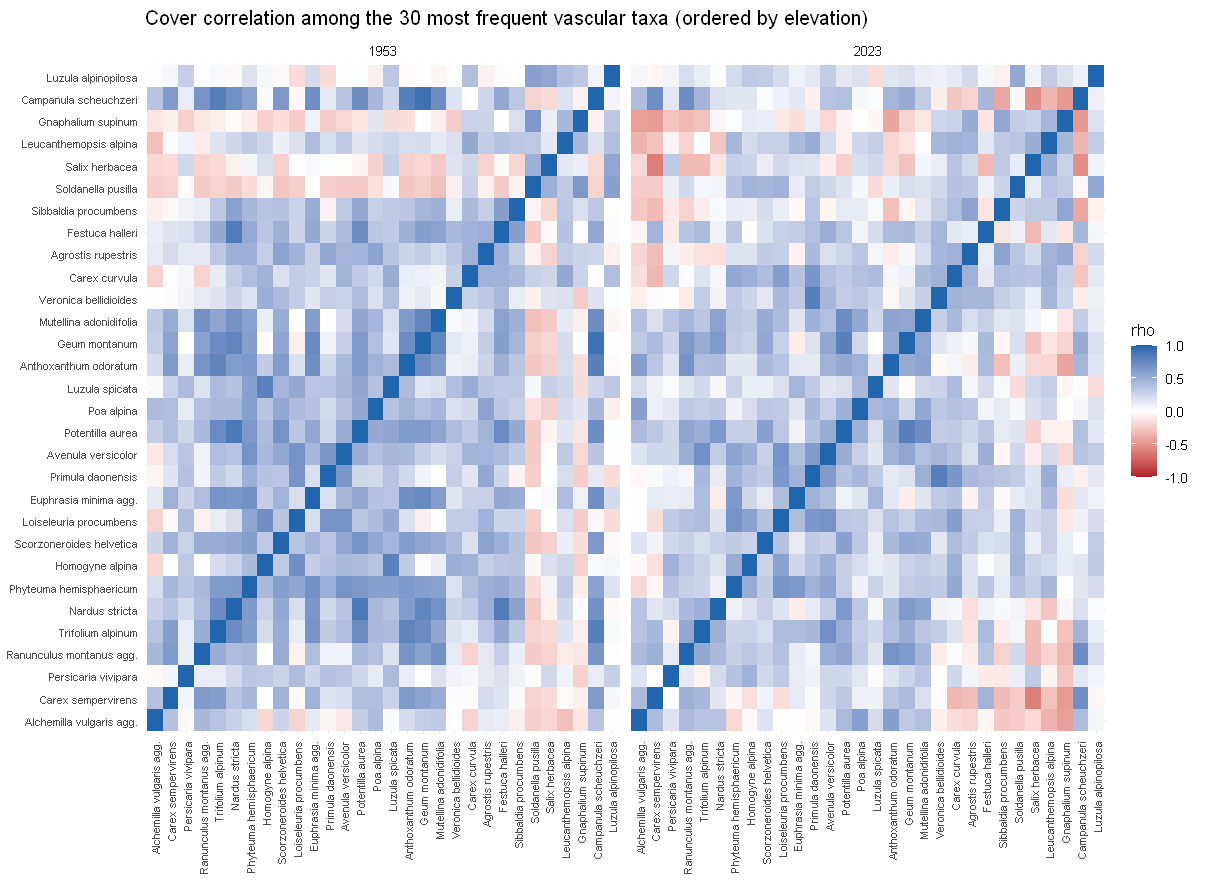

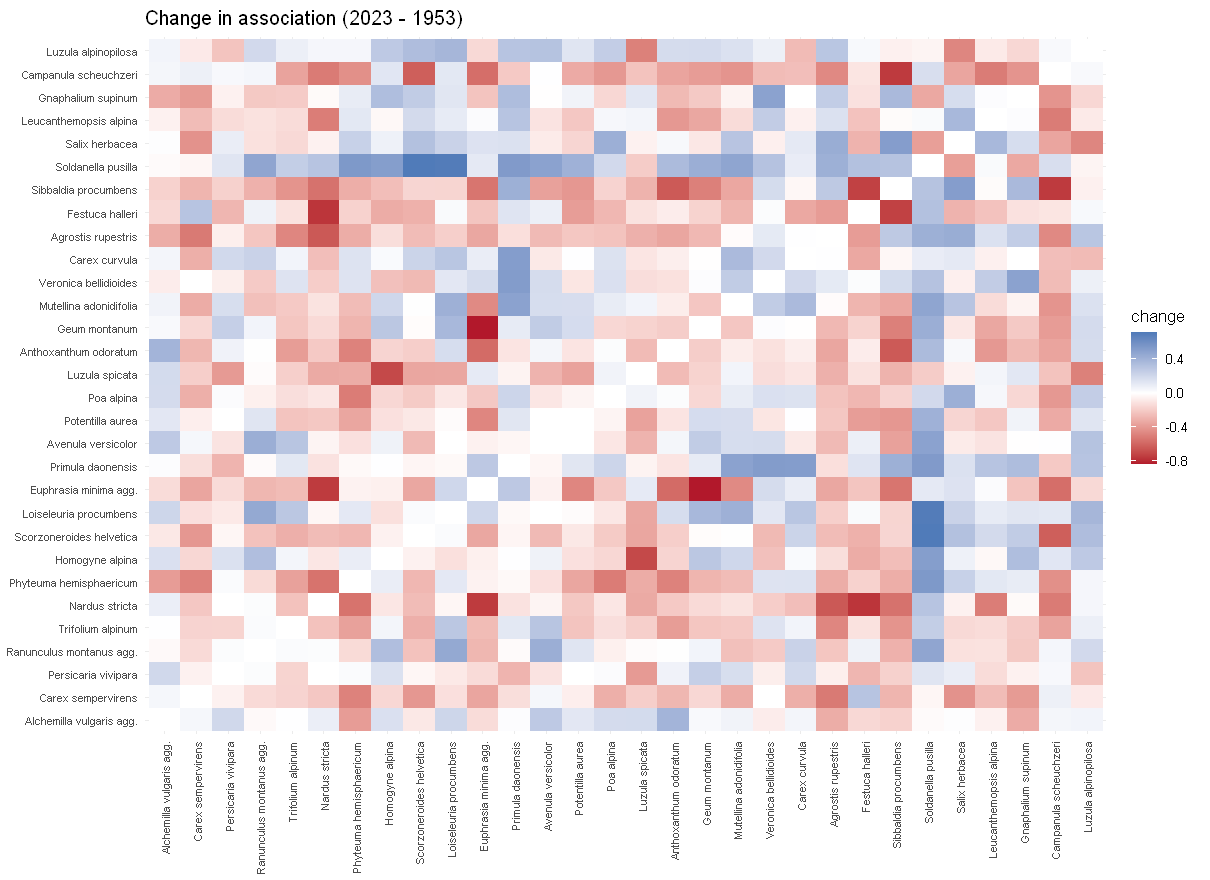

In [102]:
options(repr.plot.width = 11, repr.plot.height = 8)
top_taxa <- taxa_tbl %>% filter(group == "vascular") %>% slice_max(n_plots, n = 30, with_ties = FALSE) %>% pull(taxon)

# order taxa along the elevation gradient
elev_order <- long %>% filter(taxon %in% top_taxa, cover > 0) %>%
  group_by(taxon) %>% summarise(opt = weighted.mean(elevation, cover)) %>% arrange(opt) %>% pull(taxon)

cor_period <- function(p) {
  ids <- env_sp$plot_id[env_sp$period == p]
  m <- suppressWarnings(cor(comm[ids, top_taxa], method = "spearman"))
  as.data.frame(as.table(m)) %>% mutate(period = p)
}
cor_all <- map_dfr(c("1953", "2023"), cor_period) %>%
  mutate(Var1 = factor(Var1, levels = elev_order), Var2 = factor(Var2, levels = elev_order))

p1 <- ggplot(cor_all, aes(Var1, Var2, fill = Freq)) + geom_tile() + facet_wrap(~ period) +
  scale_fill_gradient2(low = "#B2182B", mid = "white", high = "#2166AC", limits = c(-1, 1), na.value = "grey90") +
  labs(x = NULL, y = NULL, fill = "rho", title = "Cover correlation among the 30 most frequent vascular taxa (ordered by elevation)") +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = .5, size = 7), axis.text.y = element_text(size = 7))

cor_diff <- cor_all %>% pivot_wider(names_from = period, values_from = Freq) %>%
  mutate(diff = `2023` - `1953`)
p2 <- ggplot(cor_diff, aes(Var1, Var2, fill = diff)) + geom_tile() +
  scale_fill_gradient2(low = "#B2182B", mid = "white", high = "#2166AC", na.value = "grey90") +
  labs(x = NULL, y = NULL, fill = "change", title = "Change in association (2023 - 1953)") +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = .5, size = 7), axis.text.y = element_text(size = 7))
print(p1)
print(p2)

# 8. Points to resolve before the main analysis

Fill this in as you read the outputs above. Things the data already suggest:

1. **Plot `17bis` (1953)** exists in the environmental table but not in the species table, so only 41 plots are paired for species analyses (42 for environmental ones).
2. **Non-standard cover values** (e.g. 0.12, 0.2, 2, 10.1, 30.1, 40, 44, 50.02): not part of the conversion scale in the README. Probably summed or merged taxa; decide how to treat them.
3. **Summed cover per plot can exceed 100 %** (layers), so relative abundance should be computed explicitly if needed.
4. **`total vegetation cover`** has a missing value; some plots show 5 % total cover while calculated cover is much lower or higher: check the estimate vs calculated plot in section 1.3.
5. **Livestock units** is constant (308) in 1953, so it is fully confounded with period.
6. **Labels:** association abbreviations are inconsistent (`Sha` vs `SHa`, `LC` vs `LC/CC`, `FV` missing from README) and habitat names contain typos ("Pionneer", "calcaerous").
7. **Relative cover columns are proportions (0-1)** although named `[%]`.
8. **Climate variables are modelled (ClimateEU)**, so the 1953 vs 2023 climate difference is a model product, not a plot measurement.
9. The README lists `LIV igt` but the file has `Landolt indicator value light`.

# 9. PCoA of the species data (Hellinger distance)

**Why Hellinger?** Two plots that both lack a species say nothing about their similarity (a "double zero"). Euclidean distance on raw cover treats shared absences as similarity; the **Hellinger transformation** (square root of each species' relative cover within the plot) followed by Euclidean distance does not. It is also Euclidean, so the PCoA has no negative eigenvalues and needs no correction.
Note: a PCoA of a Euclidean distance is mathematically a PCA of the Hellinger-transformed table, so axes are interpreted the same way.
The sign of each axis is arbitrary.

## 9.1 Distance matrix, eigenvalues and scree plot

Negative eigenvalues: 0 (expected 0: Euclidean distance)


axis,eigenvalue,pct,cum_pct,broken_stick
1,7.61,10.29,10.29,6.09
2,5.92,8.01,18.30,4.87
3,4.72,6.39,24.70,4.26
4,3.79,5.13,29.83,3.85
5,3.68,4.98,34.80,3.54
6,3.35,4.54,39.34,3.30
7,2.96,4.00,43.34,3.10
8,2.55,3.45,46.79,2.92
9,2.27,3.07,49.85,2.77
10,2.25,3.04,52.89,2.64


Axes with variance above the broken-stick expectation: 14 


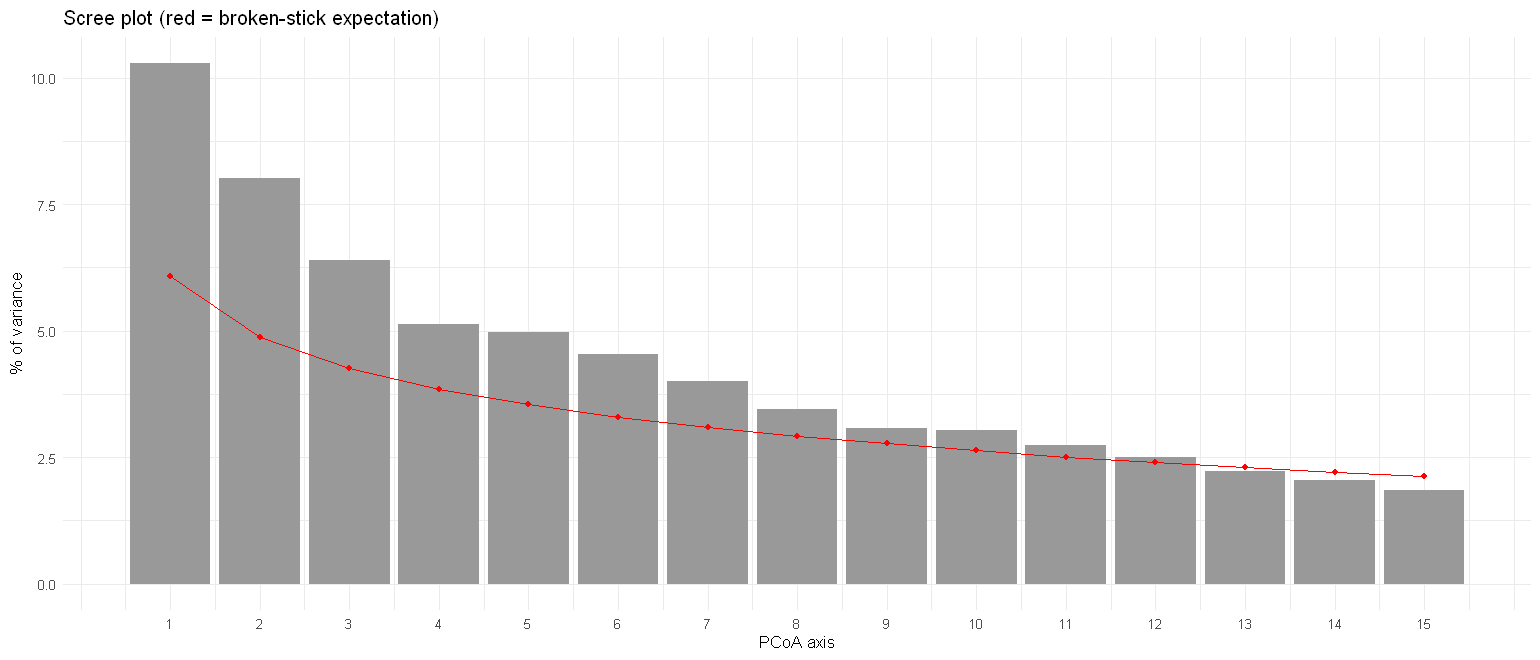

In [103]:
options(repr.plot.width = 14, repr.plot.height = 6)

comm_h <- decostand(comm, method = "hellinger")   # plots x taxa
d_h    <- dist(comm_h)                            # Hellinger distance

pcoa <- cmdscale(d_h, k = 10, eig = TRUE)
ev   <- pcoa$eig
cat("Negative eigenvalues:", sum(ev < -1e-8), "(expected 0: Euclidean distance)\n")

ev_pos <- ev[ev > 1e-8]
eig_tbl <- tibble(axis = seq_along(ev_pos),
                  eigenvalue = ev_pos,
                  pct = 100 * ev_pos / sum(ev_pos),
                  cum_pct = cumsum(100 * ev_pos / sum(ev_pos)),
                  broken_stick = 100 * bstick(length(ev_pos)))
eig_tbl %>% head(10) %>% kable(digits = 2, caption = "First 10 PCoA axes")
cat("Axes with variance above the broken-stick expectation:", sum(eig_tbl$pct > eig_tbl$broken_stick), "\n")

eig_tbl %>% head(15) %>%
  ggplot(aes(axis)) +
  geom_col(aes(y = pct), fill = "grey60") +
  geom_line(aes(y = broken_stick), colour = "red") + geom_point(aes(y = broken_stick), colour = "red") +
  scale_x_continuous(breaks = 1:15) +
  labs(x = "PCoA axis", y = "% of variance", title = "Scree plot (red = broken-stick expectation)")

pc_lab <- function(i) sprintf("PCoA %d (%.1f%%)", i, eig_tbl$pct[i])

## 9.2 Ordination of the plots

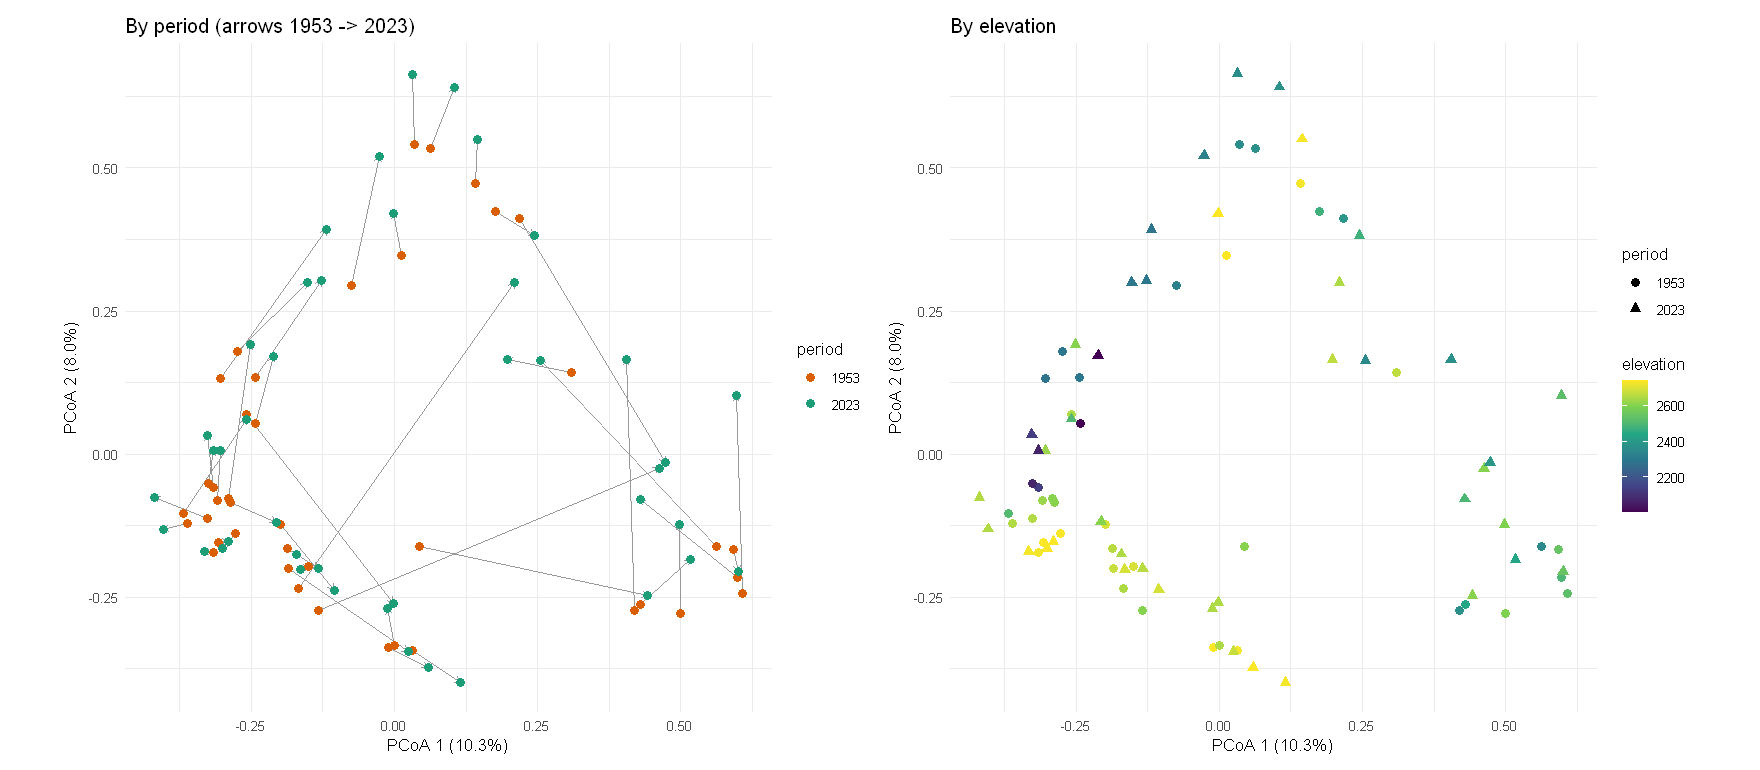

In [104]:
options(repr.plot.width = 16, repr.plot.height = 7)

sc <- as.data.frame(pcoa$points[, 1:4]); names(sc) <- paste0("PCoA", 1:4)
sc <- sc %>% rownames_to_column("plot_id") %>%
  left_join(env %>% select(plot_id, base_id, period, elevation, assoc_abbr, mineralogy), by = "plot_id")

sc_w <- sc %>% filter(base_id %in% pair_ids_sp) %>%
  select(base_id, period, PCoA1, PCoA2) %>%
  pivot_wider(names_from = period, values_from = c(PCoA1, PCoA2))

p_period <- ggplot() +
  geom_segment(data = sc_w, aes(x = PCoA1_1953, y = PCoA2_1953, xend = PCoA1_2023, yend = PCoA2_2023),
               colour = "grey60", arrow = arrow(length = unit(1.5, "mm"))) +
  geom_point(data = sc, aes(PCoA1, PCoA2, colour = period), size = 2.5) +
  scale_colour_manual(values = period_cols) +
  coord_equal() + labs(x = pc_lab(1), y = pc_lab(2), title = "By period (arrows 1953 -> 2023)")

p_elev <- ggplot(sc, aes(PCoA1, PCoA2, colour = elevation, shape = period)) +
  geom_point(size = 2.5) + scale_colour_viridis_c() +
  coord_equal() + labs(x = pc_lab(1), y = pc_lab(2), title = "By elevation")

p_period + p_elev

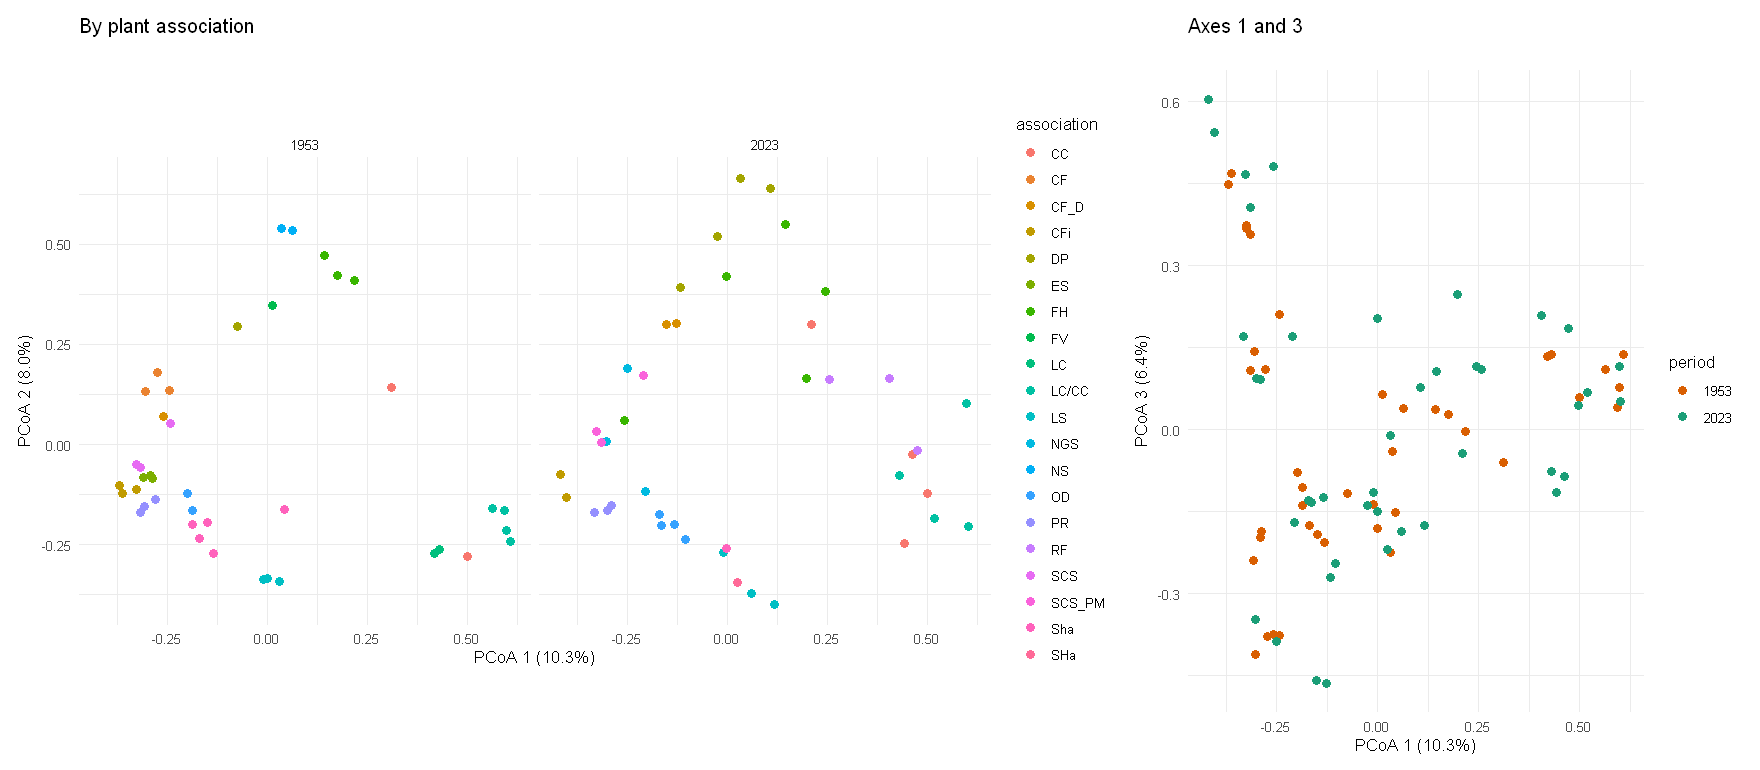

In [105]:
p_assoc <- ggplot(sc, aes(PCoA1, PCoA2, colour = assoc_abbr)) +
  geom_point(size = 2.5) + facet_wrap(~ period) + coord_equal() +
  labs(x = pc_lab(1), y = pc_lab(2), colour = "association", title = "By plant association")

p_13 <- ggplot(sc, aes(PCoA1, PCoA3, colour = period)) +
  geom_point(size = 2.5) + scale_colour_manual(values = period_cols) +
  labs(x = pc_lab(1), y = pc_lab(3), title = "Axes 1 and 3")

p_assoc + p_13 + plot_layout(widths = c(2, 1))

## 9.3 Which species drive the axes?

Correlation between each taxon's Hellinger-transformed cover and the PCoA axes (taxa present in at least 5 plots).

Warning message:
"ggrepel: 3 unlabeled data points (too many overlaps). Consider increasing max.overlaps"


axis,taxon,r
PCoA1,Cetraria islandica,0.75
PCoA1,Carex curvula,0.73
PCoA1,Loiseleuria procumbens,0.73
PCoA1,Avenula versicolor,0.67
PCoA1,Cladonia rangiferina,0.65
PCoA1,Primula daonensis,0.49
PCoA1,Hieracium alpinum,0.49
PCoA1,Thamnolia vermicularis,0.44
PCoA1,Poa alpina,0.42
PCoA1,Pulsatilla vernalis,0.42


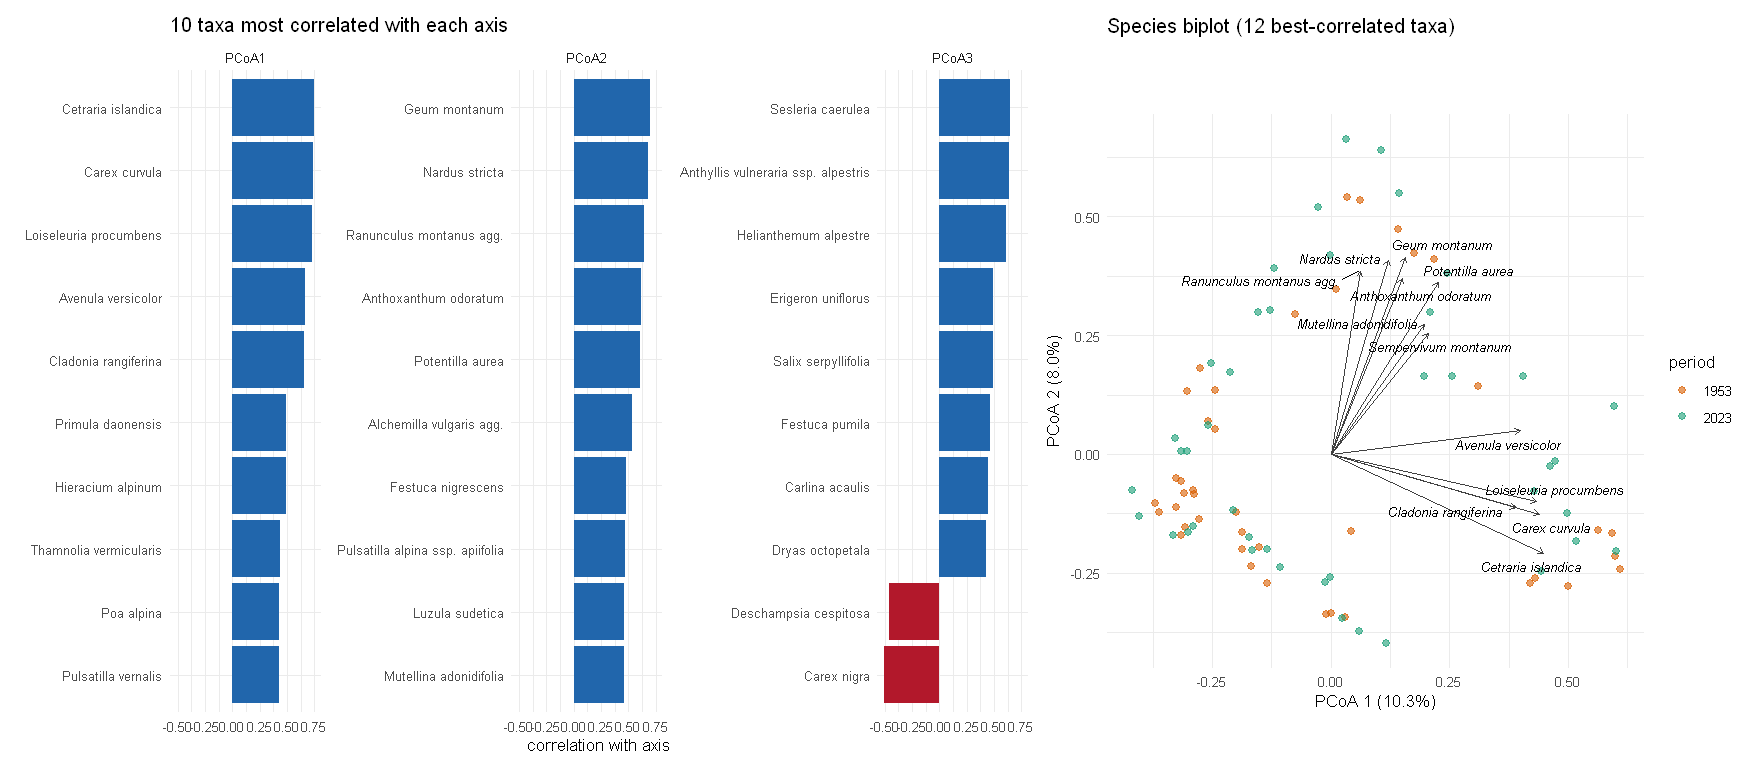

In [106]:
options(repr.plot.width = 16, repr.plot.height = 7)

ok <- colSums(comm > 0) >= 5
r_ax <- cor(comm_h[, ok], pcoa$points[, 1:3])
colnames(r_ax) <- paste0("PCoA", 1:3)
r_tbl <- as_tibble(r_ax, rownames = "taxon")

top <- map_dfr(1:3, function(k) {
  ax <- paste0("PCoA", k)
  r_tbl %>% select(taxon, r = all_of(ax)) %>%
    slice_max(abs(r), n = 10, with_ties = FALSE) %>% mutate(axis = ax)
}) %>%
  group_by(axis) %>% arrange(r, .by_group = TRUE) %>% ungroup() %>%
  mutate(key = factor(paste(axis, taxon, sep = "__"), levels = unique(paste(axis, taxon, sep = "__"))))

p_top <- ggplot(top, aes(r, key, fill = r > 0)) + geom_col() +
  facet_wrap(~ axis, scales = "free_y") +
  scale_y_discrete(labels = function(x) sub(".*__", "", x)) +
  scale_fill_manual(values = c("TRUE" = "#2166AC", "FALSE" = "#B2182B"), guide = "none") +
  labs(x = "correlation with axis", y = NULL, title = "10 taxa most correlated with each axis")

mult <- 0.9 * max(abs(c(sc$PCoA1, sc$PCoA2)))
bip <- r_tbl %>% mutate(len = sqrt(PCoA1^2 + PCoA2^2)) %>% slice_max(len, n = 12, with_ties = FALSE)

p_bip <- ggplot(sc, aes(PCoA1, PCoA2)) +
  geom_point(aes(colour = period), size = 2, alpha = .6) +
  geom_segment(data = bip, aes(x = 0, y = 0, xend = PCoA1 * mult, yend = PCoA2 * mult),
               arrow = arrow(length = unit(1.5, "mm")), colour = "grey25") +
  geom_text_repel(data = bip, aes(PCoA1 * mult, PCoA2 * mult, label = taxon), size = 3, fontface = "italic") +
  scale_colour_manual(values = period_cols) + coord_equal() +
  labs(x = pc_lab(1), y = pc_lab(2), title = "Species biplot (12 best-correlated taxa)")

p_top + p_bip + plot_layout(widths = c(1.6, 1))

top %>% arrange(axis, desc(abs(r))) %>% mutate(r = round(r, 2)) %>% select(axis, taxon, r) %>%
  kable(caption = "Top taxa per axis")

## 9.4 Environmental interpretation (`envfit` on the PCoA axes)

variable,r2,p,p_adj
liv_light,0.519,0.001,0.002
liv_temp,0.459,0.001,0.002
northness,0.408,0.001,0.002
liv_ph,0.395,0.001,0.002
p_competitive,0.361,0.001,0.002
richness,0.279,0.001,0.002
liv_nutrients,0.278,0.001,0.002
cover_total,0.269,0.001,0.002
p_stress_tol,0.266,0.001,0.002
liv_moisture,0.209,0.001,0.002


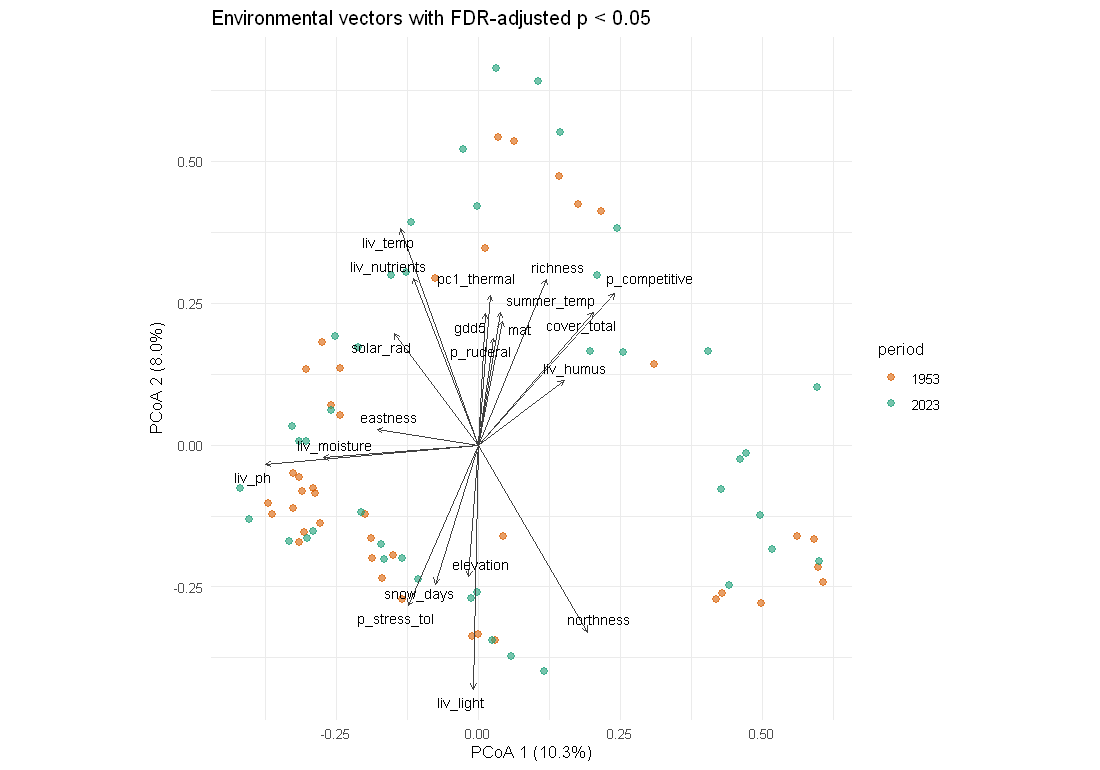

In [107]:
options(repr.plot.width = 10, repr.plot.height = 7)

ef_vars <- c("elevation", "slope", "eastness", "northness", "solar_rad", "mat", "map", "summer_temp",
             "gdd5", "snow_days", "liv_temp", "liv_light", "liv_ph", "liv_nutrients", "liv_humus",
             "liv_moisture", "pc1_thermal", "pc2_soil", "richness", "cover_total",
             "p_competitive", "p_stress_tol", "p_ruderal")

ef <- envfit(pcoa$points[, 1:2], as.data.frame(env_sp %>% select(all_of(ef_vars))),
             permutations = 999, na.rm = TRUE)

ef_tbl <- tibble(variable = names(ef$vectors$r), r2 = ef$vectors$r, p = ef$vectors$pvals) %>%
  mutate(p_adj = p.adjust(p, "BH")) %>% arrange(desc(r2))
ef_tbl %>% mutate(across(where(is.numeric), ~ round(.x, 3))) %>%
  kable(caption = "Environmental vectors fitted to PCoA axes 1-2")

arr <- as.data.frame(ef$vectors$arrows * sqrt(ef$vectors$r))
names(arr) <- c("x", "y"); arr$variable <- rownames(arr)
arr <- arr %>% left_join(ef_tbl %>% select(variable, p_adj), by = "variable") %>% filter(p_adj < 0.05)

ggplot(sc, aes(PCoA1, PCoA2)) +
  geom_point(aes(colour = period), size = 2, alpha = .6) +
  geom_segment(data = arr, aes(x = 0, y = 0, xend = x * mult, yend = y * mult),
               arrow = arrow(length = unit(1.5, "mm")), colour = "grey25") +
  geom_text_repel(data = arr, aes(x * mult, y * mult, label = variable), size = 3.2) +
  scale_colour_manual(values = period_cols) + coord_equal() +
  labs(x = pc_lab(1), y = pc_lab(2), title = "Environmental vectors with FDR-adjusted p < 0.05")

## 9.5 Is the 1953 vs 2023 difference significant? (paired PERMANOVA)

Years are permuted *within* each plot, which respects the repeated-measures design. `betadisper` checks that the two periods do not differ in dispersion, which would confound the PERMANOVA. The Procrustes test compares this ordination with a Bray-Curtis one.

In [108]:
perm_paired <- how(nperm = 999, blocks = factor(env_sp$base_id))
adonis2(d_h ~ period, data = env_sp, permutations = perm_paired)

bd_h <- betadisper(d_h, env_sp$period)
permutest(bd_h, permutations = 999)

pro <- protest(pcoa$points[, 1:2], cmdscale(vegdist(sqrt(comm), "bray"), k = 2), permutations = 999)
pro

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Model,1,1.002435,0.01356542,1.11391,0.001
Residual,81,72.893922,0.98643458,NA,NA
Total,82,73.896357,1.00000000,NA,NA



Permutation test for homogeneity of multivariate dispersions
Permutation: free
Number of permutations: 999

Response: Distances
          Df   Sum Sq  Mean Sq      F N.Perm Pr(>F)  
Groups     1 0.018823 0.018823 5.3582    999  0.028 *
Residuals 81 0.284553 0.003513                       
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1


Call:
protest(X = pcoa$points[, 1:2], Y = cmdscale(vegdist(sqrt(comm),      "bray"), k = 2), permutations = 999) 

Procrustes Sum of Squares (m12 squared):        0.05702 
Correlation in a symmetric Procrustes rotation: 0.9711 
Significance:  0.001 

Permutation: free
Number of permutations: 999


## 9.6 Displacement of each plot along the axes (1953 -> 2023)

axis,mean_shift,median_shift,p_wilcoxon
PCoA1,0.062,0.031,0.011
PCoA2,0.072,0.073,0.005
PCoA3,0.029,0.032,0.127


Spearman rho between PCoA displacement and Bray-Curtis turnover: 0.13 


`geom_smooth()` using formula = 'y ~ x'


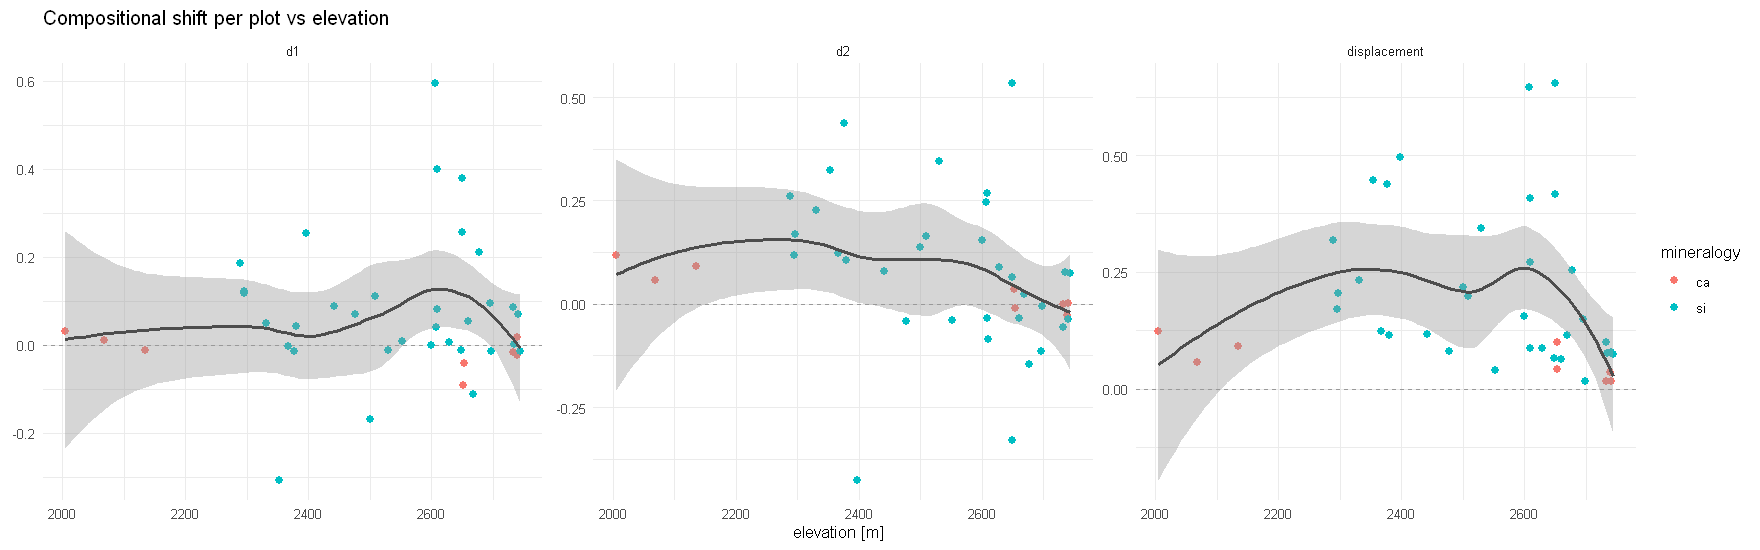

In [109]:
options(repr.plot.width = 16, repr.plot.height = 5)

shift <- sc %>% filter(base_id %in% pair_ids_sp) %>%
  select(base_id, period, PCoA1, PCoA2, PCoA3) %>%
  pivot_wider(names_from = period, values_from = c(PCoA1, PCoA2, PCoA3)) %>%
  mutate(d1 = PCoA1_2023 - PCoA1_1953, d2 = PCoA2_2023 - PCoA2_1953, d3 = PCoA3_2023 - PCoA3_1953,
         displacement = sqrt(d1^2 + d2^2)) %>%
  left_join(env %>% filter(period == "1953") %>% select(base_id, elevation, assoc_abbr, mineralogy), by = "base_id") %>%
  left_join(pair_turn %>% select(base_id, bray), by = "base_id")

tibble(axis = c("PCoA1", "PCoA2", "PCoA3"),
       mean_shift   = c(mean(shift$d1), mean(shift$d2), mean(shift$d3)),
       median_shift = c(median(shift$d1), median(shift$d2), median(shift$d3)),
       p_wilcoxon   = c(wilcox.test(shift$d1)$p.value, wilcox.test(shift$d2)$p.value, wilcox.test(shift$d3)$p.value)) %>%
  kable(digits = 3, caption = "Shift along each axis (2023 - 1953); H0: no directional shift")

cat("Spearman rho between PCoA displacement and Bray-Curtis turnover:",
    round(cor(shift$displacement, shift$bray, method = "spearman"), 2), "\n")

shift %>% pivot_longer(c(d1, d2, displacement), names_to = "metric") %>%
  ggplot(aes(elevation, value, colour = mineralogy)) +
  geom_hline(yintercept = 0, linetype = 2, colour = "grey60") +
  geom_point(size = 2) + geom_smooth(aes(group = 1), method = "loess", se = TRUE, colour = "grey30") +
  facet_wrap(~ metric, scales = "free_y") +
  labs(x = "elevation [m]", y = NULL, title = "Compositional shift per plot vs elevation")

# 10. Species-focused analyses

Questions addressed in this section:
1. Which taxa are the most frequent, the most abundant, and the dominant ones?
2. Which taxa disappear or appear between 1953 and 2023 and how reliable is that signal?
3. How does the cover of individual taxa change?
4. Do taxa shift along the elevation gradient?
5. Is there evidence of interactions (competition, replacement) between taxa?

**Pairing.** Paired analyses use the 41 plots with species data in both years (`pair_ids_sp`). Matrices `A` (1953) and `B` (2023) have the same plot order.

In [110]:
# ---- shared objects for section 10 ----
A <- comm[pair_ids_sp, , drop = FALSE]                  # 1953
B <- comm[paste0(pair_ids_sp, "_23"), , drop = FALSE]   # 2023
elev_pair <- env$elevation[match(pair_ids_sp, env$plot_id)]   # elevation of each pair (1953 plot)

n1953 <- sum(env_sp$period == "1953"); n2023 <- sum(env_sp$period == "2023")
nonvasc_taxa <- setdiff(colnames(comm), vasc_taxa)

el_mean <- mean(env_sp$elevation); el_sd <- sd(env_sp$elevation)
dat_el  <- env_sp %>% select(plot_id, period, elevation) %>% mutate(elev_z = (elevation - el_mean) / el_sd)

# cover-weighted mean elevation (optimum) of each taxon over all plots
opt_all <- long %>% filter(cover > 0) %>% group_by(taxon) %>%
  summarise(opt = weighted.mean(elevation, cover), .groups = "drop")

cat("Plots 1953:", n1953, "| plots 2023:", n2023, "| paired:", length(pair_ids_sp), "\n")
cat("Vascular taxa:", length(vasc_taxa), "| non-vascular taxa:", length(nonvasc_taxa), "\n")

Plots 1953: 41 | plots 2023: 42 | paired: 41 
Vascular taxa: 313 | non-vascular taxa: 60 


## 10.1 Most frequent, most abundant and dominant taxa

taxon,group,n_plots,freq_1953,freq_2023,mean_cover,mean_cover_when_present,max_cover,pct_1953,pct_2023
Poa alpina,vascular,52,27,25,4.74,7.56,50.0,65.85,59.52
Persicaria vivipara,vascular,40,16,24,1.12,2.33,30.0,39.02,57.14
Leucanthemopsis alpina,vascular,39,19,20,1.60,3.41,30.0,46.34,47.62
Mutellina adonidifolia,vascular,35,11,24,3.64,8.62,50.0,26.83,57.14
Agrostis rupestris,vascular,33,17,16,1.00,2.52,10.0,41.46,38.10
Cetraria islandica,non-vascular (moss/lichen),33,14,19,5.43,13.67,50.0,34.15,45.24
Scorzoneroides helvetica,vascular,33,9,24,2.31,5.82,50.0,21.95,57.14
Phyteuma hemisphaericum,vascular,32,16,16,0.88,2.28,50.0,39.02,38.10
Potentilla aurea,vascular,29,8,21,3.39,9.70,30.0,19.51,50.00
Carex curvula,vascular,28,14,14,8.33,24.69,90.0,34.15,33.33


taxon,group,mean_cover,n_plots,pct_1953,pct_2023
Carex curvula,vascular,8.33,28,34.15,33.33
Loiseleuria procumbens,vascular,7.47,16,17.07,21.43
Nardus stricta,vascular,5.80,28,19.51,47.62
Cetraria islandica,non-vascular (moss/lichen),5.43,33,34.15,45.24
Poa alpina,vascular,4.74,52,65.85,59.52
Salix herbacea,vascular,3.87,26,14.63,47.62
Mutellina adonidifolia,vascular,3.64,35,26.83,57.14
Avenula versicolor,vascular,3.63,27,34.15,30.95
Eriophorum scheuchzeri,vascular,3.50,6,9.76,4.76
Potentilla aurea,vascular,3.39,29,19.51,50.00


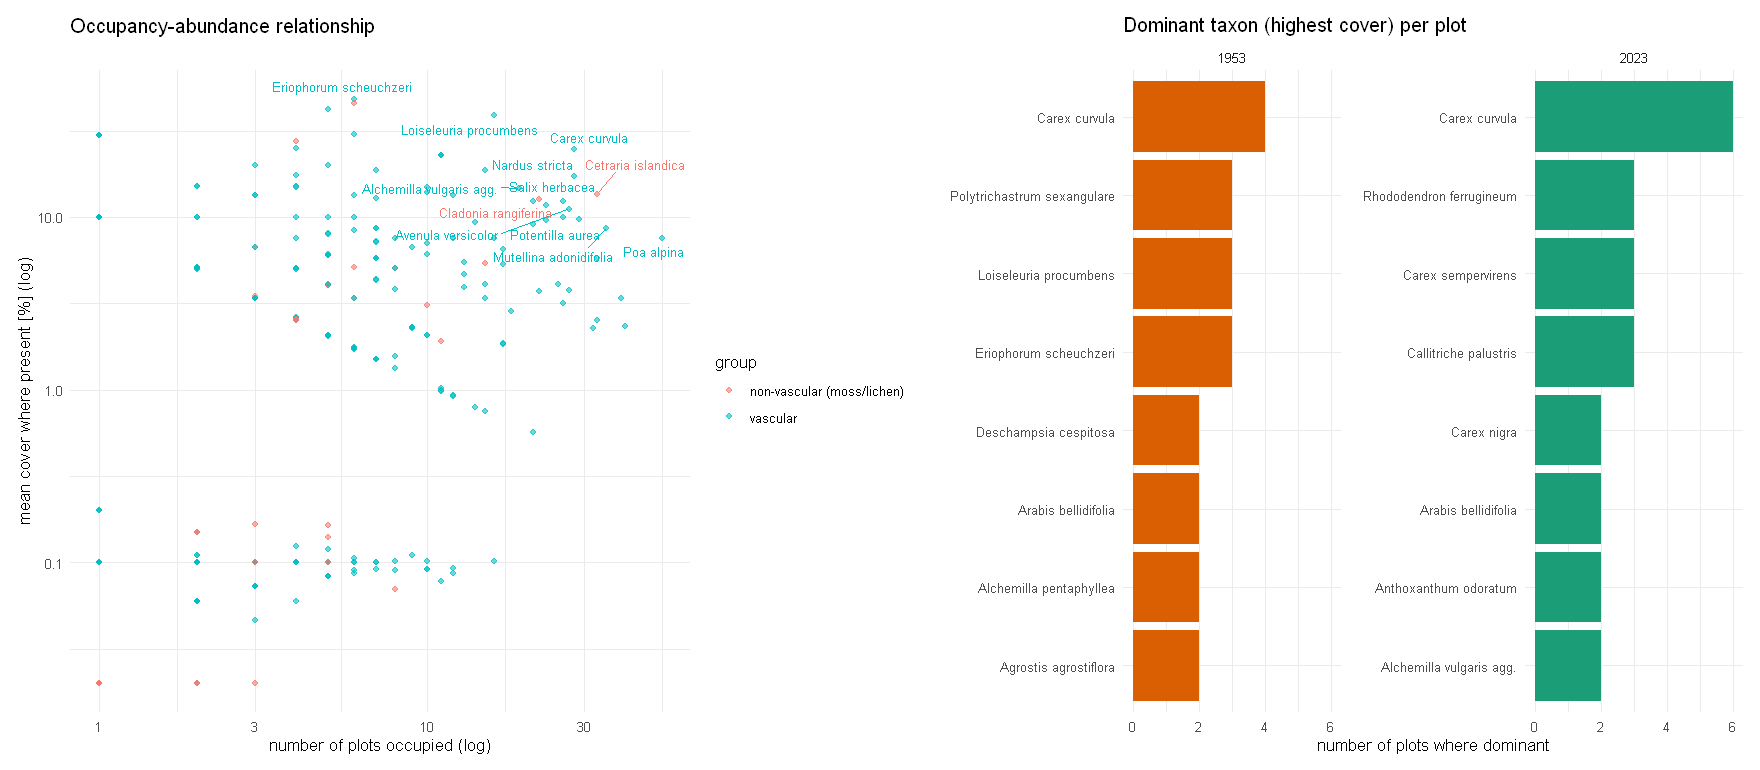

In [111]:
options(repr.plot.width = 16, repr.plot.height = 7)

pres <- comm > 0
sp_overview <- tibble(
  taxon = colnames(comm),
  group = taxa_tbl$group[match(colnames(comm), taxa_tbl$taxon)],
  n_plots = colSums(pres),
  freq_1953 = colSums(pres[env_sp$period == "1953", , drop = FALSE]),
  freq_2023 = colSums(pres[env_sp$period == "2023", , drop = FALSE]),
  mean_cover = colMeans(comm),
  mean_cover_when_present = map_dbl(seq_len(ncol(comm)), ~ mean(comm[comm[, .x] > 0, .x])),
  max_cover = apply(comm, 2, max)
) %>%
  mutate(pct_1953 = 100 * freq_1953 / n1953, pct_2023 = 100 * freq_2023 / n2023)

sp_overview %>% arrange(desc(n_plots)) %>% head(25) %>%
  mutate(across(where(is.numeric), ~ round(.x, 2))) %>%
  kable(caption = "25 most frequent taxa (n_plots = number of plots where present, out of 83)")
write_csv(sp_overview, "outputs/species_overview.csv")

sp_overview %>% slice_max(mean_cover, n = 15, with_ties = FALSE) %>%
  select(taxon, group, mean_cover, n_plots, pct_1953, pct_2023) %>%
  mutate(across(where(is.numeric), ~ round(.x, 2))) %>%
  kable(caption = "15 taxa with the highest mean cover (over all plots)")

# occupancy-abundance relationship
p_oa <- ggplot(sp_overview, aes(n_plots, mean_cover_when_present, colour = group)) +
  geom_point(alpha = .6) +
  geom_text_repel(data = ~ slice_max(.x, mean_cover, n = 12, with_ties = FALSE),
                  aes(label = taxon), size = 3, show.legend = FALSE) +
  scale_x_log10() + scale_y_log10() +
  labs(x = "number of plots occupied (log)", y = "mean cover where present [%] (log)",
       title = "Occupancy-abundance relationship")

# dominant taxon per plot
dom <- tibble(plot_id = rownames(comm),
              dominant = colnames(comm)[max.col(comm, ties.method = "first")],
              dom_cover = apply(comm, 1, max)) %>%
  left_join(env %>% select(plot_id, period), by = "plot_id")

p_dom <- dom %>% count(period, dominant) %>% group_by(period) %>%
  slice_max(n, n = 8, with_ties = FALSE) %>% ungroup() %>%
  ggplot(aes(n, reorder(dominant, n), fill = period)) + geom_col() +
  facet_wrap(~ period, scales = "free_y") +
  scale_fill_manual(values = period_cols) + guides(fill = "none") +
  labs(x = "number of plots where dominant", y = NULL, title = "Dominant taxon (highest cover) per plot")

p_oa + p_dom

## 10.2 Which taxa disappear and which appear?

Within the 41 paired plots, a taxon is **lost** in a plot if present in 1953 and absent in 2023, and **gained** in the opposite case. **Persistence** is the share of 1953 occurrences that are still present in 2023. Because many records are rare (cover r or +), part of this turnover can be sampling noise (*pseudo-turnover*); the last chunk checks that.

Taxa recorded only in 1953 (whole dataset): 93 
Taxa recorded only in 2023 (whole dataset): 84 
Taxa recorded in both: 196 


taxon,status,group,n_plots,mean_cover_when_present,max_cover
Nephromopsis nivalis,only 1953,non-vascular (moss/lichen),5,0.16,0.20
Epilobium alsinifolium,only 1953,vascular,4,2.60,10.00
Sarmentypnum exannulatum,only 1953,non-vascular (moss/lichen),4,27.55,70.00
Tortella tortuosa,only 1953,non-vascular (moss/lichen),4,2.58,10.00
Briza media,only 1953,vascular,4,2.58,10.00
Epilobium anagallidifolium,only 1953,vascular,3,3.40,10.00
Webera commutata,only 1953,non-vascular (moss/lichen),3,0.10,0.10
Anthelia juratzkana,only 1953,non-vascular (moss/lichen),3,0.17,0.20
Ochrolechia sp.,only 1953,non-vascular (moss/lichen),3,3.37,10.00
Drepanocladus aduncus,only 1953,non-vascular (moss/lichen),3,6.70,10.00


taxon,group,occ_1953,lost,retained,gained,persistence,p_adj
Nephromopsis nivalis,non-vascular (moss/lichen),5,5,0,0,0.000,0.772
Erigeron uniflorus,vascular,7,6,1,1,0.143,0.861
Phleum rhaeticum,vascular,6,5,1,3,0.167,1.000
Cetraria aculeata,non-vascular (moss/lichen),5,4,1,0,0.200,0.861
Cladonia pyxidata,non-vascular (moss/lichen),5,4,1,0,0.200,0.861
Gentiana bavarica,vascular,5,4,1,4,0.200,1.000
Soldanella alpina,vascular,5,4,1,4,0.200,1.000
Trifolium pratense ssp. nivale,vascular,5,4,1,1,0.200,1.000
Antennaria dioica,vascular,7,5,2,2,0.286,1.000
Sibbaldia procumbens,vascular,7,5,2,7,0.286,1.000


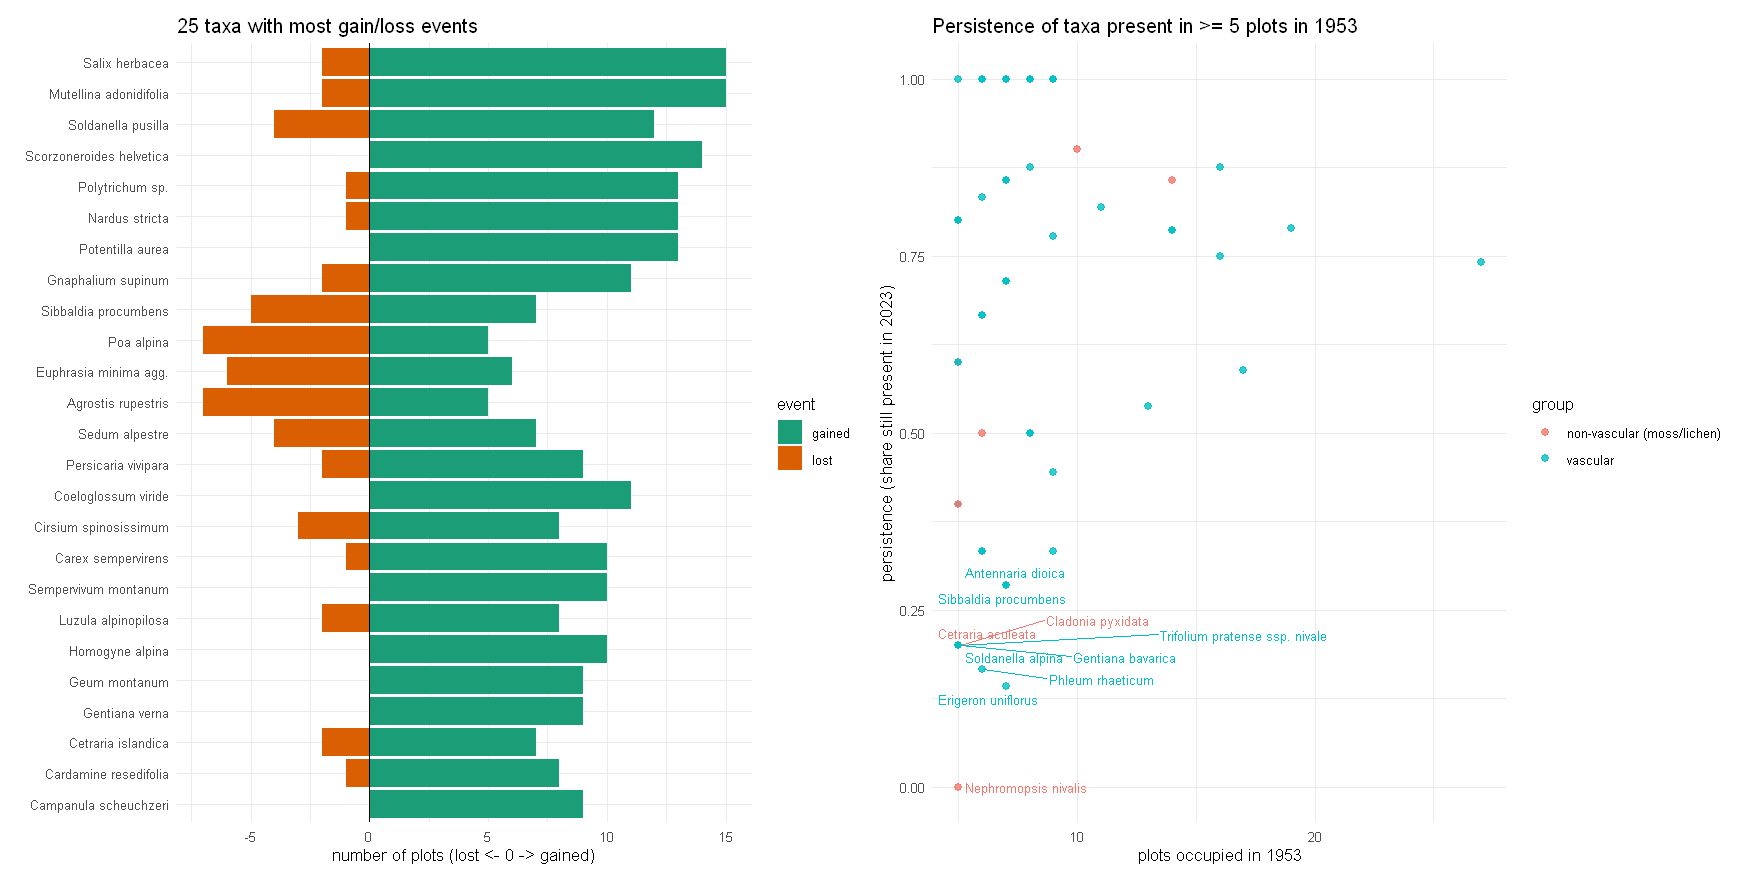

In [112]:
options(repr.plot.width = 16, repr.plot.height = 8)

sp_dyn <- sp_change %>%
  mutate(retained = occ_1953 - lost,
         persistence = if_else(occ_1953 > 0, retained / occ_1953, NA_real_),
         turnover_events = lost + gained)

cat("Taxa recorded only in 1953 (whole dataset):", sum(tax_status$status == "only 1953"), "\n")
cat("Taxa recorded only in 2023 (whole dataset):", sum(tax_status$status == "only 2023"), "\n")
cat("Taxa recorded in both:", sum(tax_status$status == "both"), "\n")

tax_status %>% filter(status != "both") %>% select(taxon, status) %>%
  left_join(sp_overview %>% select(taxon, group, n_plots, mean_cover_when_present, max_cover), by = "taxon") %>%
  group_by(status) %>% slice_max(n_plots, n = 15, with_ties = FALSE) %>% ungroup() %>%
  mutate(across(where(is.numeric), ~ round(.x, 2))) %>%
  kable(caption = "Most widespread taxa found in only one of the two years")

# gains and losses per taxon (paired plots)
top_turn <- sp_dyn %>% slice_max(turnover_events, n = 25, with_ties = FALSE) %>% arrange(turnover_events)
lg <- top_turn %>% transmute(taxon = factor(taxon, levels = taxon), lost = -lost, gained = gained) %>%
  pivot_longer(-taxon, names_to = "event", values_to = "n")

p_lg <- ggplot(lg, aes(n, taxon, fill = event)) + geom_col() + geom_vline(xintercept = 0) +
  scale_fill_manual(values = c(lost = "#D95F02", gained = "#1B9E77")) +
  labs(x = "number of plots (lost <- 0 -> gained)", y = NULL,
       title = "25 taxa with most gain/loss events")

p_pers <- sp_dyn %>% filter(occ_1953 >= 5) %>%
  ggplot(aes(occ_1953, persistence, colour = group)) + geom_point(size = 2, alpha = .8) +
  geom_text_repel(data = ~ slice_min(.x, persistence, n = 10, with_ties = FALSE),
                  aes(label = taxon), size = 3, show.legend = FALSE) +
  labs(x = "plots occupied in 1953", y = "persistence (share still present in 2023)",
       title = "Persistence of taxa present in >= 5 plots in 1953")

p_lg + p_pers

sp_dyn %>% filter(occ_1953 >= 5) %>% arrange(persistence) %>% head(15) %>%
  select(taxon, group, occ_1953, lost, retained, gained, persistence, p_adj) %>%
  mutate(across(where(is.numeric), ~ round(.x, 3))) %>%
  kable(caption = "Taxa with the lowest persistence (present in >= 5 plots in 1953)")

type,n_records,median_cover,pct_cover_le_0.1
gained (2023 cover),733,0.1,77.6
lost (1953 cover),434,0.1,61.5
retained (1953 cover),505,0.2,44.2


type,non-vascular (moss/lichen),vascular
gained (2023 cover),38,695
lost (1953 cover),104,330
retained (1953 cover),44,461


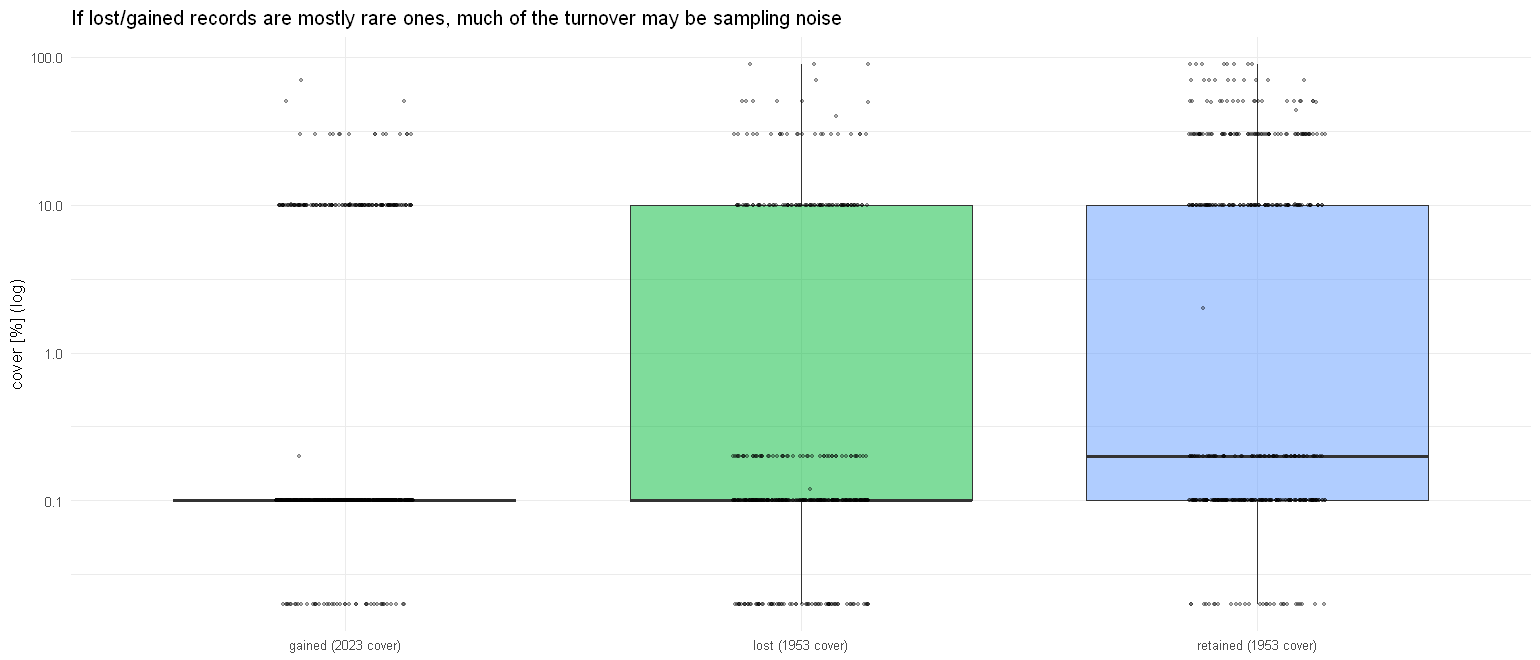

In [113]:
options(repr.plot.width = 14, repr.plot.height = 6)

# Cover of each lost / gained / retained record: are changes concentrated in rare records?
il <- which(A > 0 & B == 0, arr.ind = TRUE)
ig <- which(A == 0 & B > 0, arr.ind = TRUE)
ir <- which(A > 0 & B > 0, arr.ind = TRUE)

events <- bind_rows(
  tibble(type = "lost (1953 cover)",     taxon = colnames(A)[il[, 2]], cover = A[il]),
  tibble(type = "gained (2023 cover)",   taxon = colnames(A)[ig[, 2]], cover = B[ig]),
  tibble(type = "retained (1953 cover)", taxon = colnames(A)[ir[, 2]], cover = A[ir])
) %>% left_join(taxa_tbl %>% select(taxon, group, resolution), by = "taxon")

events %>% group_by(type) %>%
  summarise(n_records = n(), median_cover = median(cover),
            pct_cover_le_0.1 = round(100 * mean(cover <= 0.1), 1), .groups = "drop") %>%
  kable(caption = "Share of very rare records (cover <= 0.1 %) among lost, gained and retained records")

events %>% count(type, group) %>% pivot_wider(names_from = group, values_from = n, values_fill = 0) %>%
  kable(caption = "Events by taxon group")

ggplot(events, aes(type, cover, fill = type)) +
  geom_boxplot(outlier.shape = NA, alpha = .5) + geom_jitter(width = .15, alpha = .3, size = 1) +
  scale_y_log10() + guides(fill = "none") +
  labs(x = NULL, y = "cover [%] (log)",
       title = "If lost/gained records are mostly rare ones, much of the turnover may be sampling noise")

## 10.3 Cover changes of individual taxa (paired plots)

Paired Wilcoxon test on cover in the same plots, for taxa with at least 8 occurrences in total, with Benjamini-Hochberg correction.

taxon,n_plots_present,mean_1953,mean_2023,mean_diff,p,p_adj
Polytrichum sp.,14,0.000488,1.97000,1.9700,0.00131,0.0770
Carex sempervirens,16,0.749000,5.62000,4.8800,0.00199,0.0770
Coeloglossum viride,11,0.000000,0.26200,0.2620,0.00289,0.0770
Luzula multiflora agg.,9,0.000000,0.50500,0.5050,0.00601,0.0790
Gentiana verna,10,0.002440,0.26400,0.2610,0.00606,0.0790
Poa supina,9,0.266000,0.00732,-0.2590,0.00606,0.0790
Cardamine resedifolia,10,0.000976,0.02000,0.0190,0.00691,0.0790
Pulsatilla vernalis,9,0.002440,0.02000,0.0176,0.00833,0.0833
Sempervivum montanum,13,0.009760,0.02980,0.0200,0.01150,0.1020
Anthoxanthum odoratum,17,2.200000,4.16000,1.9500,0.01630,0.1300


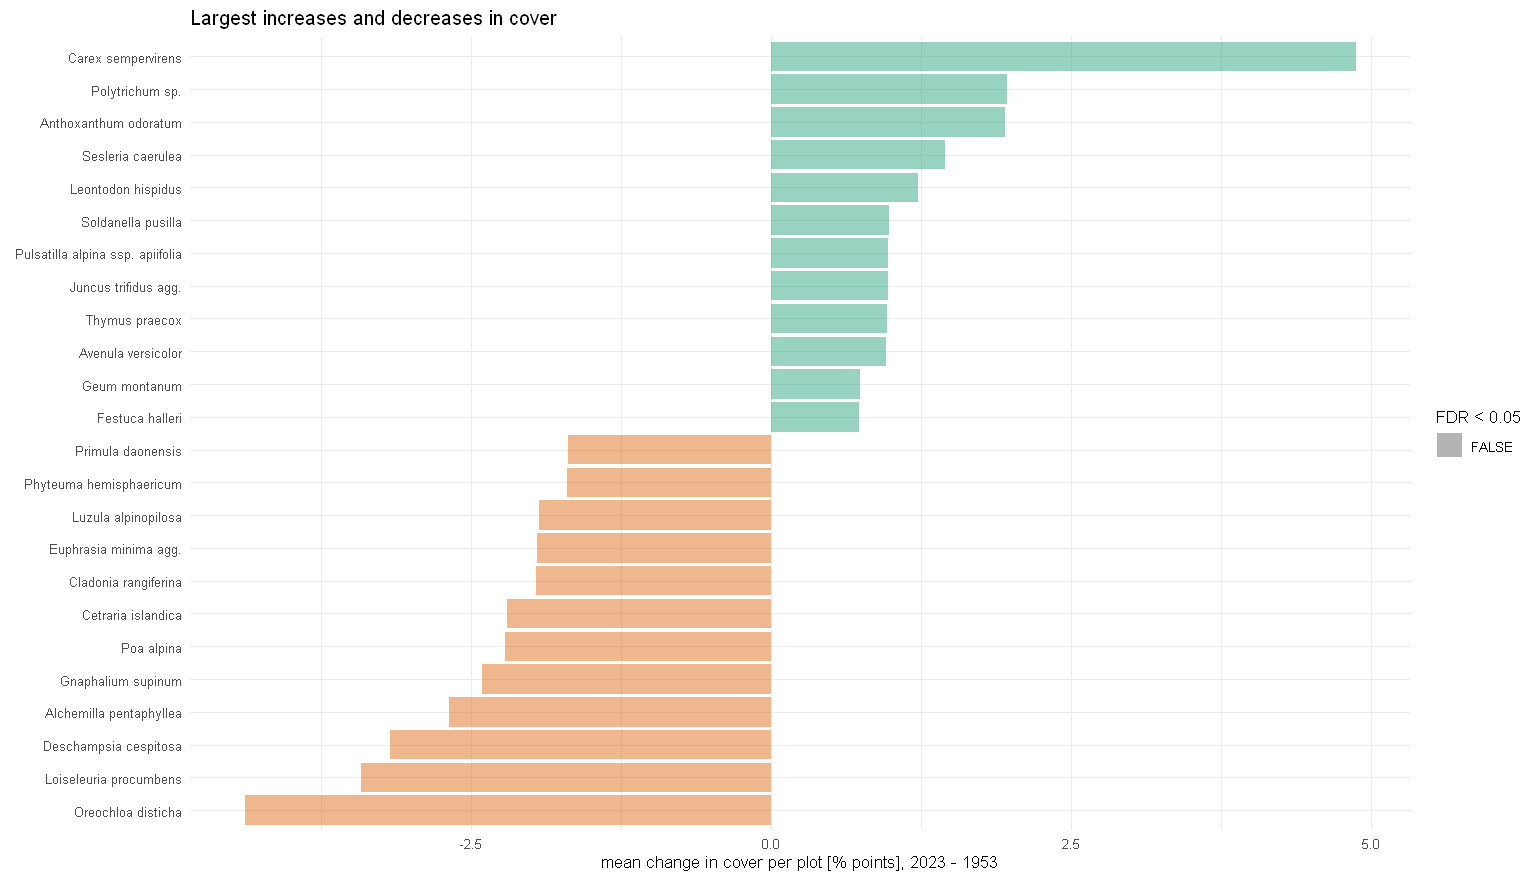

In [114]:
options(repr.plot.width = 14, repr.plot.height = 8)

cand <- sp_change %>% filter(occ_1953 + occ_2023 >= 8) %>% pull(taxon)

cov_tests <- map_dfr(cand, function(tx) {
  a <- A[, tx]; b <- B[, tx]; d <- b - a
  tibble(taxon = tx, n_plots_present = sum(a > 0 | b > 0),
         mean_1953 = mean(a), mean_2023 = mean(b), mean_diff = mean(d),
         p = if (all(d == 0)) NA_real_ else suppressWarnings(wilcox.test(b, a, paired = TRUE, exact = FALSE)$p.value))
}) %>% mutate(p_adj = p.adjust(p, "BH")) %>% arrange(p)

cov_tests %>% head(20) %>% mutate(across(where(is.numeric), ~ signif(.x, 3))) %>%
  kable(caption = "Taxa with the strongest paired cover change")
write_csv(cov_tests, "outputs/species_cover_tests.csv")

bind_rows(slice_max(cov_tests, mean_diff, n = 12, with_ties = FALSE),
          slice_min(cov_tests, mean_diff, n = 12, with_ties = FALSE)) %>%
  distinct(taxon, .keep_all = TRUE) %>%
  mutate(sig = coalesce(p_adj < 0.05, FALSE)) %>%
  ggplot(aes(mean_diff, reorder(taxon, mean_diff), fill = mean_diff > 0, alpha = sig)) +
  geom_col() +
  scale_fill_manual(values = c("TRUE" = "#1B9E77", "FALSE" = "#D95F02"), guide = "none") +
  scale_alpha_manual(values = c("TRUE" = 1, "FALSE" = .45)) +
  labs(x = "mean change in cover per plot [% points], 2023 - 1953", y = NULL, alpha = "FDR < 0.05",
       title = "Largest increases and decreases in cover")

In [115]:
# Vascular vs non-vascular: richness and cover per plot, paired
grp <- function(M, per) tibble(
  base_id = pair_ids_sp, period = per,
  vasc_cover    = rowSums(M[, vasc_taxa, drop = FALSE]),
  nonvasc_cover = rowSums(M[, nonvasc_taxa, drop = FALSE]),
  vasc_richness    = rowSums(M[, vasc_taxa, drop = FALSE] > 0),
  nonvasc_richness = rowSums(M[, nonvasc_taxa, drop = FALSE] > 0))

grp_tests <- bind_rows(grp(A, "1953"), grp(B, "2023")) %>%
  pivot_longer(-c(base_id, period)) %>%
  pivot_wider(names_from = period, values_from = value, names_prefix = "y") %>%
  group_by(name) %>%
  summarise(mean_1953 = mean(y1953), mean_2023 = mean(y2023),
            p = suppressWarnings(wilcox.test(y2023, y1953, paired = TRUE, exact = FALSE)$p.value),
            .groups = "drop")
grp_tests %>% kable(digits = 3, caption = "Paired change in richness and summed cover, by taxon group")

name,mean_1953,mean_2023,p
nonvasc_cover,23.538,12.294,0.037
nonvasc_richness,3.610,2.000,0.001
vasc_cover,172.071,124.608,0.000
vasc_richness,19.293,28.195,0.000


## 10.4 Do taxa shift along the elevation gradient?

Three complementary views:
- **Elevational range and optimum** of each taxon in each period.
- **Where are the gains and losses?** For each taxon, the elevation of plots where it was gained or lost compared to the mean elevation of its 1953 plots. Gains above and losses below the former mean point to an upslope shift.
- **Logistic regression** `presence ~ elevation * period`: the period effect shows a change in occurrence at a given elevation, the interaction shows a change in the elevation response (a shifted or steeper curve).

*Caveat: the plots are fixed, so a taxon can only "move" between plots that already exist. Treat these as indicators, not as full range shifts.*

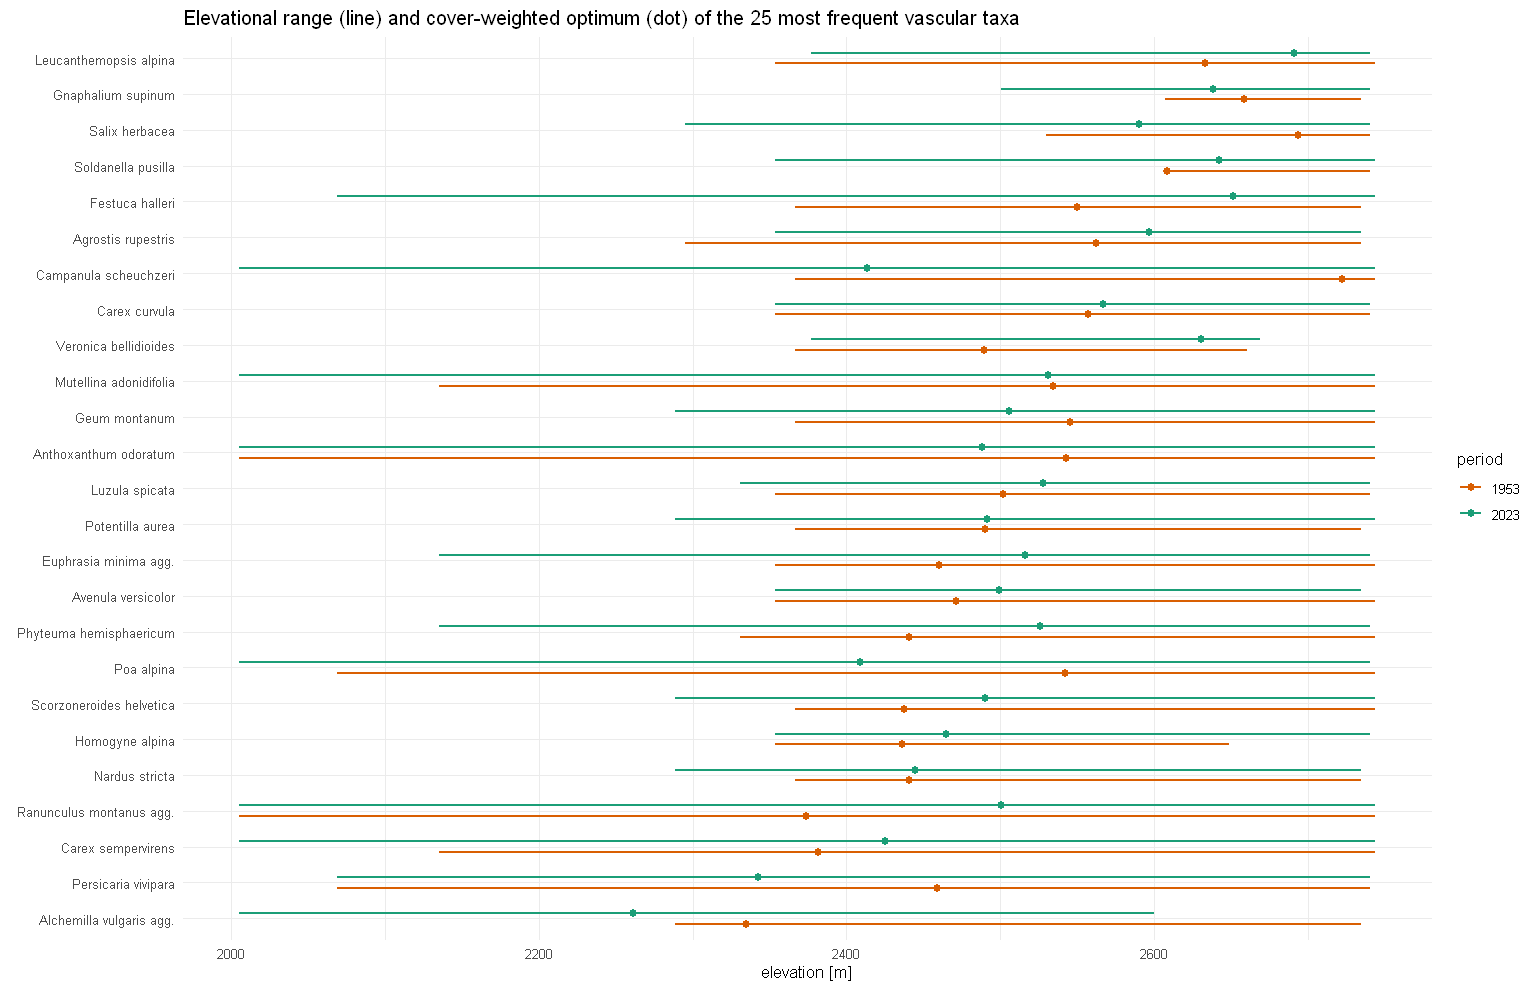

In [116]:
options(repr.plot.width = 14, repr.plot.height = 9)

top25 <- sp_overview %>% filter(group == "vascular") %>% slice_max(n_plots, n = 25, with_ties = FALSE) %>% pull(taxon)

rng <- long %>% filter(cover > 0, taxon %in% top25) %>%
  group_by(taxon, period) %>%
  summarise(n = n(), emin = min(elevation), emax = max(elevation),
            opt = weighted.mean(elevation, cover), .groups = "drop")
ord <- rng %>% group_by(taxon) %>% summarise(o = mean(opt)) %>% arrange(o) %>% pull(taxon)

ggplot(rng, aes(y = factor(taxon, levels = ord), colour = period)) +
  geom_linerange(aes(xmin = emin, xmax = emax), position = position_dodge(width = .6), linewidth = .8) +
  geom_point(aes(x = opt), position = position_dodge(width = .6), size = 2) +
  scale_colour_manual(values = period_cols) +
  labs(x = "elevation [m]", y = NULL,
       title = "Elevational range (line) and cover-weighted optimum (dot) of the 25 most frequent vascular taxa")

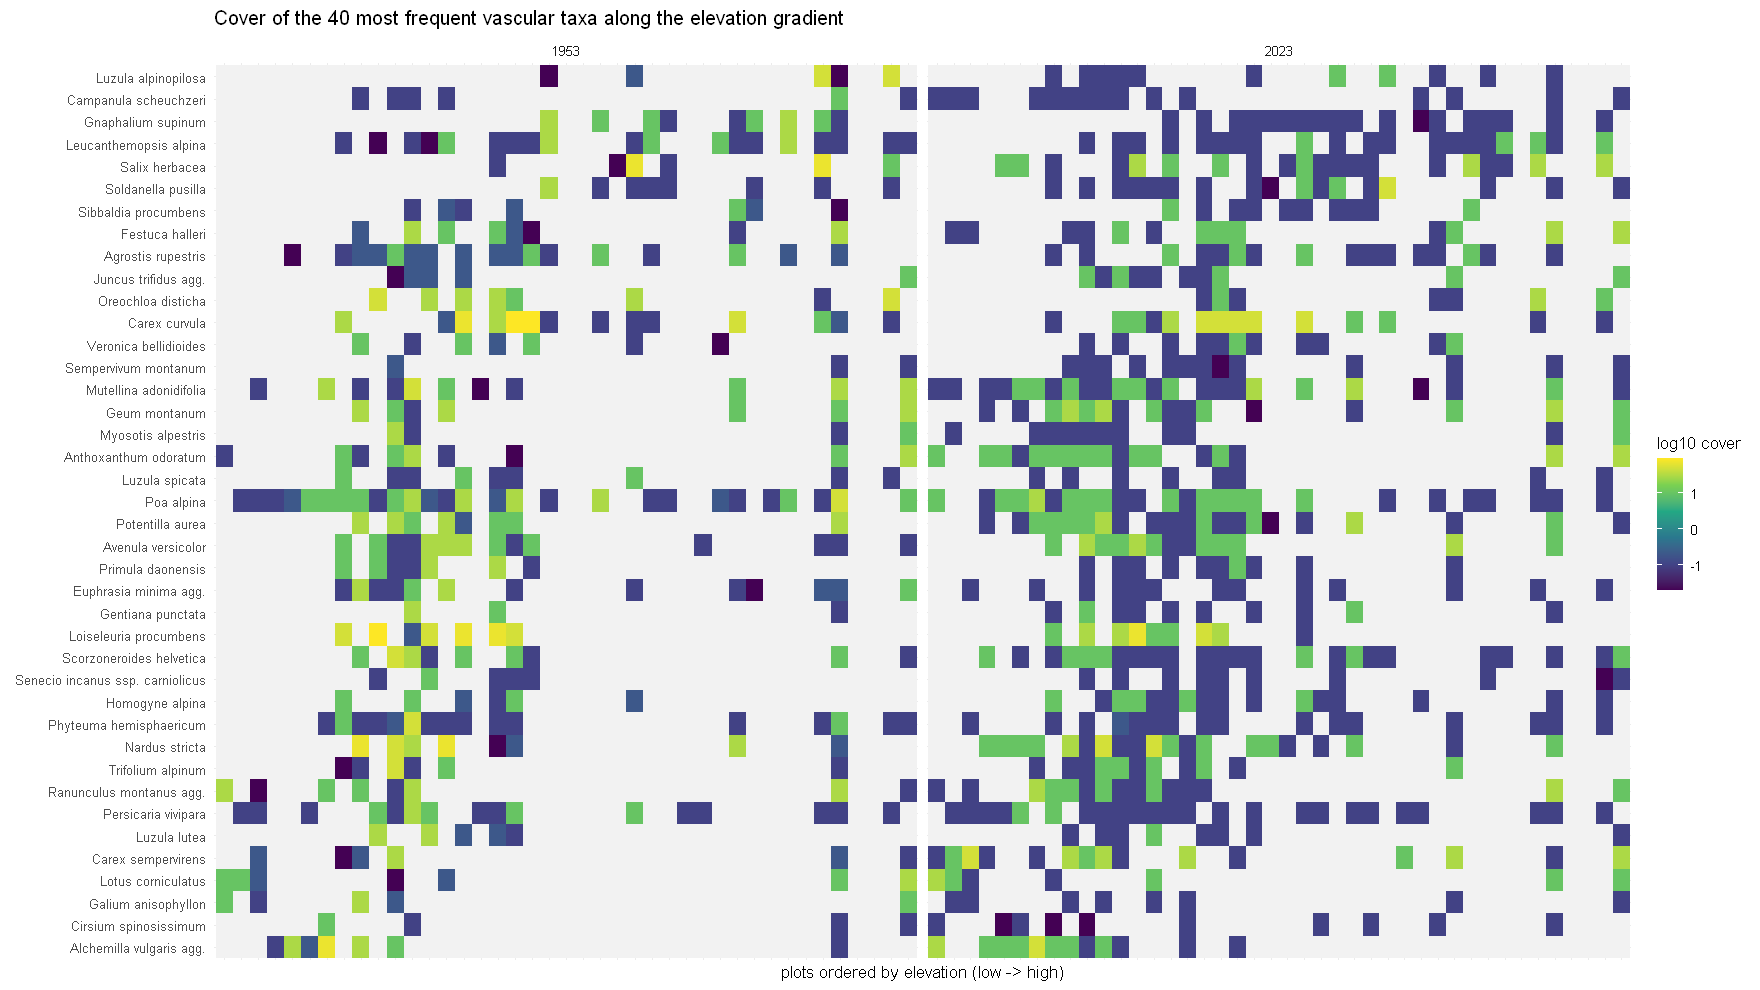

In [117]:
options(repr.plot.width = 16, repr.plot.height = 9)

top40 <- sp_overview %>% filter(group == "vascular") %>% slice_max(n_plots, n = 40, with_ties = FALSE) %>% pull(taxon)
ord40 <- opt_all %>% filter(taxon %in% top40) %>% arrange(opt) %>% pull(taxon)

long %>% filter(taxon %in% top40) %>%
  mutate(taxon = factor(taxon, levels = ord40),
         plot_ord = reorder(plot_id, elevation),
         log_cover = if_else(cover > 0, log10(cover), NA_real_)) %>%
  ggplot(aes(plot_ord, taxon, fill = log_cover)) + geom_tile() +
  facet_wrap(~ period, scales = "free_x") +
  scale_fill_viridis_c(na.value = "grey95", name = "log10 cover") +
  labs(x = "plots ordered by elevation (low -> high)", y = NULL,
       title = "Cover of the 40 most frequent vascular taxa along the elevation gradient") +
  theme(axis.text.x = element_blank())

type,n_events,n_taxa,median_rel_m,mean_rel_m,p_wilcoxon
gained,304,55,12.399,-12.100,0.841
lost,155,51,16.114,-2.214,0.903


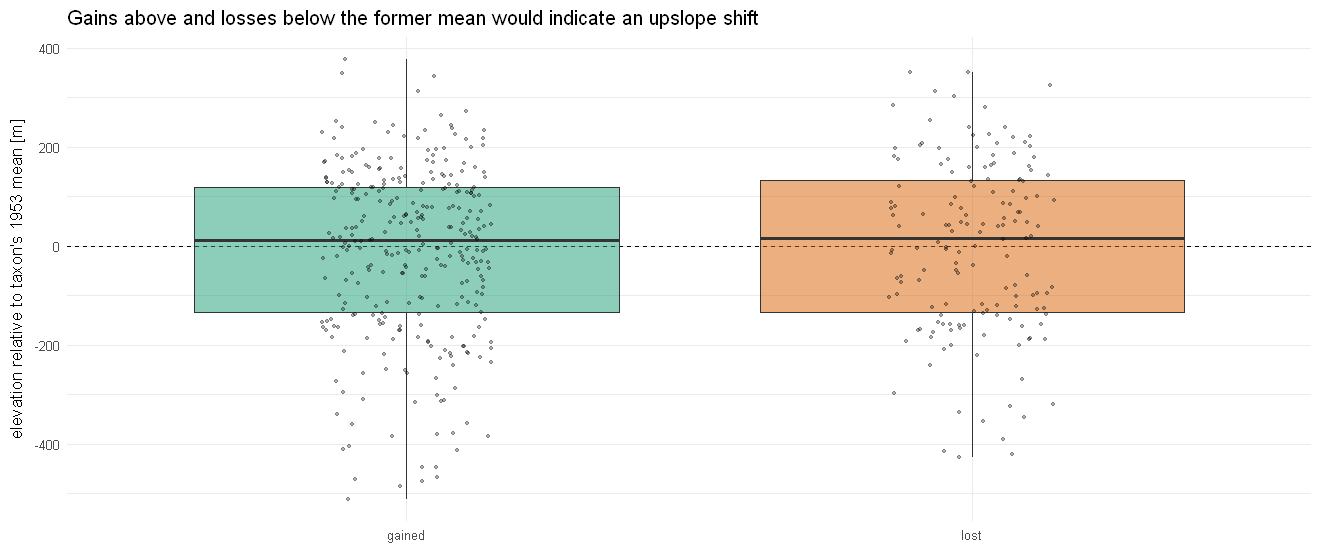

In [118]:
options(repr.plot.width = 12, repr.plot.height = 5)

# Where do gains and losses happen relative to the taxon's former distribution?
elev_ev <- map_dfr(colnames(A)[colSums(A > 0) >= 5], function(tx) {
  m0 <- mean(elev_pair[A[, tx] > 0])        # mean elevation of the taxon in 1953
  bind_rows(
    tibble(taxon = tx, type = "lost",   rel = elev_pair[A[, tx] > 0 & B[, tx] == 0] - m0),
    tibble(taxon = tx, type = "gained", rel = elev_pair[A[, tx] == 0 & B[, tx] > 0] - m0))
})

elev_ev %>% group_by(type) %>%
  summarise(n_events = n(), n_taxa = n_distinct(taxon), median_rel_m = median(rel), mean_rel_m = mean(rel),
            p_wilcoxon = wilcox.test(rel, mu = 0, exact = FALSE)$p.value, .groups = "drop") %>%
  kable(digits = 3, caption = "Elevation of gain/loss events relative to the taxon's 1953 mean elevation (taxa in >= 5 plots in 1953). Events from the same taxon are not independent.")

ggplot(elev_ev, aes(type, rel, fill = type)) +
  geom_hline(yintercept = 0, linetype = 2) +
  geom_boxplot(outlier.shape = NA, alpha = .5) + geom_jitter(width = .15, alpha = .3, size = 1) +
  scale_fill_manual(values = c(lost = "#D95F02", gained = "#1B9E77"), guide = "none") +
  labs(x = NULL, y = "elevation relative to taxon's 1953 mean [m]",
       title = "Gains above and losses below the former mean would indicate an upslope shift")

Taxa modelled: 43 


taxon,n,beta_elev,beta_period,beta_int,p_period,p_int,p_period_adj,p_int_adj
Luzula alpinopilosa,16,2.7100,2.400,-2.660,0.10100,0.0247,0.2550,0.948
Mutellina adonidifolia,35,-0.3390,1.580,-1.140,0.00263,0.0565,0.0303,0.948
Campanula scheuchzeri,21,-0.0882,1.110,-1.040,0.01860,0.0680,0.0998,0.948
Soldanella pusilla,25,1.6500,1.630,-1.340,0.03220,0.0944,0.1260,0.948
Agrostis rupestris,33,-0.1420,-0.192,0.730,0.74800,0.1300,0.8580,0.948
Myosotis alpestris,15,0.2050,1.110,-0.901,0.04370,0.1570,0.1500,0.948
Alchemilla vulgaris agg.,19,-0.8350,0.576,-0.858,0.13800,0.1920,0.3290,0.948
Anthoxanthum odoratum,26,-0.5310,0.949,-0.679,0.04540,0.2210,0.1500,0.948
Carex sempervirens,21,-0.4330,1.180,-0.644,0.01650,0.2550,0.0998,0.948
Salix herbacea,26,1.3200,2.110,-0.913,0.00075,0.2640,0.0193,0.948


taxon,n,beta_elev,beta_period,beta_int,p_period,p_int,p_period_adj,p_int_adj
Salix herbacea,26,1.3200,2.110,-0.9130,0.000750,0.2640,0.0193,0.948
Scorzoneroides helvetica,33,-0.0483,1.560,0.1340,0.000896,0.7840,0.0193,0.948
Mutellina adonidifolia,35,-0.3390,1.580,-1.1400,0.002630,0.0565,0.0303,0.948
Potentilla aurea,29,-0.2400,1.440,-0.0908,0.002820,0.8540,0.0303,0.948
Nardus stricta,28,-0.1140,1.340,-0.4150,0.005330,0.4120,0.0459,0.948
Homogyne alpina,22,-0.1980,1.290,0.3160,0.014000,0.5550,0.0998,0.948
Carex sempervirens,21,-0.4330,1.180,-0.6440,0.016500,0.2550,0.0998,0.948
Campanula scheuchzeri,21,-0.0882,1.110,-1.0400,0.018600,0.0680,0.0998,0.948
Gnaphalium supinum,27,1.9000,1.450,-0.4270,0.023300,0.6780,0.1110,0.948
Geum montanum,23,0.0441,1.090,-0.3980,0.029500,0.4460,0.1260,0.948


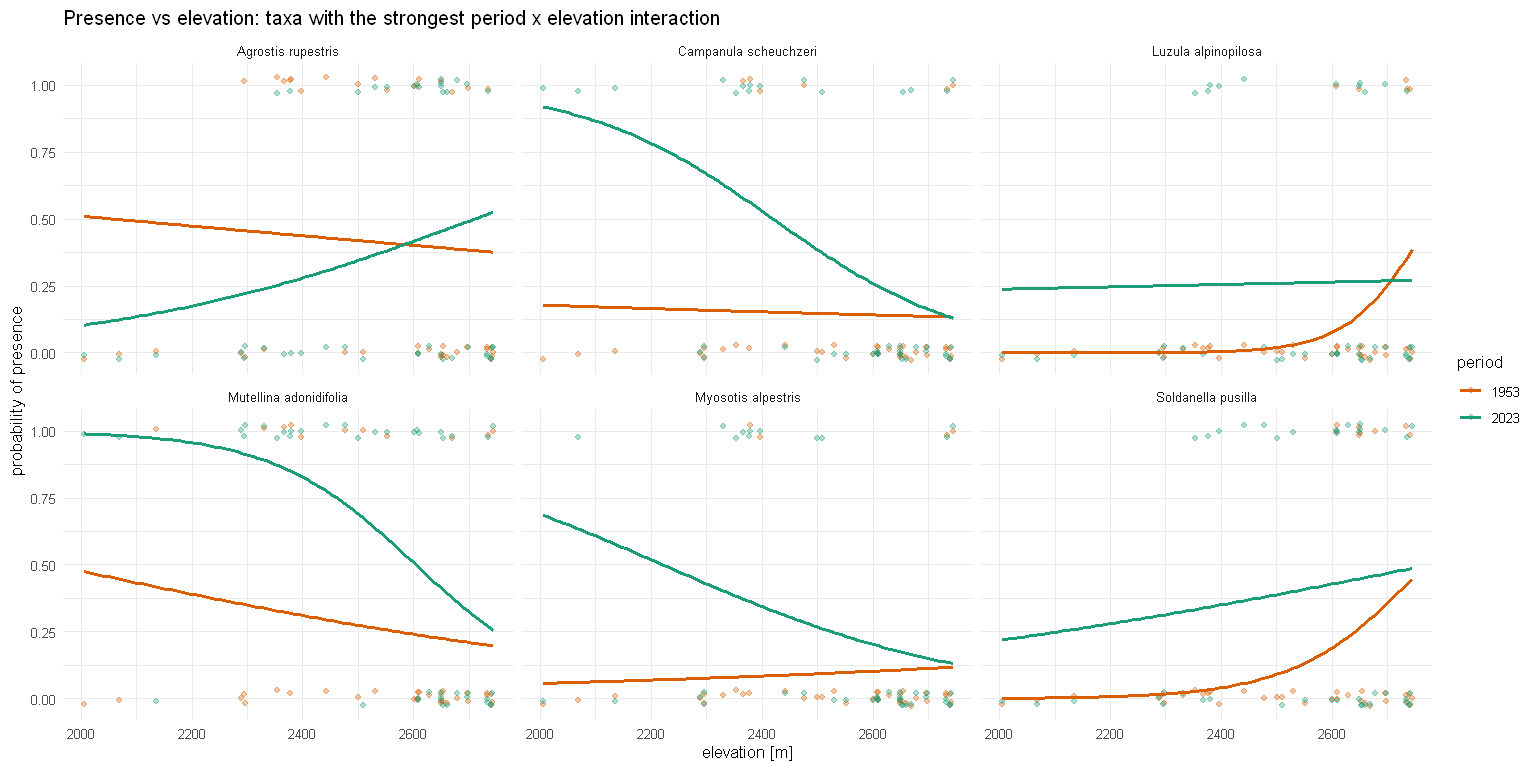

In [119]:
options(repr.plot.width = 14, repr.plot.height = 7)

tx_glm <- sp_overview %>% filter(freq_1953 >= 4, freq_2023 >= 4, n_plots >= 12) %>% pull(taxon)
cat("Taxa modelled:", length(tx_glm), "\n")

fit_one <- function(tx) {
  d <- dat_el %>% mutate(y = as.integer(comm[plot_id, tx] > 0))
  tryCatch({
    m_e <- suppressWarnings(glm(y ~ elev_z,          data = d, family = binomial))
    m_0 <- suppressWarnings(glm(y ~ elev_z + period, data = d, family = binomial))
    m_1 <- suppressWarnings(glm(y ~ elev_z * period, data = d, family = binomial))
    tibble(taxon = tx, n = sum(d$y),
           beta_elev   = unname(coef(m_1)["elev_z"]),
           beta_period = unname(coef(m_1)["period2023"]),
           beta_int    = unname(coef(m_1)["elev_z:period2023"]),
           p_period = anova(m_e, m_0, test = "Chisq")$`Pr(>Chi)`[2],
           p_int    = anova(m_0, m_1, test = "Chisq")$`Pr(>Chi)`[2])
  }, error = function(e) tibble(taxon = tx))
}

glm_res <- map_dfr(tx_glm, fit_one) %>%
  mutate(p_period_adj = p.adjust(p_period, "BH"), p_int_adj = p.adjust(p_int, "BH"))

glm_res %>% arrange(p_int) %>% head(15) %>% mutate(across(where(is.numeric), ~ signif(.x, 3))) %>%
  kable(caption = "Taxa whose elevation response changed most (period x elevation interaction)")
glm_res %>% arrange(p_period) %>% head(15) %>% mutate(across(where(is.numeric), ~ signif(.x, 3))) %>%
  kable(caption = "Taxa whose occurrence changed most at a given elevation (period effect)")
write_csv(glm_res, "outputs/species_elevation_glm.csv")

# response curves for the 6 taxa with the strongest interaction
sel <- glm_res %>% filter(!is.na(p_int)) %>% arrange(p_int) %>% slice_head(n = 6) %>% pull(taxon)
grid0 <- expand_grid(elevation = seq(min(dat_el$elevation), max(dat_el$elevation), length.out = 100),
                     period = factor(c("1953", "2023"), levels = c("1953", "2023"))) %>%
  mutate(elev_z = (elevation - el_mean) / el_sd)

curves <- map_dfr(sel, function(tx) {
  d <- dat_el %>% mutate(y = as.integer(comm[plot_id, tx] > 0))
  m1 <- suppressWarnings(glm(y ~ elev_z * period, data = d, family = binomial))
  g <- grid0; g$prob <- predict(m1, newdata = g, type = "response"); g$taxon <- tx; g
})
obs_pts <- map_dfr(sel, function(tx) dat_el %>% mutate(y = as.integer(comm[plot_id, tx] > 0), taxon = tx))

ggplot() +
  geom_point(data = obs_pts, aes(elevation, y, colour = period), alpha = .35,
             position = position_jitter(height = .03, width = 0)) +
  geom_line(data = curves, aes(elevation, prob, colour = period), linewidth = 1) +
  facet_wrap(~ taxon) + scale_colour_manual(values = period_cols) +
  labs(x = "elevation [m]", y = "probability of presence",
       title = "Presence vs elevation: taxa with the strongest period x elevation interaction")

### Summary of elevation optimum shifts

Section 6.2 already gives the shift of each taxon's elevational optimum. Here is the same result presented against the taxa's position on the gradient:

`geom_smooth()` using formula = 'y ~ x'


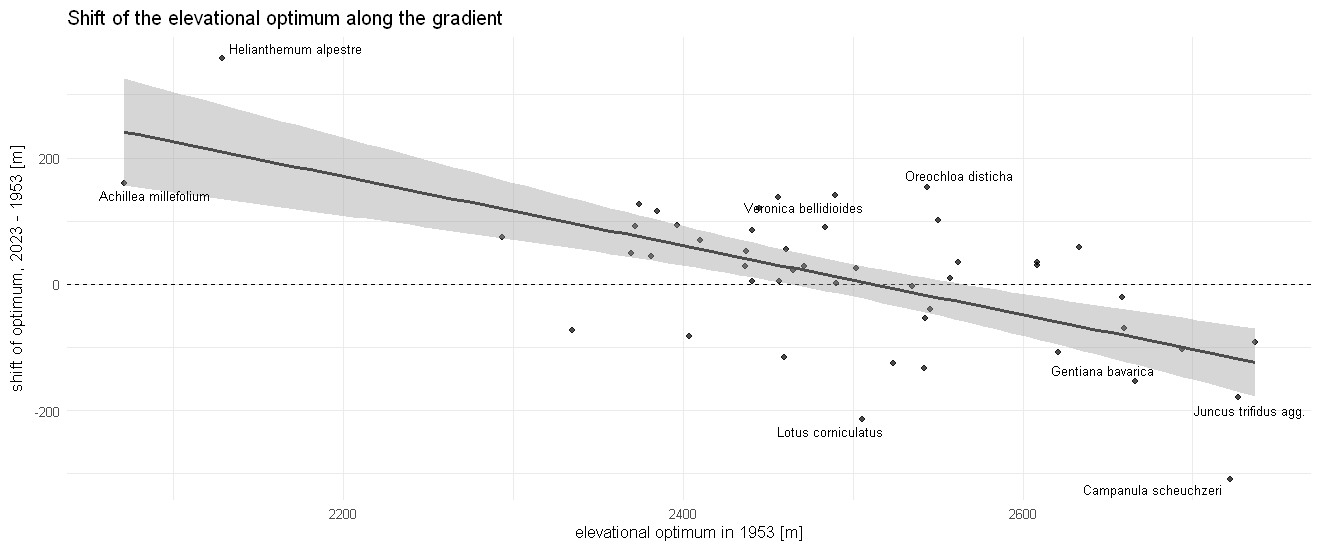

In [120]:
options(repr.plot.width = 12, repr.plot.height = 5)

if (exists("optima") && nrow(optima) > 0) {
  ggplot(optima, aes(opt_1953, shift)) +
    geom_hline(yintercept = 0, linetype = 2) + geom_point(alpha = .7) +
    geom_smooth(method = "lm", colour = "grey30") +
    geom_text_repel(data = ~ slice_max(.x, abs(shift), n = 8, with_ties = FALSE), aes(label = taxon), size = 3) +
    labs(x = "elevational optimum in 1953 [m]", y = "shift of optimum, 2023 - 1953 [m]",
         title = "Shift of the elevational optimum along the gradient")
} else cat("Run section 6.2 first (object `optima`).\n")

## 10.5 Interactions between taxa

**Important:** the data are presence/cover records, not experiments, so none of the analyses below can *demonstrate* competition. Two taxa can avoid each other because they prefer different environments, not because they compete. The analyses are ordered from the weakest to the most informative signal:

1. **Pairwise co-occurrence** (hypergeometric test) inside each period, for common vascular taxa.
2. **The same after removing the elevation effect:** correlation of the residuals of `presence ~ elevation + elevation^2`. Associations that survive are less likely to be a shared response to the gradient.
3. **Checkerboard test** for the whole assemblage.
4. **Replacement analysis:** do taxa that increase tend to occur where others decrease in the same plots?

In [121]:
min_occ <- 6   # taxa must occur in >= min_occ plots and be absent from >= min_occ plots of the period

assoc_period <- function(per) {
  ids <- env_sp$plot_id[env_sp$period == per]
  P <- comm[ids, , drop = FALSE] > 0
  n <- nrow(P)
  keep <- colnames(P) %in% vasc_taxa & colSums(P) >= min_occ & colSums(P) <= n - min_occ
  Pn <- P[, keep, drop = FALSE] * 1
  S <- colnames(Pn); ns <- colSums(Pn)

  obs <- crossprod(Pn)                    # co-occurrence counts
  idx <- which(upper.tri(obs), arr.ind = TRUE)
  res <- tibble(i = idx[, 1], j = idx[, 2]) %>%
    mutate(sp1 = S[i], sp2 = S[j], obs = obs[cbind(i, j)], n1 = ns[i], n2 = ns[j],
           expected = n1 * n2 / n,
           p_seg = phyper(obs, n1, n - n1, n2),                          # fewer co-occurrences than expected
           p_agg = phyper(obs - 1, n1, n - n1, n2, lower.tail = FALSE))  # more than expected
  res <- res %>% mutate(
    p_seg_adj = p.adjust(p_seg, "BH"), p_agg_adj = p.adjust(p_agg, "BH"),
    type = case_when(p_seg_adj < .05 ~ "segregated", p_agg_adj < .05 ~ "aggregated", TRUE ~ "n.s."))

  # correlation of presence, raw and after removing the elevation effect
  d <- env_sp %>% filter(plot_id %in% ids) %>% mutate(elev_z = (elevation - el_mean) / el_sd)
  R <- sapply(S, function(tx) {
    y <- as.integer(Pn[, tx])
    m <- suppressWarnings(glm(y ~ elev_z + I(elev_z^2), data = d, family = binomial))
    y - fitted(m)
  })
  rc <- cor(R); rawc <- cor(Pn)
  res %>% mutate(
    r_raw = rawc[cbind(i, j)], r_resid = rc[cbind(i, j)],
    p_resid = 2 * pt(-abs(r_resid * sqrt((n - 2) / (1 - r_resid^2))), n - 2)) %>%
    mutate(p_resid_adj = p.adjust(p_resid, "BH"), period = per, n_plots = n)
}

assoc_all <- map_dfr(c("1953", "2023"), assoc_period)

assoc_all %>% group_by(period) %>%
  summarise(n_plots = first(n_plots), n_taxa = n_distinct(c(sp1, sp2)), n_pairs = n(),
            segregated_raw = sum(type == "segregated"), aggregated_raw = sum(type == "aggregated"),
            neg_after_elevation = sum(p_resid_adj < .05 & r_resid < 0, na.rm = TRUE),
            pos_after_elevation = sum(p_resid_adj < .05 & r_resid > 0, na.rm = TRUE), .groups = "drop") %>%
  kable(caption = "Significant pairs (FDR < 0.05) before and after removing the elevation effect")

period,n_plots,n_taxa,n_pairs,segregated_raw,aggregated_raw,neg_after_elevation,pos_after_elevation
1953,41,38,703,0,142,5,160
2023,42,61,1830,0,131,18,129


period,sp1,sp2,obs,expected,r_raw,r_resid,p_seg_adj,p_resid_adj
1953,Leucanthemopsis alpina,Sesleria caerulea,0,3.24,-0.422,-0.4020,1.000,0.04130
1953,Erigeron uniflorus,Leucanthemopsis alpina,0,3.24,-0.422,-0.3200,1.000,0.12800
1953,Avenula versicolor,Poa supina,0,3.07,-0.382,-0.4510,1.000,0.01700
1953,Carex curvula,Poa supina,0,3.07,-0.382,-0.3800,1.000,0.05680
1953,Agrostis rupestris,Sesleria caerulea,0,2.90,-0.382,-0.2740,1.000,0.21700
1953,Festuca pumila,Leucanthemopsis alpina,0,2.78,-0.385,-0.3470,1.000,0.09130
1953,Phyteuma hemisphaericum,Sesleria caerulea,0,2.73,-0.363,-0.2990,1.000,0.16400
1953,Agrostis rupestris,Festuca pumila,0,2.49,-0.348,-0.2710,1.000,0.22100
1953,Poa alpina,Sesleria caerulea,2,4.61,-0.357,-0.3270,1.000,0.11700
1953,Festuca pumila,Phyteuma hemisphaericum,0,2.34,-0.331,-0.2720,1.000,0.21900


period,sp1,sp2,obs,expected,r_raw,r_resid,p_agg_adj,p_resid_adj
1953,Campanula scheuchzeri,Geum montanum,6,1.02,0.912,0.913,0.000487,0.00e+00
1953,Festuca pumila,Sesleria caerulea,6,1.02,0.912,0.913,0.000487,0.00e+00
1953,Festuca halleri,Nardus stricta,7,1.56,0.845,0.835,0.000487,0.00e+00
1953,Nardus stricta,Potentilla aurea,7,1.56,0.845,0.825,0.000487,0.00e+00
1953,Phleum rhaeticum,Ranunculus montanus agg.,6,1.17,0.841,0.843,0.000876,0.00e+00
1953,Geum montanum,Mutellina adonidifolia,7,1.88,0.749,0.755,0.001310,8.00e-07
1953,Avenula versicolor,Phyteuma hemisphaericum,12,5.46,0.689,0.657,0.001310,7.57e-05
1953,Anthoxanthum odoratum,Campanula scheuchzeri,6,1.32,0.781,0.793,0.001310,1.00e-07
1953,Anthoxanthum odoratum,Trifolium alpinum,6,1.32,0.781,0.780,0.001310,1.00e-07
1953,Homogyne alpina,Luzula spicata,6,1.32,0.781,0.725,0.001310,4.20e-06


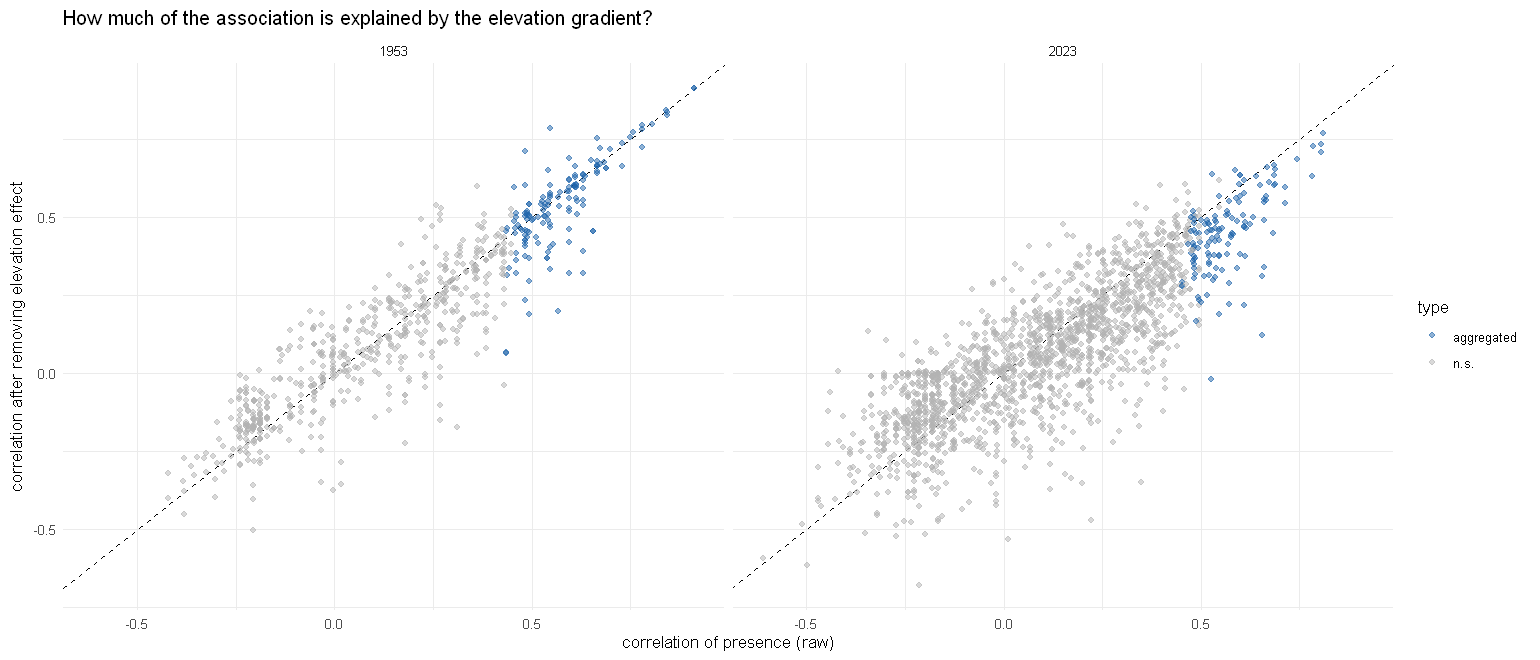

In [122]:
options(repr.plot.width = 14, repr.plot.height = 6)

ggplot(assoc_all, aes(r_raw, r_resid, colour = type)) +
  geom_abline(linetype = 2) + geom_point(alpha = .5) + facet_wrap(~ period) +
  scale_colour_manual(values = c("segregated" = "#B2182B", "aggregated" = "#2166AC", "n.s." = "grey70")) +
  labs(x = "correlation of presence (raw)", y = "correlation after removing elevation effect",
       title = "How much of the association is explained by the elevation gradient?")

assoc_all %>% group_by(period) %>% slice_min(p_seg, n = 10, with_ties = FALSE) %>% ungroup() %>%
  select(period, sp1, sp2, obs, expected, r_raw, r_resid, p_seg_adj, p_resid_adj) %>%
  mutate(across(where(is.numeric), ~ signif(.x, 3))) %>%
  kable(caption = "Most segregated pairs per period (fewer co-occurrences than expected)")
assoc_all %>% group_by(period) %>% slice_min(p_agg, n = 10, with_ties = FALSE) %>% ungroup() %>%
  select(period, sp1, sp2, obs, expected, r_raw, r_resid, p_agg_adj, p_resid_adj) %>%
  mutate(across(where(is.numeric), ~ signif(.x, 3))) %>%
  kable(caption = "Most aggregated pairs per period (more co-occurrences than expected)")
write_csv(assoc_all, "outputs/species_pair_associations.csv")

Warning message:
"ggrepel: 5 unlabeled data points (too many overlaps). Consider increasing max.overlaps"
Warning message:
"ggrepel: 22 unlabeled data points (too many overlaps). Consider increasing max.overlaps"


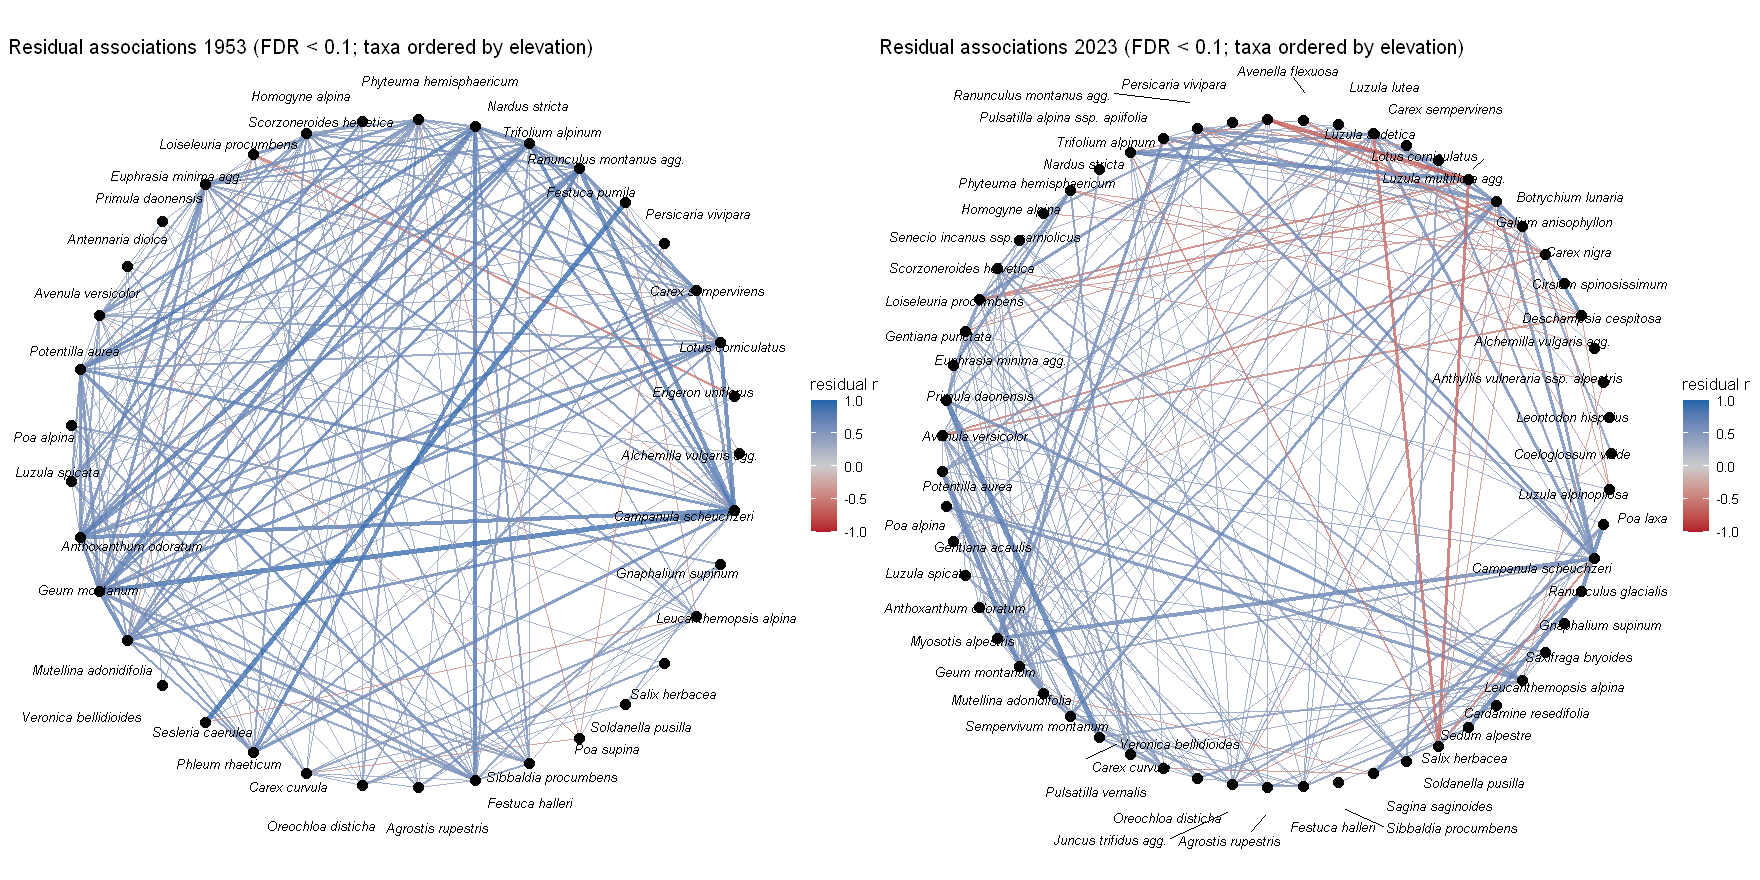

In [123]:
options(repr.plot.width = 16, repr.plot.height = 8)

# network of associations that persist after removing the elevation effect
net_plot <- function(per, thr = 0.1) {
  e <- assoc_all %>% filter(period == per, !is.na(p_resid_adj), p_resid_adj < thr)
  if (nrow(e) == 0) {
    return(ggplot() + annotate("text", x = 0, y = 0, label = paste("No pair with FDR <", thr)) +
             theme_void() + labs(title = paste("Residual associations,", per)))
  }
  nodes <- unique(c(e$sp1, e$sp2))
  nodes <- nodes[order(opt_all$opt[match(nodes, opt_all$taxon)])]   # order by elevation optimum
  ang <- 2 * pi * (seq_along(nodes) - 1) / length(nodes)
  nd <- tibble(taxon = nodes, x = cos(ang), y = sin(ang))
  e <- e %>%
    left_join(nd %>% rename(sp1 = taxon, x1 = x, y1 = y), by = "sp1") %>%
    left_join(nd %>% rename(sp2 = taxon, x2 = x, y2 = y), by = "sp2")
  ggplot() +
    geom_segment(data = e, aes(x = x1, y = y1, xend = x2, yend = y2, colour = r_resid, linewidth = abs(r_resid)), alpha = .8) +
    geom_point(data = nd, aes(x, y), size = 3) +
    geom_text_repel(data = nd, aes(x * 1.08, y * 1.08, label = taxon), size = 3, fontface = "italic") +
    scale_colour_gradient2(low = "#B2182B", mid = "grey80", high = "#2166AC", limits = c(-1, 1)) +
    scale_linewidth(range = c(.3, 1.6), guide = "none") +
    coord_equal(clip = "off") + theme_void() +
    labs(colour = "residual r", title = paste0("Residual associations ", per, " (FDR < ", thr, "; taxa ordered by elevation)"))
}
net_plot("1953") + net_plot("2023")

Pairs tested in both periods: 465 
Spearman correlation of residual associations between periods: 0.35 


sp1,sp2,r1953,r2023,delta
Euphrasia minima agg.,Geum montanum,0.66,-0.22,-0.88
Festuca halleri,Nardus stricta,0.83,0.05,-0.78
Euphrasia minima agg.,Nardus stricta,0.58,-0.18,-0.76
Lotus corniculatus,Trifolium alpinum,0.60,-0.10,-0.70
Festuca halleri,Sibbaldia procumbens,0.56,-0.12,-0.68
Homogyne alpina,Luzula spicata,0.72,0.04,-0.68
Oreochloa disticha,Soldanella pusilla,0.35,-0.32,-0.68
Agrostis rupestris,Nardus stricta,0.36,-0.29,-0.65
Mutellina adonidifolia,Primula daonensis,-0.29,0.49,0.78
Loiseleuria procumbens,Lotus corniculatus,-0.40,0.23,0.64


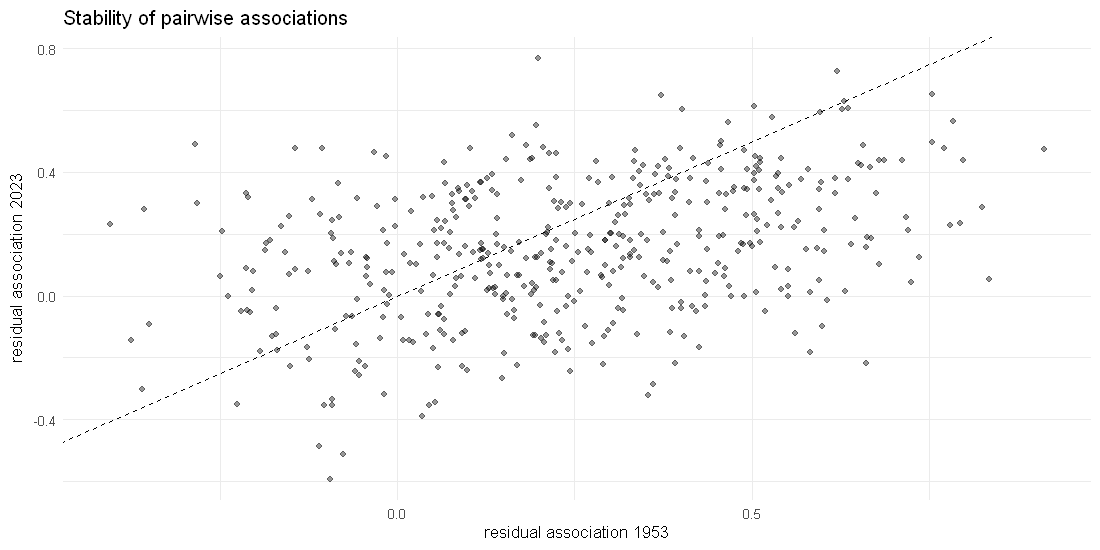

In [124]:
options(repr.plot.width = 10, repr.plot.height = 5)

# do the associations persist between periods?
assoc_chg <- assoc_all %>% select(period, sp1, sp2, r_resid) %>%
  pivot_wider(names_from = period, values_from = r_resid, names_prefix = "r") %>%
  drop_na() %>% mutate(delta = r2023 - r1953)

cat("Pairs tested in both periods:", nrow(assoc_chg), "\n")
cat("Spearman correlation of residual associations between periods:",
    round(cor(assoc_chg$r1953, assoc_chg$r2023, method = "spearman"), 2), "\n")

ggplot(assoc_chg, aes(r1953, r2023)) + geom_abline(linetype = 2) + geom_point(alpha = .4) +
  labs(x = "residual association 1953", y = "residual association 2023",
       title = "Stability of pairwise associations")

bind_rows(slice_min(assoc_chg, delta, n = 8, with_ties = FALSE), slice_max(assoc_chg, delta, n = 8, with_ties = FALSE)) %>%
  mutate(across(where(is.numeric), ~ round(.x, 2))) %>%
  kable(caption = "Pairs whose association changed most (2023 - 1953); negative = became more segregated")

### Replacement analysis

For the 30 most frequent vascular taxa, we compute the change in cover in every paired plot (2023 - 1953), then correlate these changes across plots for each pair of taxa. A **negative** correlation means that where one taxon increased, the other tended to decrease, which is what displacement or replacement would look like. It can also come from different responses to grazing or microclimate, and from the fact that covers compete for the same plot space. Treat strongly negative pairs as hypotheses.

sp1,sp2,rho,p,p_adj
Agrostis rupestris,Avenula versicolor,-0.593,4.44e-05,0.00966
Geum montanum,Loiseleuria procumbens,-0.500,8.72e-04,0.03740
Geum montanum,Luzula spicata,-0.497,9.47e-04,0.03740
Persicaria vivipara,Trifolium alpinum,-0.441,3.89e-03,0.11700
Soldanella pusilla,Luzula spicata,-0.439,4.07e-03,0.11700
Luzula spicata,Luzula alpinopilosa,-0.435,4.48e-03,0.11700
Ranunculus montanus agg.,Primula daonensis,-0.398,9.92e-03,0.22600
Persicaria vivipara,Avenula versicolor,-0.389,1.19e-02,0.23100
Festuca halleri,Loiseleuria procumbens,-0.386,1.27e-02,0.23100
Poa alpina,Soldanella pusilla,-0.359,2.13e-02,0.27200


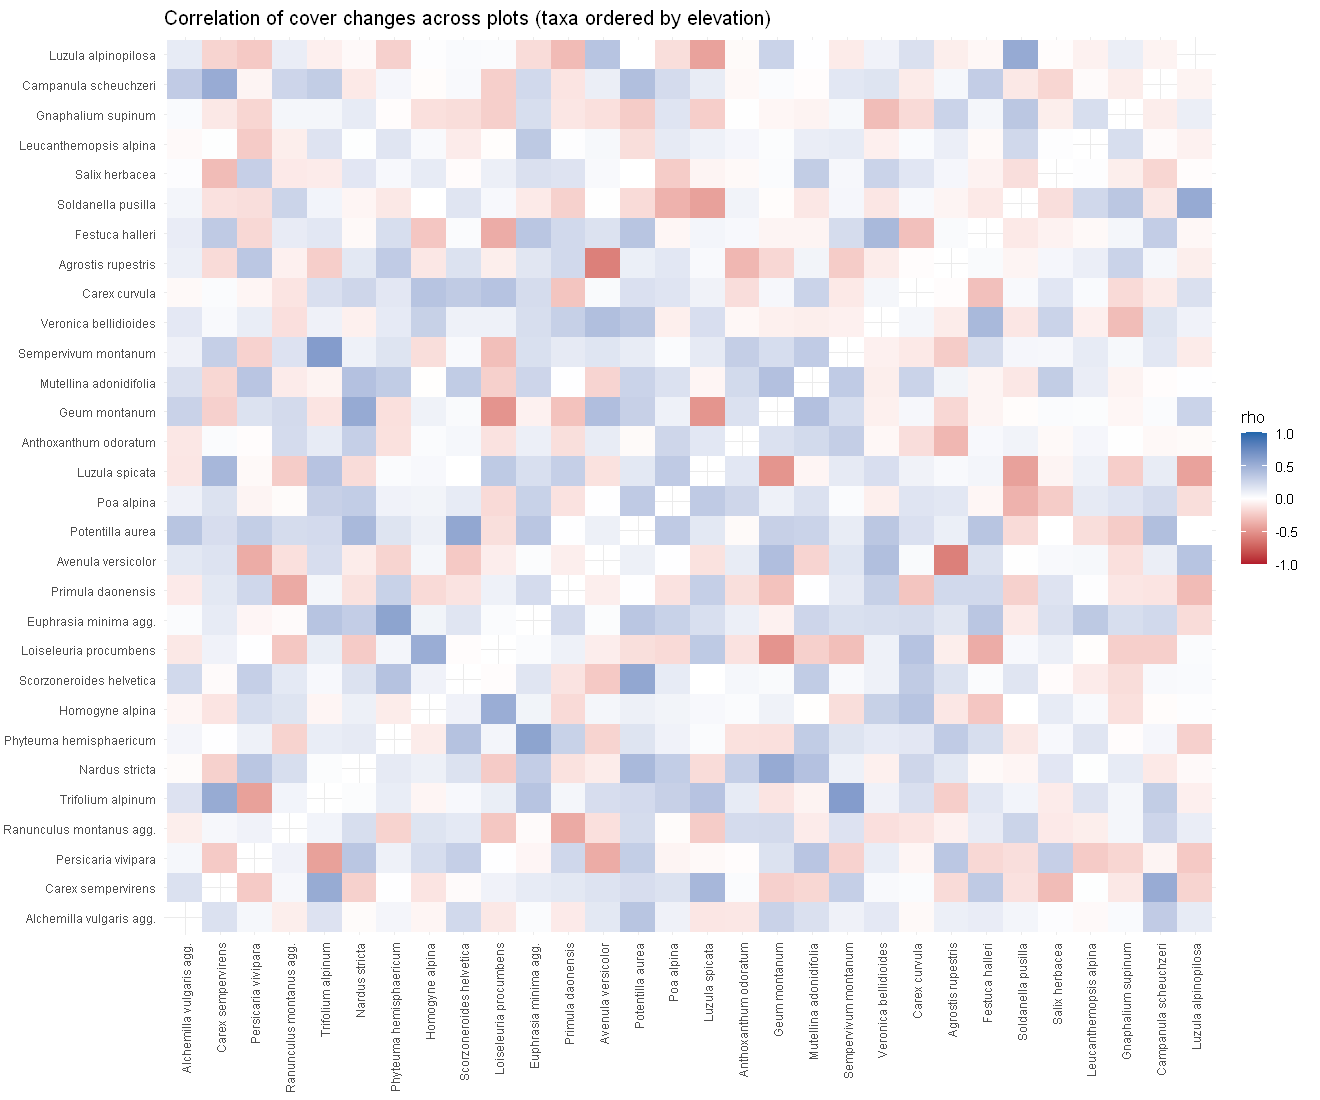

In [125]:
options(repr.plot.width = 12, repr.plot.height = 10)

dtax <- sp_change %>% filter(group == "vascular") %>%
  slice_max(occ_1953 + occ_2023, n = 30, with_ties = FALSE) %>% pull(taxon)
D <- B[, dtax] - A[, dtax]

pairs_d <- combn(dtax, 2, simplify = FALSE) %>%
  map_dfr(function(p) {
    x <- D[, p[1]]; y <- D[, p[2]]
    if (sd(x) == 0 || sd(y) == 0) return(tibble(sp1 = p[1], sp2 = p[2], rho = NA_real_, p = NA_real_))
    ct <- suppressWarnings(cor.test(x, y, method = "spearman", exact = FALSE))
    tibble(sp1 = p[1], sp2 = p[2], rho = unname(ct$estimate), p = ct$p.value)
  }) %>% mutate(p_adj = p.adjust(p, "BH"))

pairs_d %>% arrange(rho) %>% head(12) %>% mutate(across(where(is.numeric), ~ signif(.x, 3))) %>%
  kable(caption = "Most negative correlations of cover change (candidate replacement pairs)")
write_csv(pairs_d, "outputs/species_replacement_pairs.csv")

ord_d <- opt_all %>% filter(taxon %in% dtax) %>% arrange(opt) %>% pull(taxon)
bind_rows(pairs_d, pairs_d %>% rename(sp1 = sp2, sp2 = sp1)) %>%
  mutate(sp1 = factor(sp1, levels = ord_d), sp2 = factor(sp2, levels = ord_d)) %>%
  ggplot(aes(sp1, sp2, fill = rho)) + geom_tile() +
  scale_fill_gradient2(low = "#B2182B", mid = "white", high = "#2166AC", limits = c(-1, 1), na.value = "grey90") +
  labs(x = NULL, y = NULL, fill = "rho", title = "Correlation of cover changes across plots (taxa ordered by elevation)") +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = .5, size = 8), axis.text.y = element_text(size = 8))

### Checkerboard test

The C-score counts pairs of taxa that never share a plot ("checkerboard" units). It is compared with 299 matrices simulated with `quasiswap`, which keeps both the richness of every plot and the frequency of every taxon. A positive standardized effect size (z) means more segregation than the null. This takes a few minutes; raise `nsim` for a final run. The gradient in elevation inflates segregation, so interpret it together with the residual analysis above.

In [126]:
cb_period <- function(per, n_taxa = 60, nsim = 299) {
  ids <- env_sp$plot_id[env_sp$period == per]
  P <- comm[ids, colnames(comm) %in% vasc_taxa, drop = FALSE] > 0
  top <- names(sort(colSums(P), decreasing = TRUE))[seq_len(n_taxa)]
  P <- P[, top] * 1
  set.seed(42)
  o <- oecosimu(P, nestedchecker, method = "quasiswap", nsimul = nsim)
  tibble(period = per, n_plots = nrow(P), n_taxa = ncol(P),
         C_score_obs = unname(o$oecosimu$statistic), C_score_null_mean = unname(o$oecosimu$means),
         z = unname(o$oecosimu$z), p = unname(o$oecosimu$pval))
}
map_dfr(c("1953", "2023"), cb_period) %>%
  kable(digits = 3, caption = "Checkerboard test on the 60 most frequent vascular taxa of each period")

period,n_plots,n_taxa,C_score_obs,C_score_null_mean,z,p
1953,41,60,48426,45966.29,7.653,0.003
2023,42,60,88054,84471.02,12.154,0.003


### How to read section 10

- **Reliable and descriptive:** frequency, dominance, gains and losses, cover changes and elevation ranges (10.1 to 10.4).
- **Be careful with rare taxa:** if lost and gained records are mostly rare ones (see the cover-class plot in 10.2), part of the turnover is likely detection or identification noise.
- **Interactions (10.5)** are hypotheses. The associations that remain after removing the elevation effect, and the replacement pairs, are the best candidates for follow-up with a joint species distribution model (for example `Hmsc`), which can add environmental covariates and a random effect for plot.

In [127]:
options(repr.plot.width = 9, repr.plot.height = 5)
sessionInfo()

R version 4.3.3 (2024-02-29 ucrt)
Platform: x86_64-w64-mingw32/x64 (64-bit)
Running under: Windows 11 x64 (build 26300)

Matrix products: default


locale:
[1] LC_COLLATE=French_Switzerland.utf8  LC_CTYPE=French_Switzerland.utf8   
[3] LC_MONETARY=French_Switzerland.utf8 LC_NUMERIC=C                       
[5] LC_TIME=French_Switzerland.utf8    

time zone: Europe/Zurich
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] knitr_1.50      ggrepel_0.9.6   patchwork_1.3.0 vegan_2.6-10   
 [5] lattice_0.22-5  permute_0.10-0  readxl_1.4.5    lubridate_1.9.4
 [9] forcats_1.0.1   stringr_1.6.0   dplyr_1.1.4     purrr_1.0.4    
[13] readr_2.1.5     tidyr_1.3.1     tibble_3.2.1    ggplot2_4.0.2  
[17] tidyverse_2.0.0

loaded via a namespace (and not attached):
 [1] generics_0.1.4     stringi_1.8.7      hms_1.1.4          digest_0.6.37     
 [5] magrittr_2.0.3     evaluate_1.0.5     grid_4.3.3  